In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import requests

api_url = (
    "https://api.github.com/repos/"
    "mayerzhang/Cement-DCS-data/contents"
)

response = requests.get(api_url, timeout=30)
response.raise_for_status()

files = response.json()

for item in files:
    print(item["name"], "|", item["type"])

README.md | file
part1.rar | file
part2.rar | file


In [ ]:
import requests

readme_url = (
    "https://raw.githubusercontent.com/"
    "mayerzhang/Cement-DCS-data/master/README.md"
)

response = requests.get(readme_url, timeout=30)
response.raise_for_status()

print(response.text)

# Cement-DCS-data
The cement production industry is selected for experiment, utilizing data from the DCS system with a collection frequency of 3 seconds. The training data set spans from December 9, 2023, to January 1, 2024, excluding downtime.
X1: CALCINER OUTLET TEMPERATURE
X2: KILIN HEAD PRESSURE
X3: RAW FEED
X4: TOTAL OIL FLOW KILN
X5: KILN MAIN MOTOR SPEED
X6: COOLER SPEED
X7: ID FAN 1 SPEED
X8: ID FAN 2 SPEED
Y1: Kiln Current
Y2: Calciner Outlet Pressure
Y3: Cyclone1 Outlet Temperature



In [ ]:
!apt-get -qq update
!apt-get -qq install -y unrar

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import requests
from pathlib import Path

base_url = (
    "https://raw.githubusercontent.com/"
    "mayerzhang/Cement-DCS-data/master/"
)

data_dir = Path("/content/cement_data")
data_dir.mkdir(exist_ok=True)

for filename in ["part1.rar", "part2.rar"]:
    url = base_url + filename
    response = requests.get(url, timeout=120)
    response.raise_for_status()

    path = data_dir / filename
    path.write_bytes(response.content)

    print(filename, "downloaded:", path.stat().st_size, "bytes")

part1.rar downloaded: 2042842 bytes
part2.rar downloaded: 5188710 bytes


In [ ]:
import subprocess

result = subprocess.run(
    ["unrar", "t", str(data_dir / "part1.rar")],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    extract = subprocess.run(
        ["unrar", "x", "-o+", str(data_dir / "part1.rar"),
         str(data_dir / "extracted") + "/"],
        capture_output=True,
        text=True
    )

    print(extract.stdout)
    print(extract.stderr)
else:
    print("Archive test failed. Check the archive format and downloaded files.")


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Testing archive /content/cement_data/part1.rar

Testing     part1/x1_1.csv                                                 1%  OK 
Testing     part1/x2_1.csv                                                 3%  OK 
Testing     part1/x3_1.csv                                                 4%  OK 
Testing     part1/x4_1.csv                                                 6%  OK 
Testing     part1/x5_1.csv                                                 8%  OK 
Testing     part1/x6_1.csv                                                 9%  OK 
Testing     part1/x7_1.csv                                                11%  OK 
Testing     part1/x8_1.csv                                                12%  OK 
Testing     part1/y1_1.csv                                                58%  OK 
Testing     part1/y2_1.csv                             

In [ ]:
for path in (data_dir / "extracted").rglob("*"):
    if path.is_file():
        print(path.name, path.stat().st_size, "bytes")

x3_1.csv 276182 bytes
y3_1.csv 411060 bytes
x8_1.csv 271438 bytes
y1_1.csv 5159606 bytes
x1_1.csv 272782 bytes
x6_1.csv 261985 bytes
x7_1.csv 271564 bytes
y2_1.csv 5150434 bytes
x4_1.csv 267772 bytes
x5_1.csv 257018 bytes
x2_1.csv 268624 bytes


In [ ]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/content/cement_data/extracted")

files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(files))

for file in files:
    temp = pd.read_csv(file, header=None)

    print(f"\nFile: {file.name}")
    print("Shape:", temp.shape)
    display(temp.head(3))

Number of CSV files: 0


In [ ]:
from pathlib import Path

root = Path("/content/cement_data")

print("Does folder exist?", root.exists())

for path in root.rglob("*"):
    if path.is_file():
        print(path)

Does folder exist? True
/content/cement_data/part2.rar
/content/cement_data/part1.rar
/content/cement_data/extracted/part1/x3_1.csv
/content/cement_data/extracted/part1/y3_1.csv
/content/cement_data/extracted/part1/x8_1.csv
/content/cement_data/extracted/part1/y1_1.csv
/content/cement_data/extracted/part1/x1_1.csv
/content/cement_data/extracted/part1/x6_1.csv
/content/cement_data/extracted/part1/x7_1.csv
/content/cement_data/extracted/part1/y2_1.csv
/content/cement_data/extracted/part1/x4_1.csv
/content/cement_data/extracted/part1/x5_1.csv
/content/cement_data/extracted/part1/x2_1.csv


In [ ]:
csv_files = list(
    Path("/content/cement_data").rglob("*.csv")
)

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(file)

Number of CSV files: 11
/content/cement_data/extracted/part1/x3_1.csv
/content/cement_data/extracted/part1/y3_1.csv
/content/cement_data/extracted/part1/x8_1.csv
/content/cement_data/extracted/part1/y1_1.csv
/content/cement_data/extracted/part1/x1_1.csv
/content/cement_data/extracted/part1/x6_1.csv
/content/cement_data/extracted/part1/x7_1.csv
/content/cement_data/extracted/part1/y2_1.csv
/content/cement_data/extracted/part1/x4_1.csv
/content/cement_data/extracted/part1/x5_1.csv
/content/cement_data/extracted/part1/x2_1.csv


In [ ]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/content/cement_data/extracted/part1")

for file in sorted(DATA_DIR.glob("*.csv")):
    temp = pd.read_csv(file, header=None)

    print(f"\nFile: {file.name}")
    print("Shape:", temp.shape)
    print("First 3 rows:")
    display(temp.head(3))


File: x1_1.csv
Shape: (6548, 5)
First 3 rows:


,0,1,2,3,4
0,NaN,#,值,时间戳,质量
1,0.0,1,870.0,2023-12-09 10:01:31,GOOD
2,1.0,2,865.0,2023-12-09 10:02:29,GOOD



File: x2_1.csv
Shape: (6449, 5)
First 3 rows:


,0,1,2,3,4
0,NaN,#,值,时间戳,质量
1,0.0,1,-30.0,2023-12-09 10:11:24,GOOD
2,1.0,2,-40.0,2023-12-09 10:13:21,GOOD



File: x3_1.csv
Shape: (6629, 5)
First 3 rows:


...

,0,1,2,3,4
0,NaN,#,值,时间戳,质量
1,0.0,1,293.79,2023-12-09 10:00:06,GOOD
2,1.0,2,323.96,2023-12-09 10:00:12,GOOD



File: y2_1.csv
Shape: (112120, 5)
First 3 rows:


,0,1,2,3,4
0,NaN,#,值,时间戳,质量
1,0.0,1,-239.0,2023-12-09 10:00:02,GOOD
2,1.0,2,-218.75,2023-12-09 10:00:06,GOOD



File: y3_1.csv
Shape: (9632, 5)
First 3 rows:


,0,1,2,3,4
0,NaN,#,值,时间戳,质量
1,0.0,1,414.06,2023-12-09 10:01:50,GOOD
2,1.0,2,412.62,2023-12-09 10:03:11,GOOD


In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/cement_data/extracted/part1")

file_path = DATA_DIR / "x1_1.csv"

# Try reading the file with the default CSV separator
data = pd.read_csv(file_path, header=None)

print("Shape:", data.shape)
print("\nFirst 5 rows:")
display(data.head())

print("\nData types:")
print(data.dtypes)

print("\nFirst raw lines:")
with open(file_path, "r", encoding="utf-8", errors="replace") as f:
    for _ in range(5):
        print(repr(f.readline()))

Shape: (6548, 5)

First 5 rows:


,0,1,2,3,4
0,NaN,#,值,时间戳,质量
1,0.0,1,870.0,2023-12-09 10:01:31,GOOD
2,1.0,2,865.0,2023-12-09 10:02:29,GOOD
3,2.0,3,860.0,2023-12-09 10:11:24,GOOD
4,3.0,4,850.0,2023-12-09 10:11:46,GOOD



Data types:
0    float64
1     object
2     object
3     object
4     object
dtype: object

First raw lines:
',#,值,时间戳,质量\n'
'0,1,870.0,2023-12-09 10:01:31,GOOD\n'
'1,2,865.0,2023-12-09 10:02:29,GOOD\n'
'2,3,860.0,2023-12-09 10:11:24,GOOD\n'
'3,4,850.0,2023-12-09 10:11:46,GOOD\n'


In [ ]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/content/cement_data/extracted/part1")

variable_map = {
    "x1_1.csv": "calciner_outlet_temperature",
    "x2_1.csv": "kiln_head_pressure",
    "x3_1.csv": "raw_feed",
    "x4_1.csv": "kiln_oil_flow",
    "x5_1.csv": "kiln_motor_speed",
    "x6_1.csv": "cooler_speed",
    "x7_1.csv": "id_fan_1_speed",
    "x8_1.csv": "id_fan_2_speed",
    "y1_1.csv": "kiln_current",
    "y2_1.csv": "calciner_outlet_pressure",
    "y3_1.csv": "cyclone_1_outlet_temperature",
}

sensor_data = {}

for filename, sensor_name in variable_map.items():
    file_path = DATA_DIR / filename

    # The first row contains column headers
    temp = pd.read_csv(file_path)

    if temp.shape[1] != 5:
        raise ValueError(
            f"{filename}: expected 5 columns, found {temp.shape[1]}"
        )

    # Rename columns by position to avoid Chinese column names
    temp.columns = [
        "source_index",
        "record_number",
        "value",
        "timestamp",
        "quality"
    ]

    temp["value"] = pd.to_numeric(temp["value"], errors="coerce")
    temp["timestamp"] = pd.to_datetime(
        temp["timestamp"], errors="coerce"
    )
    temp["quality"] = temp["quality"].astype("string").str.strip()

    sensor_data[sensor_name] = temp

print("Successfully inspected", len(sensor_data), "sensor files.")

Successfully inspected 11 sensor files.


In [ ]:
summary = []

for sensor_name, temp in sensor_data.items():
    valid_times = temp["timestamp"].dropna().sort_values()
    intervals = valid_times.diff().dt.total_seconds()

    summary.append({
        "sensor": sensor_name,
        "rows": len(temp),
        "missing_values": temp["value"].isna().sum(),
        "missing_timestamps": temp["timestamp"].isna().sum(),
        "first_timestamp": valid_times.min(),
        "last_timestamp": valid_times.max(),
        "median_interval_seconds": intervals.median(),
        "quality_values": temp["quality"].nunique()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,sensor,rows,missing_values,missing_timestamps,first_timestamp,last_timestamp,median_interval_seconds,quality_values
0,calciner_outlet_temperature,6547,0,0,2023-12-09 10:01:31,2023-12-15 13:10:04,13.0,1
1,kiln_head_pressure,6448,0,0,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0,1
2,raw_feed,6628,0,0,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0,1
3,kiln_oil_flow,6584,0,0,2023-12-09 10:01:31,2023-12-15 13:10:04,13.0,1
4,kiln_motor_speed,6407,0,0,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0,1
5,cooler_speed,6454,0,0,2023-12-09 10:13:37,2023-12-15 13:10:04,13.0,1
6,id_fan_1_speed,6518,0,0,2023-12-09 10:30:30,2023-12-15 13:10:04,13.0,1
7,id_fan_2_speed,6515,0,0,2023-12-09 10:30:30,2023-12-15 13:10:04,13.0,1
8,kiln_current,114755,0,0,2023-12-09 10:00:06,2023-12-15 13:10:23,3.0,1
9,calciner_outlet_pressure,112119,0,0,2023-12-09 10:00:02,2023-12-15 13:10:23,3.0,1


In [ ]:
for sensor_name, temp in sensor_data.items():
    print(f"\n{sensor_name}")
    display(
        temp[["timestamp", "value", "quality"]].head(5)
    )


calciner_outlet_temperature


,timestamp,value,quality
0,2023-12-09 10:01:31,870.0,GOOD
1,2023-12-09 10:02:29,865.0,GOOD
2,2023-12-09 10:11:24,860.0,GOOD
3,2023-12-09 10:11:46,850.0,GOOD
4,2023-12-09 10:13:37,850.0,GOOD



kiln_head_pressure


,timestamp,value,quality
0,2023-12-09 10:11:24,-30.0,GOOD
1,2023-12-09 10:13:21,-40.0,GOOD
2,2023-12-09 10:42:45,-40.0,GOOD
3,2023-12-09 10:42:58,-40.0,GOOD
4,2023-12-09 10:52:43,-40.0,GOOD



raw_feed


...

,timestamp,value,quality
0,2023-12-09 10:00:06,293.79,GOOD
1,2023-12-09 10:00:12,323.96,GOOD
2,2023-12-09 10:00:15,323.49,GOOD
3,2023-12-09 10:00:20,293.79,GOOD
4,2023-12-09 10:00:23,294.72,GOOD



calciner_outlet_pressure


,timestamp,value,quality
0,2023-12-09 10:00:02,-239.00,GOOD
1,2023-12-09 10:00:06,-218.75,GOOD
2,2023-12-09 10:00:09,-251.16,GOOD
3,2023-12-09 10:00:12,-239.00,GOOD
4,2023-12-09 10:00:15,-190.39,GOOD



cyclone_1_outlet_temperature


,timestamp,value,quality
0,2023-12-09 10:01:50,414.06,GOOD
1,2023-12-09 10:03:11,412.62,GOOD
2,2023-12-09 10:05:52,399.59,GOOD
3,2023-12-09 10:08:09,396.70,GOOD
4,2023-12-09 10:10:35,400.75,GOOD


In [ ]:
import pandas as pd
import numpy as np

summary = []

for sensor_name, temp in sensor_data.items():
    data = temp.dropna(subset=["timestamp"]).sort_values("timestamp")
    times = data["timestamp"].drop_duplicates().sort_values()
    intervals = times.diff().dt.total_seconds().dropna()

    summary.append({
        "sensor": sensor_name,
        "total_rows": len(temp),
        "valid_values": temp["value"].notna().sum(),
        "good_quality_pct": round(
            temp["quality"].eq("GOOD").mean() * 100, 2
        ),
        "start_time": data["timestamp"].min(),
        "end_time": data["timestamp"].max(),
        "median_interval_sec": (
            round(intervals.median(), 1)
            if len(intervals) else np.nan
        ),
        "p90_interval_sec": (
            round(intervals.quantile(0.90), 1)
            if len(intervals) else np.nan
        )
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,sensor,total_rows,valid_values,good_quality_pct,start_time,end_time,median_interval_sec,p90_interval_sec
0,calciner_outlet_temperature,6547,6547,100.0,2023-12-09 10:01:31,2023-12-15 13:10:04,13.0,79.0
1,kiln_head_pressure,6448,6448,100.0,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0,71.0
2,raw_feed,6628,6628,100.0,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0,81.4
3,kiln_oil_flow,6584,6584,100.0,2023-12-09 10:01:31,2023-12-15 13:10:04,13.0,74.0
4,kiln_motor_speed,6407,6407,100.0,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0,67.0
5,cooler_speed,6454,6454,100.0,2023-12-09 10:13:37,2023-12-15 13:10:04,13.0,69.0
6,id_fan_1_speed,6518,6518,100.0,2023-12-09 10:30:30,2023-12-15 13:10:04,13.0,74.0
7,id_fan_2_speed,6515,6515,100.0,2023-12-09 10:30:30,2023-12-15 13:10:04,13.0,73.7
8,kiln_current,114755,114755,100.0,2023-12-09 10:00:06,2023-12-15 13:10:23,3.0,8.0
9,calciner_outlet_pressure,112119,112119,100.0,2023-12-09 10:00:02,2023-12-15 13:10:23,3.0,8.0


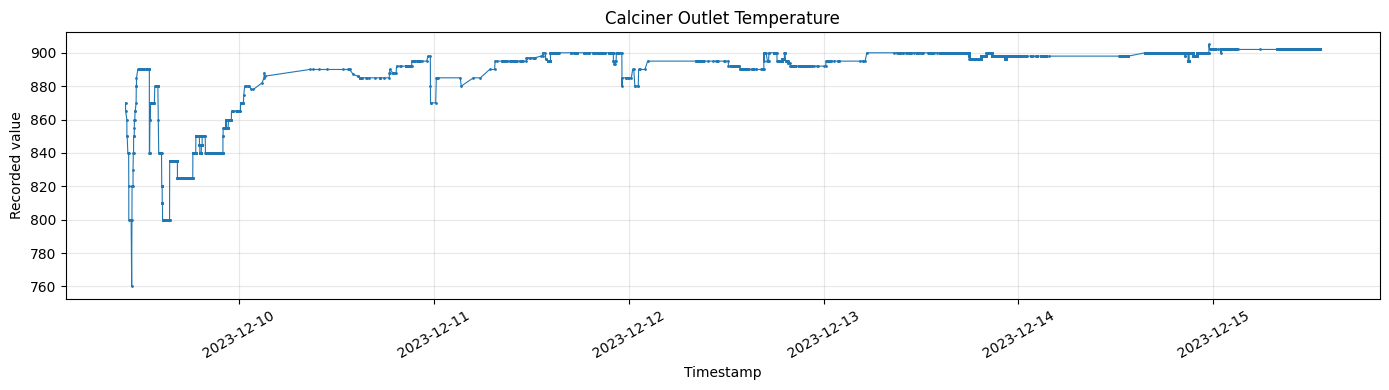

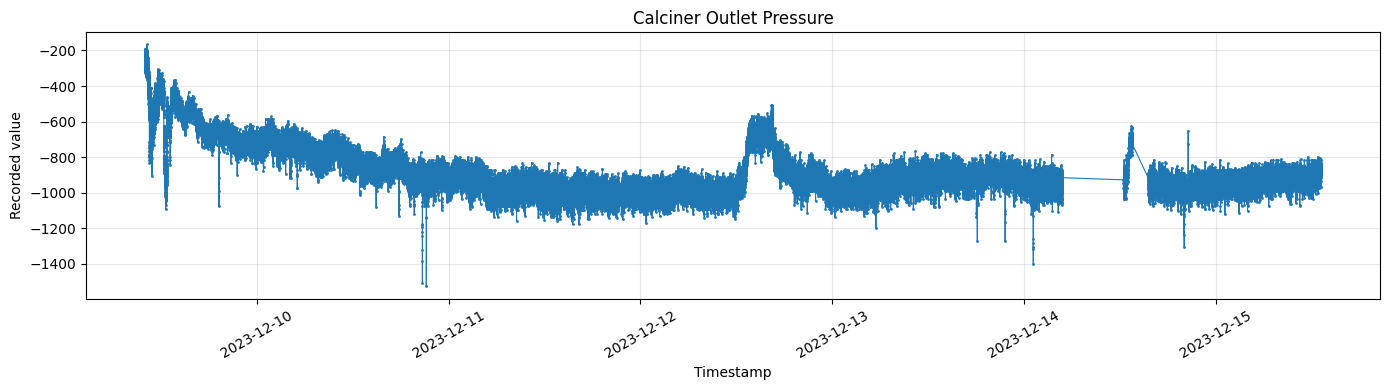

In [ ]:
import matplotlib.pyplot as plt

sensors_to_plot = [
    "calciner_outlet_temperature",
    "calciner_outlet_pressure"
]

for sensor_name in sensors_to_plot:
    temp = sensor_data[sensor_name].sort_values("timestamp")

    plt.figure(figsize=(14, 4))
    plt.plot(
        temp["timestamp"],
        temp["value"],
        marker=".",
        markersize=2,
        linewidth=0.8
    )

    plt.title(sensor_name.replace("_", " ").title())
    plt.xlabel("Timestamp")
    plt.ylabel("Recorded value")
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Use the temperature sensor timestamps as our reference timeline
target_name = "calciner_outlet_temperature"

target_data = sensor_data[target_name].copy()
target_data = target_data[
    (target_data["quality"] == "GOOD")
    & target_data["timestamp"].notna()
    & target_data["value"].notna()
].copy()

target_data = (
    target_data.sort_values("timestamp")
    .groupby("timestamp", as_index=False)["value"]
    .median()
)

target_data = target_data.rename(
    columns={"value": target_name}
)

aligned_df = target_data.copy()

# Do not use the very high-frequency current/pressure streams
# in this first experiment; we will align them separately later.
feature_names = [
    "kiln_head_pressure",
    "raw_feed",
    "kiln_oil_flow",
    "kiln_motor_speed",
    "cooler_speed",
    "id_fan_1_speed",
    "id_fan_2_speed",
    "cyclone_1_outlet_temperature",
]

for feature_name in feature_names:
    sensor = sensor_data[feature_name].copy()

    sensor = sensor[
        (sensor["quality"] == "GOOD")
        & sensor["timestamp"].notna()
        & sensor["value"].notna()
    ][["timestamp", "value"]]

    sensor = (
        sensor.sort_values("timestamp")
        .groupby("timestamp", as_index=False)["value"]
        .median()
    )

    sensor = sensor.rename(
        columns={"value": feature_name}
    )

    aligned_df = pd.merge_asof(
        aligned_df.sort_values("timestamp"),
        sensor.sort_values("timestamp"),
        on="timestamp",
        direction="backward",
        tolerance=pd.Timedelta(seconds=90)
    )

print("Aligned dataset shape:", aligned_df.shape)
print("Missing values after alignment:")
display(aligned_df.isna().sum().to_frame("missing_count"))

display(aligned_df.head())

Aligned dataset shape: (6547, 10)
Missing values after alignment:


,missing_count
timestamp,0
calciner_outlet_temperature,0
kiln_head_pressure,113
raw_feed,92
kiln_oil_flow,92
kiln_motor_speed,116
cooler_speed,115
id_fan_1_speed,109
id_fan_2_speed,109
cyclone_1_outlet_temperature,67


,timestamp,calciner_outlet_temperature,kiln_head_pressure,raw_feed,kiln_oil_flow,kiln_motor_speed,cooler_speed,id_fan_1_speed,id_fan_2_speed,cyclone_1_outlet_temperature
0,2023-12-09 10:01:31,870.0,NaN,NaN,85.0,NaN,NaN,NaN,NaN,NaN
1,2023-12-09 10:02:29,865.0,NaN,NaN,85.0,NaN,NaN,NaN,NaN,414.06
2,2023-12-09 10:11:24,860.0,-30.0,170.0,30.0,1.7,NaN,NaN,NaN,402.78
3,2023-12-09 10:11:46,850.0,-30.0,170.0,25.0,1.7,NaN,NaN,NaN,402.78
4,2023-12-09 10:13:37,850.0,-40.0,180.0,20.0,NaN,8.0,NaN,NaN,409.14


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

model_df = aligned_df.copy()

# The next recorded temperature is the prediction target
model_df["next_temperature"] = (
    model_df[target_name].shift(-1)
)

model_df["forecast_horizon_seconds"] = (
    model_df["timestamp"].shift(-1)
    - model_df["timestamp"]
).dt.total_seconds()

model_df = model_df.replace([np.inf, -np.inf], np.nan)

# Require a valid next temperature and reasonable prediction horizon
model_df = model_df[
    model_df["next_temperature"].notna()
    & model_df["forecast_horizon_seconds"].between(1, 180)
].copy()

feature_cols = [
    target_name,
    *feature_names
]

# Keep rows with a valid current temperature
model_df = model_df.dropna(subset=[target_name])

X = model_df[feature_cols]
y = model_df["next_temperature"]

split_idx = int(len(model_df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

# Baseline: predict that the next temperature equals the current temperature
baseline_predictions = X_test[target_name].to_numpy()

baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("Baseline MAE:", round(baseline_mae, 3))

Training rows: 4930
Testing rows: 1233
MAE: 1.276
RMSE: 1.697
Baseline MAE: 0.024


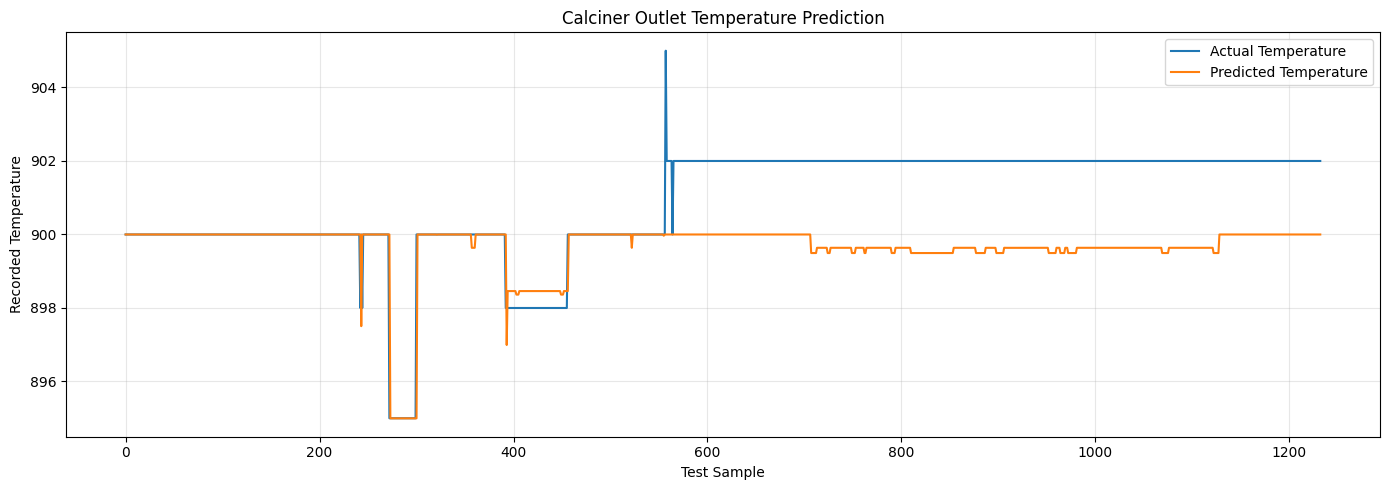

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(y_test.to_numpy(), label="Actual Temperature")
plt.plot(predictions, label="Predicted Temperature")
plt.title("Calciner Outlet Temperature Prediction")
plt.xlabel("Test Sample")
plt.ylabel("Recorded Temperature")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

print("Model Evaluation")
print("------------------------------")

print("Actual temperature range:",
      y_test.min(), "to", y_test.max())

print("Predicted temperature range:",
      predictions.min(), "to", predictions.max())

print("MAE:",
      round(mean_absolute_error(y_test, predictions), 4))

print("RMSE:",
      round(np.sqrt(mean_squared_error(y_test, predictions)), 4))

print("Actual unique values:", y_test.nunique())
print("Predicted unique values:", len(np.unique(predictions)))

Model Evaluation
------------------------------
Actual temperature range: 895.0 to 905.0
Predicted temperature range: 894.9975 to 900.0
MAE: 1.2758
RMSE: 1.6973
Actual unique values: 5
Predicted unique values: 11


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Available X_test columns:")
print(X_test.columns.tolist())

print("\nAI MAE:", round(mean_absolute_error(y_test, predictions), 4))
print("AI RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 4))

Available X_test columns:
['calciner_outlet_temperature', 'kiln_head_pressure', 'raw_feed', 'kiln_oil_flow', 'kiln_motor_speed', 'cooler_speed', 'id_fan_1_speed', 'id_fan_2_speed', 'cyclone_1_outlet_temperature']

AI MAE: 1.2758
AI RMSE: 1.6973


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# AI predictions
ai_mae = mean_absolute_error(y_test, predictions)
ai_rmse = np.sqrt(mean_squared_error(y_test, predictions))

# Baseline: assume the temperature remains unchanged
baseline_predictions = X_test["calciner_outlet_temperature"].to_numpy()

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("========== MODEL COMPARISON ==========")
print("AI MAE:", round(ai_mae, 4))
print("Baseline MAE:", round(baseline_mae, 4))
print("AI RMSE:", round(ai_rmse, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))

if ai_mae < baseline_mae:
    print("Result: AI performs better than the baseline.")
else:
    print("Result: AI does not beat the baseline yet.")


========== MODEL COMPARISON ==========
AI MAE: 1.2758
Baseline MAE: 0.0235
AI RMSE: 1.6973
Baseline RMSE: 0.289
Result: AI does not beat the baseline yet.


In [ ]:
print("========== DATA ALIGNMENT CHECK ==========")

print("\nFeature columns:")
print(X_test.columns.tolist())

print("\nFirst 10 current temperatures:")
print(X_test["calciner_outlet_temperature"].head(10).to_list())

print("\nFirst 10 actual future temperatures:")
print(y_test.head(10).to_list())

print("\nFirst 10 AI predictions:")
print(np.round(predictions[:10], 3).tolist())

print("\nFirst 10 baseline predictions:")
print(
    np.round(
        X_test["calciner_outlet_temperature"].to_numpy()[:10],
        3
    ).tolist()
)


========== DATA ALIGNMENT CHECK ==========

Feature columns:
['calciner_outlet_temperature', 'kiln_head_pressure', 'raw_feed', 'kiln_oil_flow', 'kiln_motor_speed', 'cooler_speed', 'id_fan_1_speed', 'id_fan_2_speed', 'cyclone_1_outlet_temperature']

First 10 current temperatures:
[900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0]

First 10 actual future temperatures:
[900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0]

First 10 AI predictions:
[900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0]

First 10 baseline predictions:
[900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0, 900.0]


In [ ]:
import pandas as pd
import numpy as np

print("========== TEMPERATURE VARIATION CHECK ==========")

print("\nCurrent temperature statistics:")
print(X_test["calciner_outlet_temperature"].describe())

print("\nFuture temperature statistics:")
print(y_test.describe())

print("\nNumber of unique current temperatures:",
      X_test["calciner_outlet_temperature"].nunique())

print("Number of unique future temperatures:",
      y_test.nunique())

print("\nMost common future temperatures:")
print(y_test.value_counts().head(10))

print("\nRows where future temperature differs from current:")
current_temp = X_test["calciner_outlet_temperature"].to_numpy()
future_temp = y_test.to_numpy()

print("Changed rows:", np.sum(current_temp != future_temp))
print("Total test rows:", len(y_test))


========== TEMPERATURE VARIATION CHECK ==========

Current temperature statistics:
count    1233.000000
mean      900.874290
std         1.484092
min       895.000000
25%       900.000000
50%       902.000000
75%       902.000000
max       902.000000
Name: calciner_outlet_temperature, dtype: float64

Future temperature statistics:
count    1233.000000
mean      900.876723
std         1.490572
min       895.000000
25%       900.000000
50%       902.000000
75%       902.000000
max       905.000000
Name: next_temperature, dtype: float64

Number of unique current temperatures: 4
Number of unique future temperatures: 5

Most common future temperatures:
next_temperature
902.0    674
900.0    464
898.0     66
895.0     28
905.0      1
Name: count, dtype: int64

Rows where future temperature differs from current:
Changed rows: 10
Total test rows: 1233


In [ ]:
temp_check = sensor_data["calciner_outlet_temperature"].copy()

temp_check = temp_check[
    (temp_check["quality"] == "GOOD")
    & temp_check["timestamp"].notna()
    & temp_check["value"].notna()
].sort_values("timestamp").copy()

temp_check = (
    temp_check.groupby("timestamp", as_index=False)["value"]
    .median()
    .sort_values("timestamp")
)

temp_check["time_gap_seconds"] = (
    temp_check["timestamp"].diff().dt.total_seconds()
)

temp_check["temperature_change"] = (
    temp_check["value"].diff()
)

print("========== ORIGINAL DATA CHECK ==========")
print("Total readings:", len(temp_check))
print("Unique temperatures:", temp_check["value"].nunique())
print("Temperature changes:", temp_check["temperature_change"].ne(0).sum())
print("\nTemperature frequency:")
print(temp_check["value"].value_counts().head(15))
print("\nTime gap statistics:")
print(temp_check["time_gap_seconds"].describe())

print("\nFirst 15 temperature changes:")
display(
    temp_check.loc[
        temp_check["temperature_change"].ne(0),
        ["timestamp", "value", "temperature_change"]
    ].head(15)
)


========== ORIGINAL DATA CHECK ==========
Total readings: 6547
Unique temperatures: 33
Temperature changes: 120

Temperature frequency:
value
900.0    2484
898.0     937
902.0     698
840.0     382
825.0     374
895.0     307
896.0     295
835.0     218
892.0     182
850.0     171
890.0     170
800.0      78
845.0      39
855.0      33
860.0      31
Name: count, dtype: int64

Time gap statistics:
count     6546.000000
mean        80.921632
std        648.844259
min          2.000000
25%         13.000000
50%         13.000000
75%         19.000000
max      31186.000000
Name: time_gap_seconds, dtype: float64

First 15 temperature changes:


,timestamp,value,temperature_change
0,2023-12-09 10:01:31,870.0,NaN
1,2023-12-09 10:02:29,865.0,-5.0
2,2023-12-09 10:11:24,860.0,-5.0
3,2023-12-09 10:11:46,850.0,-10.0
5,2023-12-09 10:18:47,840.0,-10.0
7,2023-12-09 10:25:43,820.0,-20.0
8,2023-12-09 10:25:49,800.0,-20.0
12,2023-12-09 10:47:02,760.0,-40.0
13,2023-12-09 10:49:06,800.0,40.0
14,2023-12-09 10:49:54,820.0,20.0


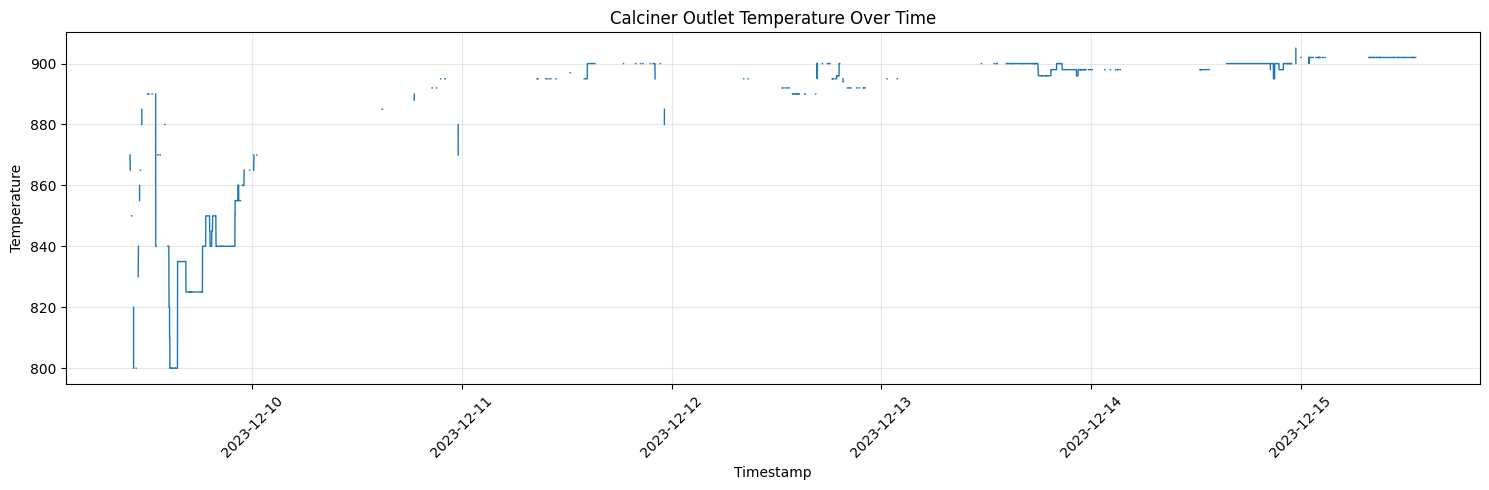

Total readings: 6547
Gaps greater than 2 minutes: 485
Gaps greater than 10 minutes: 142


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

plot_data = temp_check.copy()
plot_data = plot_data.sort_values("timestamp")

# Break the line across large timestamp gaps
plot_data["gap"] = plot_data["timestamp"].diff().dt.total_seconds()
plot_data["plot_value"] = plot_data["value"]

plot_data.loc[plot_data["gap"] > 120, "plot_value"] = float("nan")

plt.figure(figsize=(15, 5))
plt.plot(
    plot_data["timestamp"],
    plot_data["plot_value"],
    linewidth=1
)

plt.title("Calciner Outlet Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Total readings:", len(plot_data))
print("Gaps greater than 2 minutes:", (plot_data["gap"] > 120).sum())
print("Gaps greater than 10 minutes:", (plot_data["gap"] > 600).sum())


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Rebuild chronological temperature samples
check = temp_check[
    ["timestamp", "value"]
].copy()

check = check.sort_values("timestamp").reset_index(drop=True)

# Find the first observation 60 to 90 seconds later
future = check[["timestamp", "value"]].copy()
future = future.rename(
    columns={
        "timestamp": "future_timestamp",
        "value": "future_temperature"
    }
)

check["target_time"] = (
    check["timestamp"] + pd.Timedelta(seconds=60)
)

pairs = pd.merge_asof(
    check.sort_values("target_time"),
    future.sort_values("future_timestamp"),
    left_on="target_time",
    right_on="future_timestamp",
    direction="forward",
    tolerance=pd.Timedelta(seconds=30)
)

pairs["horizon_seconds"] = (
    pairs["future_timestamp"] - pairs["timestamp"]
).dt.total_seconds()

pairs = pairs[
    pairs["horizon_seconds"].between(60, 90)
].dropna(subset=["future_temperature"]).copy()

# Only score samples where the future observation is valid
pairs["baseline_prediction"] = pairs["value"]
pairs["absolute_error"] = (
    pairs["future_temperature"] - pairs["baseline_prediction"]
).abs()

pairs["temperature_changed"] = (
    pairs["future_temperature"] != pairs["value"]
)

print("Valid forecast pairs:", len(pairs))
print("Temperature changed:", int(pairs["temperature_changed"].sum()))
print("Temperature unchanged:", int((~pairs["temperature_changed"]).sum()))

if len(pairs) > 0:
    print(
        "Overall baseline MAE:",
        round(pairs["absolute_error"].mean(), 4)
    )

    changed = pairs[pairs["temperature_changed"]]
    if len(changed) > 0:
        print(
            "MAE when temperature changes:",
            round(changed["absolute_error"].mean(), 4)
        )
    else:
        print("No temperature changes found in these forecast pairs.")


Valid forecast pairs: 4946
Temperature changed: 111
Temperature unchanged: 4835
Overall baseline MAE: 0.133
MAE when temperature changes: 5.9279


In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Start from original, valid temperature readings
data = temp_check[["timestamp", "value"]].copy()
data = data.sort_values("timestamp").reset_index(drop=True)

# Create past-only features
data["previous_temperature"] = data["value"].shift(1)
data["temperature_change_previous"] = data["value"].diff()
data["temperature_change_2_steps"] = data["value"].diff(2)

# Create a future target 60–90 seconds ahead
future = data[["timestamp", "value"]].copy()
future = future.rename(
    columns={
        "timestamp": "future_timestamp",
        "value": "future_temperature"
    }
)

data["target_time"] = data["timestamp"] + pd.Timedelta(seconds=60)

samples = pd.merge_asof(
    data.sort_values("target_time"),
    future.sort_values("future_timestamp"),
    left_on="target_time",
    right_on="future_timestamp",
    direction="forward",
    tolerance=pd.Timedelta(seconds=30)
)

samples["horizon_seconds"] = (
    samples["future_timestamp"] - samples["timestamp"]
).dt.total_seconds()

samples = samples[
    samples["horizon_seconds"].between(60, 90)
].copy()

samples = samples.replace([np.inf, -np.inf], np.nan)
samples = samples.dropna(
    subset=[
        "future_temperature",
        "value",
        "previous_temperature",
        "temperature_change_previous",
        "temperature_change_2_steps"
    ]
)

samples = samples.sort_values("timestamp").reset_index(drop=True)

feature_cols = [
    "value",
    "previous_temperature",
    "temperature_change_previous",
    "temperature_change_2_steps"
]

X = samples[feature_cols]
y = samples["future_temperature"]

split_idx = int(len(samples) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test_new = y.iloc[:split_idx], y.iloc[split_idx:]

model_change = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=150,
        max_depth=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
)

model_change.fit(X_train, y_train)
predictions_change = model_change.predict(X_test)

baseline_predictions = X_test["value"].to_numpy()

print("========== CHANGE-AWARE MODEL ==========")
print("Valid samples:", len(samples))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("AI MAE:", round(
    mean_absolute_error(y_test_new, predictions_change), 4
))
print("Baseline MAE:", round(
    mean_absolute_error(y_test_new, baseline_predictions), 4
))
print("AI RMSE:", round(
    np.sqrt(mean_squared_error(y_test_new, predictions_change)), 4
))
print("Baseline RMSE:", round(
    np.sqrt(mean_squared_error(y_test_new, baseline_predictions)), 4
))


========== CHANGE-AWARE MODEL ==========
Valid samples: 4946
Training rows: 3956
Testing rows: 990
AI MAE: 1.076
Baseline MAE: 0.0505
AI RMSE: 1.5045
Baseline RMSE: 0.4714


In [ ]:
# Evaluate only cases where future temperature changed
evaluation = samples.iloc[split_idx:].copy()

evaluation["ai_prediction"] = predictions_change
evaluation["baseline_prediction"] = X_test["value"].to_numpy()

evaluation["ai_error"] = (
    evaluation["future_temperature"] - evaluation["ai_prediction"]
).abs()

evaluation["baseline_error"] = (
    evaluation["future_temperature"] - evaluation["baseline_prediction"]
).abs()

evaluation["temperature_changed"] = (
    evaluation["future_temperature"] != evaluation["value"]
)

changed = evaluation[evaluation["temperature_changed"]].copy()

print("========== CHANGED-TEMPERATURE EVALUATION ==========")
print("Changed cases:", len(changed))

if len(changed) > 0:
    print(
        "AI MAE on changed cases:",
        round(changed["ai_error"].mean(), 4)
    )
    print(
        "Baseline MAE on changed cases:",
        round(changed["baseline_error"].mean(), 4)
    )
    print(
        "AI RMSE on changed cases:",
        round(np.sqrt(np.mean(
            (changed["future_temperature"] -
             changed["ai_prediction"]) ** 2
        )), 4)
    )
    print(
        "Baseline RMSE on changed cases:",
        round(np.sqrt(np.mean(
            (changed["future_temperature"] -
             changed["baseline_prediction"]) ** 2
        )), 4)
    )
else:
    print("No changed-temperature cases in the test period.")


========== CHANGED-TEMPERATURE EVALUATION ==========
Changed cases: 13
AI MAE on changed cases: 3.7894
Baseline MAE on changed cases: 3.8462
AI RMSE on changed cases: 4.045
Baseline RMSE on changed cases: 4.1138


In [ ]:
# Check available sensor data and timestamp coverage

sensor_names = [
    "calciner_outlet_temperature",
    "kiln_head_pressure",
    "raw_feed",
    "kiln_oil_flow",
    "kiln_motor_speed",
    "cooler_speed",
    "id_fan_1_speed",
    "id_fan_2_speed",
    "kiln_current",
    "calciner_outlet_pressure",
    "cyclone_1_outlet_temperature",
]

coverage_rows = []

for name in sensor_names:
    df = sensor_data[name].copy()

    valid = df[
        (df["quality"] == "GOOD")
        & df["timestamp"].notna()
        & df["value"].notna()
    ].sort_values("timestamp")

    coverage_rows.append({
        "sensor": name,
        "valid_readings": len(valid),
        "start_time": valid["timestamp"].min(),
        "end_time": valid["timestamp"].max(),
        "median_gap_seconds": (
            valid["timestamp"].diff().dt.total_seconds().median()
        )
    })

coverage = pd.DataFrame(coverage_rows)

display(coverage)


,sensor,valid_readings,start_time,end_time,median_gap_seconds
0,calciner_outlet_temperature,6547,2023-12-09 10:01:31,2023-12-15 13:10:04,13.0
1,kiln_head_pressure,6448,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0
2,raw_feed,6628,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0
3,kiln_oil_flow,6584,2023-12-09 10:01:31,2023-12-15 13:10:04,13.0
4,kiln_motor_speed,6407,2023-12-09 10:11:24,2023-12-15 13:10:04,13.0
5,cooler_speed,6454,2023-12-09 10:13:37,2023-12-15 13:10:04,13.0
6,id_fan_1_speed,6518,2023-12-09 10:30:30,2023-12-15 13:10:04,13.0
7,id_fan_2_speed,6515,2023-12-09 10:30:30,2023-12-15 13:10:04,13.0
8,kiln_current,114755,2023-12-09 10:00:06,2023-12-15 13:10:23,3.0
9,calciner_outlet_pressure,112119,2023-12-09 10:00:02,2023-12-15 13:10:23,3.0


In [ ]:
import pandas as pd
import numpy as np

# Sensor variables to use as model inputs
feature_names = [
    "kiln_head_pressure",
    "raw_feed",
    "kiln_oil_flow",
    "kiln_motor_speed",
    "cooler_speed",
    "id_fan_1_speed",
    "id_fan_2_speed",
    "kiln_current",
    "calciner_outlet_pressure",
    "cyclone_1_outlet_temperature",
]

# Prepare valid temperature observations
target = sensor_data["calciner_outlet_temperature"].copy()

target = target[
    (target["quality"] == "GOOD")
    & target["timestamp"].notna()
    & target["value"].notna()
][["timestamp", "value"]].copy()

target = (
    target.sort_values("timestamp")
    .groupby("timestamp", as_index=False)["value"]
    .median()
    .rename(columns={"value": "current_temperature"})
)

# Define target temperature 60–90 seconds ahead
target["target_time"] = (
    target["timestamp"] + pd.Timedelta(seconds=60)
)

future = target[["timestamp", "current_temperature"]].copy()
future = future.rename(
    columns={
        "timestamp": "future_timestamp",
        "current_temperature": "future_temperature"
    }
)

dataset = pd.merge_asof(
    target.sort_values("target_time"),
    future.sort_values("future_timestamp"),
    left_on="target_time",
    right_on="future_timestamp",
    direction="forward",
    tolerance=pd.Timedelta(seconds=30)
)

dataset["forecast_horizon_seconds"] = (
    dataset["future_timestamp"] - dataset["timestamp"]
).dt.total_seconds()

dataset = dataset[
    dataset["forecast_horizon_seconds"].between(60, 90)
].copy()

# Attach the most recent available sensor reading at each prediction time
for name in feature_names:
    sensor = sensor_data[name].copy()

    sensor = sensor[
        (sensor["quality"] == "GOOD")
        & sensor["timestamp"].notna()
        & sensor["value"].notna()
    ][["timestamp", "value"]].copy()

    sensor = (
        sensor.sort_values("timestamp")
        .groupby("timestamp", as_index=False)["value"]
        .median()
        .rename(columns={"value": name})
    )

    dataset = pd.merge_asof(
        dataset.sort_values("timestamp"),
        sensor.sort_values("timestamp"),
        on="timestamp",
        direction="backward",
        tolerance=pd.Timedelta(seconds=30)
    )

# Prepare final dataset
dataset = dataset.replace([np.inf, -np.inf], np.nan)

model_features = ["current_temperature"] + feature_names

dataset = dataset.dropna(
    subset=model_features + ["future_temperature"]
).sort_values("timestamp").reset_index(drop=True)

print("Unified dataset rows:", len(dataset))
print("Input features:", len(model_features))
print("First timestamp:", dataset["timestamp"].min())
print("Last timestamp:", dataset["timestamp"].max())

display(dataset.head())


Unified dataset rows: 4924
Input features: 11
First timestamp: 2023-12-09 12:00:33
Last timestamp: 2023-12-15 13:09:01


,timestamp,current_temperature,target_time,future_timestamp,future_temperature,forecast_horizon_seconds,kiln_head_pressure,raw_feed,kiln_oil_flow,kiln_motor_speed,cooler_speed,id_fan_1_speed,id_fan_2_speed,kiln_current,calciner_outlet_pressure,cyclone_1_outlet_temperature
0,2023-12-09 12:00:33,890.0,2023-12-09 12:01:33,2023-12-09 12:01:38,890.0,65.0,-25.0,200.0,100.0,1.8,8.0,760.0,760.0,659.28,-453.70,372.11
1,2023-12-09 12:00:59,890.0,2023-12-09 12:01:59,2023-12-09 12:02:04,890.0,65.0,-25.0,200.0,100.0,1.8,8.0,760.0,760.0,642.11,-482.06,372.40
2,2023-12-09 12:01:12,890.0,2023-12-09 12:02:12,2023-12-09 12:02:17,890.0,65.0,-25.0,200.0,100.0,1.8,8.0,760.0,760.0,595.70,-453.70,372.40
3,2023-12-09 12:01:25,890.0,2023-12-09 12:02:25,2023-12-09 12:02:30,890.0,65.0,-25.0,200.0,100.0,1.8,8.0,760.0,760.0,605.91,-441.55,372.40
4,2023-12-09 12:01:38,890.0,2023-12-09 12:02:38,2023-12-09 12:02:43,890.0,65.0,-25.0,200.0,100.0,1.8,8.0,760.0,760.0,649.77,-465.86,372.40


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Sort observations chronologically
dataset = dataset.sort_values("timestamp").reset_index(drop=True)

# Define features and target
model_features = [
    "current_temperature",
    "kiln_head_pressure",
    "raw_feed",
    "kiln_oil_flow",
    "kiln_motor_speed",
    "cooler_speed",
    "id_fan_1_speed",
    "id_fan_2_speed",
    "kiln_current",
    "calciner_outlet_pressure",
    "cyclone_1_outlet_temperature",
]

X = dataset[model_features]
y = dataset["future_temperature"]

# Chronological split: earlier observations for training
split_idx = int(len(dataset) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test_integrated = y.iloc[split_idx:]

# Train Random Forest
integrated_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
)

integrated_model.fit(X_train, y_train)

# Generate predictions
ai_predictions = integrated_model.predict(X_test)

# Baseline: current temperature remains unchanged
baseline_predictions = X_test["current_temperature"].to_numpy()

# Evaluate both methods
ai_mae = mean_absolute_error(y_test_integrated, ai_predictions)
ai_rmse = np.sqrt(mean_squared_error(y_test_integrated, ai_predictions))

baseline_mae = mean_absolute_error(
    y_test_integrated, baseline_predictions
)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_integrated, baseline_predictions)
)

print("========== INTEGRATED MODEL RESULTS ==========")
print("Dataset rows:", len(dataset))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("AI MAE:", round(ai_mae, 4))
print("AI RMSE:", round(ai_rmse, 4))
print("Baseline MAE:", round(baseline_mae, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))

# Show sample predictions
results_integrated = pd.DataFrame({
    "timestamp": dataset["timestamp"].iloc[split_idx:].to_numpy(),
    "current_temperature": X_test["current_temperature"].to_numpy(),
    "actual_future_temperature": y_test_integrated.to_numpy(),
    "ai_prediction": ai_predictions,
    "baseline_prediction": baseline_predictions,
})

display(results_integrated.head(10))


========== INTEGRATED MODEL RESULTS ==========
Dataset rows: 4924
Training rows: 3939
Testing rows: 985
AI MAE: 1.8381
AI RMSE: 2.6958
Baseline MAE: 0.0508
Baseline RMSE: 0.4726


,timestamp,current_temperature,actual_future_temperature,ai_prediction,baseline_prediction
0,2023-12-14 19:29:19,900.0,900.0,900.0,900.0
1,2023-12-14 19:29:32,900.0,900.0,900.0,900.0
2,2023-12-14 19:29:45,900.0,900.0,900.0,900.0
3,2023-12-14 19:29:58,900.0,900.0,900.0,900.0
4,2023-12-14 19:30:11,900.0,900.0,900.0,900.0
5,2023-12-14 19:30:24,900.0,900.0,900.0,900.0
6,2023-12-14 19:30:37,900.0,900.0,900.0,900.0
7,2023-12-14 19:30:50,900.0,900.0,900.0,900.0
8,2023-12-14 19:31:03,900.0,900.0,900.0,900.0
9,2023-12-14 19:31:16,900.0,900.0,900.0,900.0


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Identify test cases where the future temperature changed
changed_mask = (
    y_test_integrated.to_numpy()
    != X_test["current_temperature"].to_numpy()
)

actual_changed = y_test_integrated.to_numpy()[changed_mask]
ai_changed = ai_predictions[changed_mask]
baseline_changed = baseline_predictions[changed_mask]

print("========== CHANGED-TEMPERATURE TEST ==========")
print("Changed cases:", len(actual_changed))

if len(actual_changed) > 0:
    print(
        "AI MAE:",
        round(mean_absolute_error(actual_changed, ai_changed), 4)
    )
    print(
        "Baseline MAE:",
        round(mean_absolute_error(actual_changed, baseline_changed), 4)
    )
    print(
        "AI RMSE:",
        round(np.sqrt(mean_squared_error(actual_changed, ai_changed)), 4)
    )
    print(
        "Baseline RMSE:",
        round(np.sqrt(mean_squared_error(actual_changed, baseline_changed)), 4)
    )
else:
    print("No changed-temperature cases in the test period.")


========== CHANGED-TEMPERATURE TEST ==========
Changed cases: 13
AI MAE: 3.754
Baseline MAE: 3.8462
AI RMSE: 4.0763
Baseline RMSE: 4.1138


In [ ]:
# Compare model performance across the chronological test period

evaluation = pd.DataFrame({
    "timestamp": dataset["timestamp"].iloc[split_idx:].to_numpy(),
    "actual": y_test_integrated.to_numpy(),
    "current": X_test["current_temperature"].to_numpy(),
    "ai_prediction": ai_predictions,
})

evaluation["changed"] = evaluation["actual"] != evaluation["current"]

evaluation["ai_absolute_error"] = (
    evaluation["actual"] - evaluation["ai_prediction"]
).abs()

evaluation["baseline_absolute_error"] = (
    evaluation["actual"] - evaluation["current"]
).abs()

evaluation["month_day"] = evaluation["timestamp"].dt.strftime("%Y-%m-%d")

print("Changed cases by date:")
display(
    evaluation[evaluation["changed"]]
    .groupby("month_day")
    .agg(
        changed_cases=("changed", "size"),
        ai_mae=("ai_absolute_error", "mean"),
        baseline_mae=("baseline_absolute_error", "mean")
    )
)

print("\nOverall test period:")
print("Start:", evaluation["timestamp"].min())
print("End:", evaluation["timestamp"].max())
print("Changed cases:", int(evaluation["changed"].sum()))
print("Total cases:", len(evaluation))


Changed cases by date:


,changed_cases,ai_mae,baseline_mae
month_day,,,
2023-12-14,13,3.754049,3.846154



Overall test period:
Start: 2023-12-14 19:29:19
End: 2023-12-15 13:09:01
Changed cases: 13
Total cases: 985


In [ ]:
evaluation = evaluation.sort_values("timestamp").copy()

# Split the test period into 4 consecutive time blocks
evaluation["time_block"] = pd.qcut(
    np.arange(len(evaluation)),
    q=4,
    labels=["Block 1", "Block 2", "Block 3", "Block 4"]
)

block_summary = evaluation.groupby(
    "time_block", observed=False
).agg(
    rows=("actual", "size"),
    changed_cases=("changed", "sum"),
    ai_mae=("ai_absolute_error", "mean"),
    baseline_mae=("baseline_absolute_error", "mean"),
    start_time=("timestamp", "min"),
    end_time=("timestamp", "max")
).reset_index()

display(block_summary)


,time_block,rows,changed_cases,ai_mae,baseline_mae,start_time,end_time
0,Block 1,247,0,0.000615,0.000000,2023-12-14 19:29:19,2023-12-14 20:27:20
1,Block 2,246,13,0.314238,0.203252,2023-12-14 20:27:33,2023-12-14 22:19:26
2,Block 3,246,0,3.414915,0.000000,2023-12-14 22:19:39,2023-12-15 10:21:20
3,Block 4,246,0,3.630288,0.000000,2023-12-15 10:22:06,2023-12-15 13:09:01


In [ ]:
print("========== TIME BLOCK EVALUATION ==========")

display(
    block_summary[
        [
            "time_block",
            "rows",
            "changed_cases",
            "ai_mae",
            "baseline_mae",
            "start_time",
            "end_time"
        ]
    ].to_string(index=False)
)

print("\n========== TEMPERATURE CHANGE COUNTS ==========")
print(
    evaluation.groupby("time_block", observed=False)["changed"]
    .sum()
    .to_dict()
)


========== TIME BLOCK EVALUATION ==========


'time_block  rows  changed_cases   ai_mae  baseline_mae          start_time            end_time\n   Block 1   247              0 0.000615      0.000000 2023-12-14 19:29:19 2023-12-14 20:27:20\n   Block 2   246             13 0.314238      0.203252 2023-12-14 20:27:33 2023-12-14 22:19:26\n   Block 3   246              0 3.414915      0.000000 2023-12-14 22:19:39 2023-12-15 10:21:20\n   Block 4   246              0 3.630288      0.000000 2023-12-15 10:22:06 2023-12-15 13:09:01'


========== TEMPERATURE CHANGE COUNTS ==========
{'Block 1': 0, 'Block 2': 13, 'Block 3': 0, 'Block 4': 0}


In [ ]:
# Check target alignment and prediction errors

check_eval = evaluation.copy()

check_eval["baseline_prediction"] = check_eval["current"]
check_eval["baseline_error_check"] = (
    check_eval["actual"] - check_eval["baseline_prediction"]
).abs()

check_eval["ai_error_check"] = (
    check_eval["actual"] - check_eval["ai_prediction"]
).abs()

print("Rows where actual differs from current:",
      int((check_eval["actual"] != check_eval["current"]).sum()))

print("Rows with non-zero baseline error:",
      int((check_eval["baseline_error_check"] > 0).sum()))

print("\nLargest baseline errors:")
display(
    check_eval.loc[
        check_eval["baseline_error_check"] > 0,
        [
            "timestamp",
            "current",
            "actual",
            "baseline_error_check",
            "ai_prediction",
            "ai_error_check"
        ]
    ].head(20)
)


Rows where actual differs from current: 13
Rows with non-zero baseline error: 13

Largest baseline errors:


,timestamp,current,actual,baseline_error_check,ai_prediction,ai_error_check
261,2023-12-14 20:30:54,900.0,898.0,2.0,900.000000,2.000000
262,2023-12-14 20:31:07,900.0,898.0,2.0,900.000000,2.000000
277,2023-12-14 20:51:38,900.0,895.0,5.0,900.000000,5.000000
278,2023-12-14 20:51:51,900.0,895.0,5.0,900.000000,5.000000
279,2023-12-14 20:52:04,900.0,895.0,5.0,899.995556,4.995556
280,2023-12-14 20:52:17,900.0,895.0,5.0,900.000000,5.000000
281,2023-12-14 20:52:30,900.0,895.0,5.0,900.000000,5.000000
304,2023-12-14 21:00:26,895.0,900.0,5.0,895.006016,4.993984
305,2023-12-14 21:00:42,895.0,900.0,5.0,895.009350,4.990650
306,2023-12-14 21:00:55,895.0,900.0,5.0,895.007222,4.992778


In [ ]:
# Inspect sensor readings for temperature-change cases

sensor_columns = [
    "kiln_head_pressure",
    "raw_feed",
    "kiln_oil_flow",
    "kiln_motor_speed",
    "cooler_speed",
    "id_fan_1_speed",
    "id_fan_2_speed",
    "kiln_current",
    "calciner_outlet_pressure",
    "cyclone_1_outlet_temperature",
]

# Select test rows where future temperature differs from current
changed_mask = (
    y_test_integrated.to_numpy()
    != X_test["current_temperature"].to_numpy()
)

changed_positions = np.flatnonzero(changed_mask)

print("Temperature-change cases:", len(changed_positions))

if len(changed_positions) > 0:
    # Retrieve the matching rows from the unified dataset
    changed_indices = np.arange(split_idx, len(dataset))[changed_positions]

    changed_rows = dataset.iloc[changed_indices].copy()

    display(
        changed_rows[
            ["timestamp", "current_temperature", "future_temperature"]
            + sensor_columns
        ].reset_index(drop=True)
    )

    print("\nSensor variation across changed-temperature cases:")
    display(
        changed_rows[sensor_columns].describe().T[
            ["mean", "std", "min", "max"]
        ]
    )


Temperature-change cases: 13


,timestamp,current_temperature,future_temperature,kiln_head_pressure,raw_feed,kiln_oil_flow,kiln_motor_speed,cooler_speed,id_fan_1_speed,id_fan_2_speed,kiln_current,calciner_outlet_pressure,cyclone_1_outlet_temperature
0,2023-12-14 20:30:54,900.0,898.0,-20.0,355.0,85.0,2.85,13.0,940.0,940.0,535.83,-1028.90,324.07
1,2023-12-14 20:31:07,900.0,898.0,-20.0,355.0,85.0,2.85,13.0,940.0,940.0,570.87,-992.48,324.07
2,2023-12-14 20:51:38,900.0,895.0,-20.0,370.0,85.0,2.85,13.0,940.0,940.0,595.23,-960.07,331.60
3,2023-12-14 20:51:51,900.0,895.0,-20.0,370.0,85.0,2.85,13.0,940.0,940.0,558.10,-931.71,331.31
4,2023-12-14 20:52:04,900.0,895.0,-20.0,375.0,85.0,2.85,13.0,940.0,940.0,605.45,-931.71,331.02
5,2023-12-14 20:52:17,900.0,895.0,-20.0,375.0,85.0,2.85,13.0,940.0,940.0,585.95,-968.17,331.02
6,2023-12-14 20:52:30,900.0,895.0,-20.0,375.0,85.0,2.85,13.0,940.0,940.0,556.02,-972.22,331.02
7,2023-12-14 21:00:26,895.0,900.0,-20.0,375.0,85.0,2.85,13.0,940.0,940.0,520.05,-939.82,326.10
8,2023-12-14 21:00:42,895.0,900.0,-20.0,375.0,85.0,2.85,13.0,940.0,940.0,509.37,-899.31,325.81
9,2023-12-14 21:00:55,895.0,900.0,-20.0,375.0,85.0,2.85,13.0,940.0,940.0,560.89,-976.27,325.81



Sensor variation across changed-temperature cases:


,mean,std,min,max
kiln_head_pressure,-20.000000,0.000000,-20.00,-20.00
raw_feed,366.538462,9.657600,355.00,375.00
kiln_oil_flow,83.846154,2.192645,80.00,85.00
kiln_motor_speed,2.838462,0.021926,2.80,2.85
cooler_speed,13.000000,0.000000,13.00,13.00
id_fan_1_speed,940.000000,0.000000,940.00,940.00
id_fan_2_speed,940.000000,0.000000,940.00,940.00
kiln_current,554.642308,30.061514,509.37,605.45
calciner_outlet_pressure,-959.132308,32.195122,-1028.90,-899.31
cyclone_1_outlet_temperature,328.125385,2.826917,324.07,331.60


========== SENSOR FEATURE IMPORTANCE ==========


,sensor,importance
0,current_temperature,0.997888
1,calciner_outlet_pressure,0.000448
2,cyclone_1_outlet_temperature,0.000408
3,id_fan_1_speed,0.000311
4,kiln_current,0.000300
5,id_fan_2_speed,0.000288
6,raw_feed,0.000226
7,kiln_oil_flow,0.000081
8,cooler_speed,0.000036
9,kiln_head_pressure,0.000011


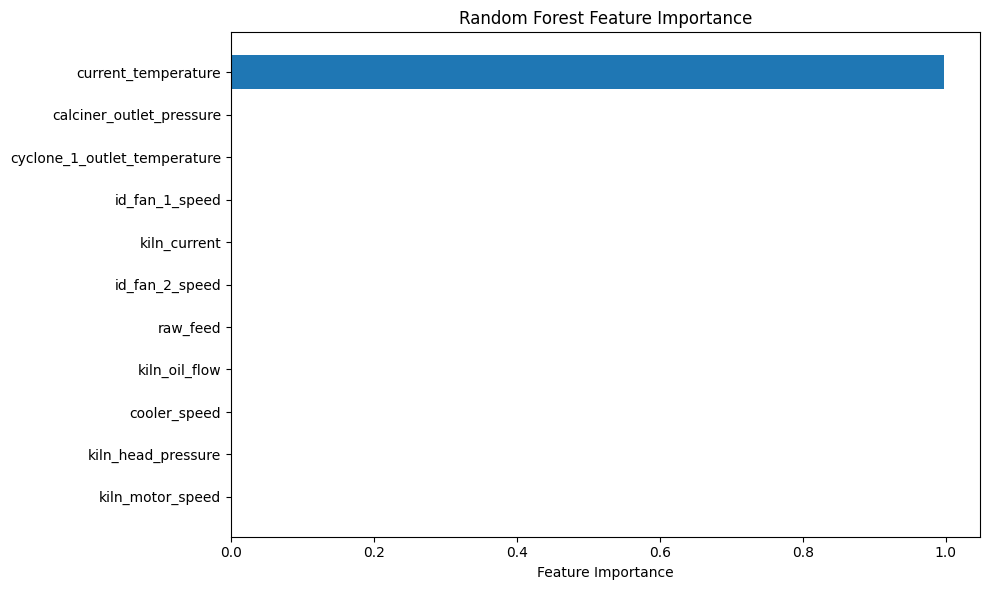

In [ ]:
import pandas as pd
import numpy as np

# Extract feature importance from the trained Random Forest
rf = integrated_model.named_steps["randomforestregressor"]

importance = pd.DataFrame({
    "sensor": model_features,
    "importance": rf.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

print("========== SENSOR FEATURE IMPORTANCE ==========")
display(importance)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(
    importance["sensor"][::-1],
    importance["importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd

perm = permutation_importance(
    integrated_model,
    X_test,
    y_test_integrated,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_results = pd.DataFrame({
    "sensor": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(permutation_results)


,sensor,importance_mean,importance_std
0,current_temperature,3.088110e-01,1.389791e-02
4,kiln_motor_speed,3.382603e-03,7.791491e-04
8,kiln_current,2.054300e-03,1.639520e-03
10,cyclone_1_outlet_temperature,2.857415e-04,1.496406e-03
7,id_fan_2_speed,1.350031e-14,1.679656e-14
6,id_fan_1_speed,7.860379e-15,3.741873e-14
1,kiln_head_pressure,4.352074e-15,1.253921e-14
5,cooler_speed,-3.907985e-15,5.681219e-15
2,raw_feed,-1.711659e-03,9.410626e-04
9,calciner_outlet_pressure,-1.413678e-02,2.526649e-03


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Keep the existing chronological train/test split
feature_sets = {
    "Temperature only": ["current_temperature"],
    "Reduced sensor model": [
        "current_temperature",
        "kiln_motor_speed",
        "kiln_current",
        "cyclone_1_outlet_temperature"
    ]
}

comparison_rows = []

baseline_pred = X_test["current_temperature"].to_numpy()

comparison_rows.append({
    "model": "Baseline",
    "MAE": mean_absolute_error(y_test_integrated, baseline_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test_integrated, baseline_pred))
})

for model_name, features in feature_sets.items():
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=150,
            max_depth=12,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )
    )

    model.fit(X_train[features], y_train)
    pred = model.predict(X_test[features])

    comparison_rows.append({
        "model": model_name,
        "MAE": mean_absolute_error(y_test_integrated, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_integrated, pred))
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(4))


,model,MAE,RMSE
0,Baseline,0.0508,0.4726
1,Temperature only,1.0588,1.4928
2,Reduced sensor model,1.0643,1.5031


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Prepare sensor data
anomaly_features = [
    "current_temperature",
    "kiln_head_pressure",
    "raw_feed",
    "kiln_oil_flow",
    "kiln_motor_speed",
    "cooler_speed",
    "id_fan_1_speed",
    "id_fan_2_speed",
    "kiln_current",
    "calciner_outlet_pressure",
    "cyclone_1_outlet_temperature"
]

anomaly_data = dataset[
    ["timestamp"] + anomaly_features
].copy()

anomaly_data = anomaly_data.dropna().sort_values(
    "timestamp"
).reset_index(drop=True)

# Train on the earlier 80% of observations
split = int(len(anomaly_data) * 0.8)

train_data = anomaly_data.iloc[:split]
test_data = anomaly_data.iloc[split:].copy()

anomaly_model = make_pipeline(
    StandardScaler(),
    IsolationForest(
        n_estimators=200,
        contamination=0.02,
        random_state=42,
        n_jobs=-1
    )
)

anomaly_model.fit(train_data[anomaly_features])

# Detect unusual sensor patterns in the test period
test_data["anomaly_label"] = anomaly_model.predict(
    test_data[anomaly_features]
)

test_data["anomaly_score"] = -anomaly_model.decision_function(
    test_data[anomaly_features]
)

test_data["anomaly_status"] = np.where(
    test_data["anomaly_label"] == -1,
    "Unusual",
    "Normal"
)

print("========== ANOMALY DETECTION ==========")
print("Test readings:", len(test_data))
print("Unusual readings:",
      (test_data["anomaly_label"] == -1).sum())
print("Normal readings:",
      (test_data["anomaly_label"] == 1).sum())

print("\nMost unusual readings:")
display(
    test_data.sort_values(
        "anomaly_score",
        ascending=False
    ).head(10)
)


========== ANOMALY DETECTION ==========
Test readings: 985
Unusual readings: 0
Normal readings: 985

Most unusual readings:


,timestamp,current_temperature,kiln_head_pressure,raw_feed,kiln_oil_flow,kiln_motor_speed,cooler_speed,id_fan_1_speed,id_fan_2_speed,kiln_current,calciner_outlet_pressure,cyclone_1_outlet_temperature,anomaly_label,anomaly_score,anomaly_status
4610,2023-12-15 09:36:32,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,545.34,-830.44,339.70,1,-0.091011,Normal
4590,2023-12-15 09:16:21,902.0,-20.0,346.0,50.0,2.75,13.0,940.0,940.0,533.51,-1061.30,334.49,1,-0.092274,Normal
4605,2023-12-15 09:33:18,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,525.85,-939.82,341.44,1,-0.093199,Normal
4743,2023-12-15 11:14:04,902.0,-20.0,352.0,45.0,2.75,13.0,940.0,940.0,504.73,-899.31,325.23,1,-0.095235,Normal
4830,2023-12-15 12:10:17,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,511.69,-1033.00,337.09,1,-0.095628,Normal
4741,2023-12-15 11:12:51,902.0,-20.0,352.0,45.0,2.75,13.0,940.0,940.0,511.00,-854.75,326.97,1,-0.095695,Normal
4612,2023-12-15 09:39:19,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,500.55,-870.95,337.38,1,-0.098747,Normal
4832,2023-12-15 12:11:21,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,500.32,-895.25,338.54,1,-0.100073,Normal
4604,2023-12-15 09:32:50,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,560.19,-951.97,341.44,1,-0.101412,Normal
4745,2023-12-15 11:15:50,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,493.59,-899.31,326.68,1,-0.103026,Normal


In [ ]:
# Review anomaly scores and test a 2% anomaly threshold

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

anomaly_features = [
    "current_temperature",
    "kiln_head_pressure",
    "raw_feed",
    "kiln_oil_flow",
    "kiln_motor_speed",
    "cooler_speed",
    "id_fan_1_speed",
    "id_fan_2_speed",
    "kiln_current",
    "calciner_outlet_pressure",
    "cyclone_1_outlet_temperature"
]

train_values = train_data[anomaly_features]
test_values = test_data[anomaly_features]

# Fit a fresh model with a 2% contamination setting
review_model = make_pipeline(
    StandardScaler(),
    IsolationForest(
        n_estimators=200,
        contamination=0.02,
        random_state=42,
        n_jobs=-1
    )
)

review_model.fit(train_values)

# Lower decision_function values are more unusual
decision_scores = review_model.decision_function(test_values)
labels = review_model.predict(test_values)

review = test_data[["timestamp"] + anomaly_features].copy()
review["decision_score"] = decision_scores
review["anomaly_status"] = np.where(
    labels == -1, "Unusual", "Normal"
)

print("Test readings:", len(review))
print("Unusual readings:", int((labels == -1).sum()))
print("Normal readings:", int((labels == 1).sum()))

print("\nDecision score statistics:")
print(pd.Series(decision_scores).describe())

print("\nLowest decision scores (most unusual):")
display(
    review.sort_values("decision_score").head(10)
)


Test readings: 985
Unusual readings: 0
Normal readings: 985

Decision score statistics:
count    985.000000
mean       0.171679
std        0.037173
min        0.091011
25%        0.134682
50%        0.175272
75%        0.201949
max        0.243086
dtype: float64

Lowest decision scores (most unusual):


,timestamp,current_temperature,kiln_head_pressure,raw_feed,kiln_oil_flow,kiln_motor_speed,cooler_speed,id_fan_1_speed,id_fan_2_speed,kiln_current,calciner_outlet_pressure,cyclone_1_outlet_temperature,decision_score,anomaly_status
4610,2023-12-15 09:36:32,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,545.34,-830.44,339.70,0.091011,Normal
4590,2023-12-15 09:16:21,902.0,-20.0,346.0,50.0,2.75,13.0,940.0,940.0,533.51,-1061.30,334.49,0.092274,Normal
4605,2023-12-15 09:33:18,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,525.85,-939.82,341.44,0.093199,Normal
4743,2023-12-15 11:14:04,902.0,-20.0,352.0,45.0,2.75,13.0,940.0,940.0,504.73,-899.31,325.23,0.095235,Normal
4830,2023-12-15 12:10:17,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,511.69,-1033.00,337.09,0.095628,Normal
4741,2023-12-15 11:12:51,902.0,-20.0,352.0,45.0,2.75,13.0,940.0,940.0,511.00,-854.75,326.97,0.095695,Normal
4612,2023-12-15 09:39:19,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,500.55,-870.95,337.38,0.098747,Normal
4832,2023-12-15 12:11:21,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,500.32,-895.25,338.54,0.100073,Normal
4604,2023-12-15 09:32:50,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,560.19,-951.97,341.44,0.101412,Normal
4745,2023-12-15 11:15:50,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,493.59,-899.31,326.68,0.103026,Normal


In [ ]:
# Rank unusual readings using anomaly scores

review = review.copy()

# Higher scores mean more unusual in this ranking
review["anomaly_score"] = -review["decision_score"]

# Flag the top 2% most unusual test readings for review
threshold = review["anomaly_score"].quantile(0.98)

review["review_flag"] = np.where(
    review["anomaly_score"] >= threshold,
    "Review",
    "Not flagged"
)

print("Review threshold:", round(threshold, 6))
print("Flagged readings:", int((review["review_flag"] == "Review").sum()))
print("Total test readings:", len(review))

print("\nMost unusual readings to review:")
display(
    review.sort_values(
        "anomaly_score",
        ascending=False
    )[
        ["timestamp"] + anomaly_features
        + ["anomaly_score", "review_flag"]
    ].head(20)
)


Review threshold: -0.109197
Flagged readings: 20
Total test readings: 985

Most unusual readings to review:


,timestamp,current_temperature,kiln_head_pressure,raw_feed,kiln_oil_flow,kiln_motor_speed,cooler_speed,id_fan_1_speed,id_fan_2_speed,kiln_current,calciner_outlet_pressure,cyclone_1_outlet_temperature,anomaly_score,review_flag
4610,2023-12-15 09:36:32,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,545.34,-830.44,339.70,-0.091011,Review
4590,2023-12-15 09:16:21,902.0,-20.0,346.0,50.0,2.75,13.0,940.0,940.0,533.51,-1061.30,334.49,-0.092274,Review
4605,2023-12-15 09:33:18,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,525.85,-939.82,341.44,-0.093199,Review
4743,2023-12-15 11:14:04,902.0,-20.0,352.0,45.0,2.75,13.0,940.0,940.0,504.73,-899.31,325.23,-0.095235,Review
4830,2023-12-15 12:10:17,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,511.69,-1033.00,337.09,-0.095628,Review
4741,2023-12-15 11:12:51,902.0,-20.0,352.0,45.0,2.75,13.0,940.0,940.0,511.00,-854.75,326.97,-0.095695,Review
4612,2023-12-15 09:39:19,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,500.55,-870.95,337.38,-0.098747,Review
4832,2023-12-15 12:11:21,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,500.32,-895.25,338.54,-0.100073,Review
4604,2023-12-15 09:32:50,902.0,-20.0,348.0,45.0,2.75,13.0,940.0,940.0,560.19,-951.97,341.44,-0.101412,Review
4745,2023-12-15 11:15:50,902.0,-20.0,352.0,55.0,2.75,13.0,940.0,940.0,493.59,-899.31,326.68,-0.103026,Review


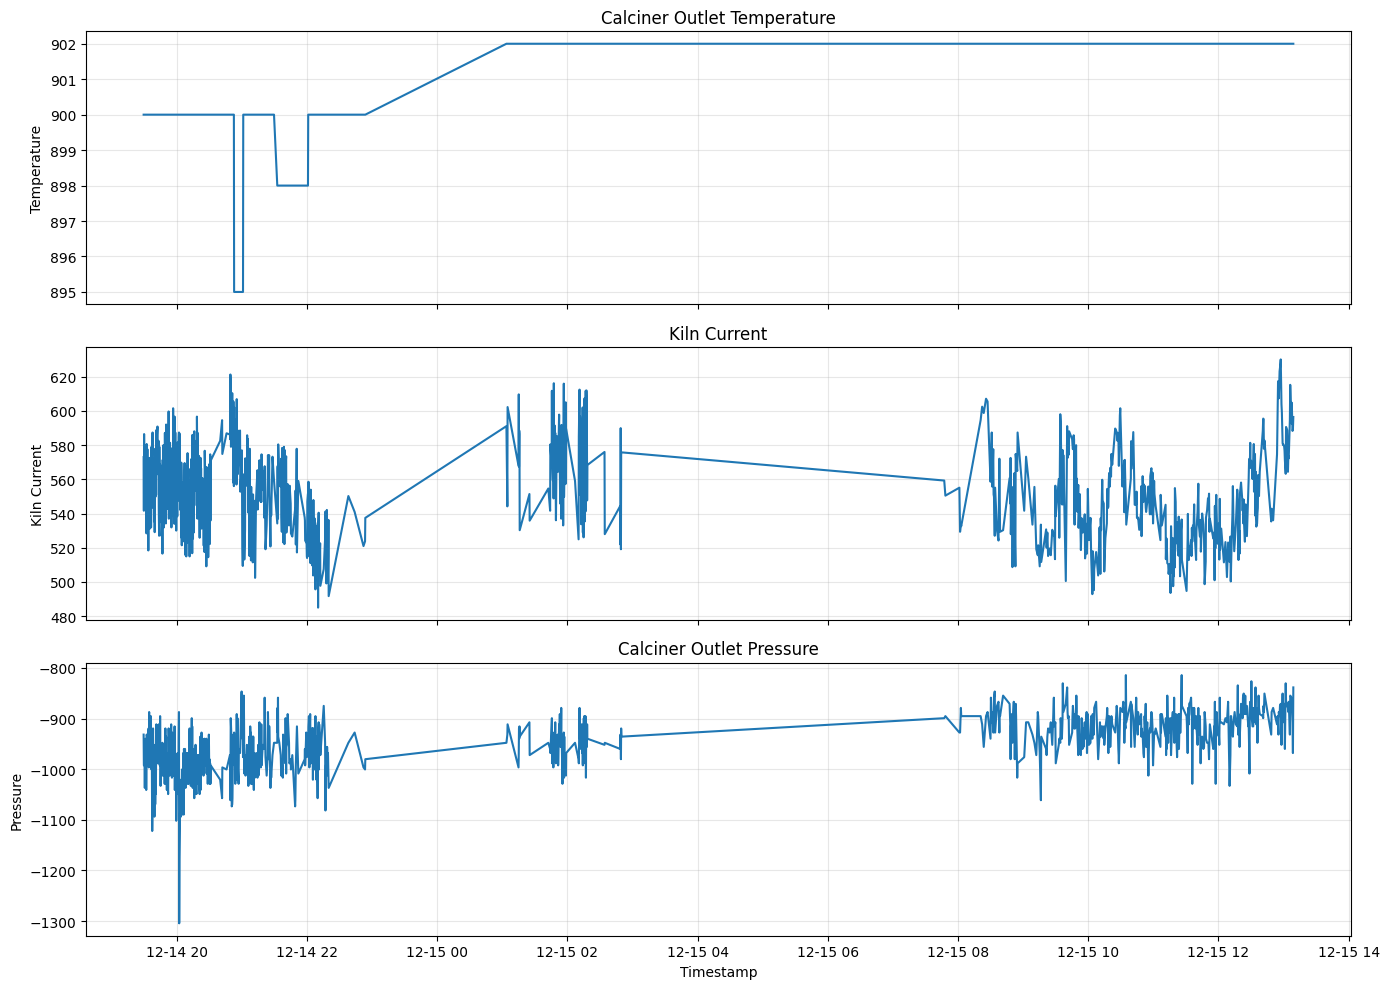

In [ ]:
import matplotlib.pyplot as plt

review_plot = review.sort_values("timestamp").copy()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(
    review_plot["timestamp"],
    review_plot["current_temperature"]
)
axes[0].set_ylabel("Temperature")
axes[0].set_title("Calciner Outlet Temperature")

axes[1].plot(
    review_plot["timestamp"],
    review_plot["kiln_current"]
)
axes[1].set_ylabel("Kiln Current")
axes[1].set_title("Kiln Current")

axes[2].plot(
    review_plot["timestamp"],
    review_plot["calciner_outlet_pressure"]
)
axes[2].set_ylabel("Pressure")
axes[2].set_title("Calciner Outlet Pressure")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.xlabel("Timestamp")
plt.tight_layout()
plt.show()


In [ ]:

# Check how far apart the reviewed timestamps are

review_plot = review.sort_values("timestamp").copy()

review_plot["time_gap_minutes"] = (
    review_plot["timestamp"].diff().dt.total_seconds() / 60
)

print("Largest time gaps between reviewed points:")
print(
    review_plot[
        ["timestamp", "time_gap_minutes", "current_temperature",
         "kiln_current", "calciner_outlet_pressure"]
    ].sort_values("time_gap_minutes", ascending=False).head(10)
)

print("\nNumber of reviewed points:", len(review_plot))
print(
    "Points with gaps over 5 minutes:",
    (review_plot["time_gap_minutes"] > 5).sum()
)


Largest time gaps between reviewed points:
               timestamp  time_gap_minutes  current_temperature  kiln_current  \
4536 2023-12-15 07:47:15        297.566667                902.0        559.27   
4439 2023-12-15 01:03:43        130.083333                902.0        591.06   
4434 2023-12-14 22:38:02         18.166667                900.0        550.21   
4542 2023-12-15 08:20:48         17.883333                902.0        594.54   
4450 2023-12-15 01:42:20         17.200000                902.0        554.62   
4528 2023-12-15 02:34:08         15.833333                902.0        575.97   
4530 2023-12-15 02:48:36         14.250000                902.0        544.41   
4538 2023-12-15 08:01:13         12.900000                902.0        555.09   
4442 2023-12-15 01:14:52         10.083333                902.0        567.85   
4448 2023-12-15 01:24:55          8.966667                902.0        551.38   

      calciner_outlet_pressure  
4536                   -899.31  

In [ ]:

print("Keys in sensor_data:")
print(list(sensor_data.keys()))

print("\nKeys in variable_map:")
print(list(variable_map.keys()))


Keys in sensor_data:
['calciner_outlet_temperature', 'kiln_head_pressure', 'raw_feed', 'kiln_oil_flow', 'kiln_motor_speed', 'cooler_speed', 'id_fan_1_speed', 'id_fan_2_speed', 'kiln_current', 'calciner_outlet_pressure', 'cyclone_1_outlet_temperature']

Keys in variable_map:
['x1_1.csv', 'x2_1.csv', 'x3_1.csv', 'x4_1.csv', 'x5_1.csv', 'x6_1.csv', 'x7_1.csv', 'x8_1.csv', 'y1_1.csv', 'y2_1.csv', 'y3_1.csv']


In [ ]:

import pandas as pd

gap_start = pd.Timestamp("2023-12-15 02:49:41")
gap_end = pd.Timestamp("2023-12-15 07:47:15")

sensors_to_check = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure"
]

for sensor_name in sensors_to_check:
    print("\n" + "=" * 60)
    print("Sensor:", sensor_name)

    original_df = sensor_data[sensor_name].copy()
    original_df["timestamp"] = pd.to_datetime(
        original_df["timestamp"]
    )

    window = original_df[
        (original_df["timestamp"] >= gap_start - pd.Timedelta(minutes=10)) &
        (original_df["timestamp"] <= gap_end + pd.Timedelta(minutes=10))
    ].sort_values("timestamp")

    print("Original readings in this window:", len(window))

    print("\nFirst readings:")
    print(window[["timestamp", "value"]].head(5).to_string(index=False))

    print("\nLast readings:")
    print(window[["timestamp", "value"]].tail(5).to_string(index=False))

    if len(window) >= 2:
        print(
            "\nLargest gap in this window (minutes):",
            round(
                window["timestamp"].diff().dt.total_seconds().max() / 60,
                2
            )
        )



Sensor: calciner_outlet_temperature
Original readings in this window: 21

First readings:
          timestamp  value
2023-12-15 02:48:36  902.0
2023-12-15 02:48:49  902.0
2023-12-15 02:49:02  902.0
2023-12-15 02:49:15  902.0
2023-12-15 02:49:28  902.0

Last readings:
          timestamp  value
2023-12-15 07:49:43  902.0
2023-12-15 07:56:11  902.0
2023-12-15 07:56:24  902.0
2023-12-15 07:56:40  902.0
2023-12-15 07:57:06  902.0

Largest gap in this window (minutes): 166.47

Sensor: kiln_current
Original readings in this window: 5054

First readings:
          timestamp  value
2023-12-15 02:39:42 529.33
2023-12-15 02:39:46 604.98
2023-12-15 02:39:55 564.37
2023-12-15 02:39:58 534.90
2023-12-15 02:40:11 590.59

Last readings:
          timestamp  value
2023-12-15 07:56:11 508.21
2023-12-15 07:56:24 589.20
2023-12-15 07:56:37 558.57
2023-12-15 07:56:40 594.07
2023-12-15 07:57:06 588.04

Largest gap in this window (minutes): 0.43

Sensor: calciner_outlet_pressure
Original readings in this w

In [ ]:

temp_df = sensor_data["calciner_outlet_temperature"].copy()

temp_df["timestamp"] = pd.to_datetime(temp_df["timestamp"])
temp_df = temp_df.sort_values("timestamp").reset_index(drop=True)

temp_df["gap_minutes"] = (
    temp_df["timestamp"].diff().dt.total_seconds() / 60
)

large_gaps = temp_df[temp_df["gap_minutes"] > 5].copy()

large_gaps["gap_start"] = temp_df["timestamp"].shift(1).loc[
    large_gaps.index
]

large_gaps = large_gaps[
    ["gap_start", "timestamp", "gap_minutes", "value"]
].sort_values("gap_minutes", ascending=False)

print("Number of temperature gaps over 5 minutes:", len(large_gaps))
print(large_gaps.head(20).to_string(index=False))


Number of temperature gaps over 5 minutes: 266
          gap_start           timestamp  gap_minutes  value
2023-12-14 03:46:16 2023-12-14 12:26:02   519.766667  898.0
2023-12-12 02:19:41 2023-12-12 08:13:59   354.300000  895.0
2023-12-10 03:12:39 2023-12-10 08:42:40   330.016667  890.0
2023-12-13 05:19:10 2023-12-13 08:43:53   204.716667  900.0
2023-12-11 00:28:48 2023-12-11 03:15:17   166.483333  885.0
2023-12-15 03:00:13 2023-12-15 05:46:41   166.466667  902.0
2023-12-13 01:51:11 2023-12-13 04:31:45   160.566667  895.0
2023-12-15 05:46:41 2023-12-15 07:47:15   120.566667  902.0
2023-12-14 13:31:50 2023-12-14 15:31:36   119.766667  900.0
2023-12-10 10:48:23 2023-12-10 12:47:16   118.883333  890.0
2023-12-11 03:22:15 2023-12-11 04:51:33    89.300000  885.0
2023-12-11 15:22:56 2023-12-11 16:52:11    89.250000  900.0
2023-12-11 05:44:11 2023-12-11 06:52:07    67.933333  890.0
2023-12-10 01:45:15 2023-12-10 02:50:46    65.516667  882.0
2023-12-10 09:51:51 2023-12-10 10:48:23    56.533333 

In [ ]:

gap_start = pd.Timestamp("2023-12-14 03:46:16")
gap_end = pd.Timestamp("2023-12-14 12:26:02")

for sensor_name in [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure"
]:
    df = sensor_data[sensor_name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.sort_values("timestamp")

    print("\n", "=" * 60)
    print(sensor_name)

    before = df[df["timestamp"] <= gap_start].tail(3)
    after = df[df["timestamp"] >= gap_end].head(3)

    print("\nBefore the temperature gap:")
    print(before[["timestamp", "value"]].to_string(index=False))

    print("\nAfter the temperature gap:")
    print(after[["timestamp", "value"]].to_string(index=False))



calciner_outlet_temperature

Before the temperature gap:
          timestamp  value
2023-12-14 03:21:29  898.0
2023-12-14 03:21:42  898.0
2023-12-14 03:46:16  898.0

After the temperature gap:
          timestamp  value
2023-12-14 12:26:02  898.0
2023-12-14 12:28:05  898.0
2023-12-14 12:29:29  898.0

kiln_current

Before the temperature gap:
          timestamp  value
2023-12-14 03:46:00 570.17
2023-12-14 03:46:03 586.18
2023-12-14 03:46:16 549.29

After the temperature gap:
          timestamp  value
2023-12-14 12:26:02 590.36
2023-12-14 12:26:15 662.53
2023-12-14 12:26:22 595.00

calciner_outlet_pressure

Before the temperature gap:
          timestamp   value
2023-12-14 03:46:00 -931.71
2023-12-14 03:46:03 -980.32
2023-12-14 03:46:16 -907.41

After the temperature gap:
          timestamp   value
2023-12-14 12:26:02 -927.66
2023-12-14 12:26:15 -947.92
2023-12-14 12:26:22 -976.27


In [ ]:

temp_df = sensor_data["calciner_outlet_temperature"].copy()

temp_df["timestamp"] = pd.to_datetime(temp_df["timestamp"])
temp_df = temp_df.sort_values("timestamp").reset_index(drop=True)

temp_df["gap_minutes"] = (
    temp_df["timestamp"].diff().dt.total_seconds() / 60
)

print("Total temperature readings:", len(temp_df))
print("Missing values in temperature:", temp_df["value"].isna().sum())
print("Gaps over 5 minutes:", (temp_df["gap_minutes"] > 5).sum())
print("Gaps over 60 minutes:", (temp_df["gap_minutes"] > 60).sum())

print("\nMost frequent temperature values:")
print(temp_df["value"].value_counts().head(10))

print("\nTemperature range:")
print("Minimum:", temp_df["value"].min())
print("Maximum:", temp_df["value"].max())

print("\nTime coverage:")
print("Start:", temp_df["timestamp"].min())
print("End:", temp_df["timestamp"].max())


Total temperature readings: 6547
Missing values in temperature: 0
Gaps over 5 minutes: 266
Gaps over 60 minutes: 14

Most frequent temperature values:
value
900.0    2484
898.0     937
902.0     698
840.0     382
825.0     374
895.0     307
896.0     295
835.0     218
892.0     182
850.0     171
Name: count, dtype: int64

Temperature range:
Minimum: 760.0
Maximum: 905.0

Time coverage:
Start: 2023-12-09 10:01:31
End: 2023-12-15 13:10:04


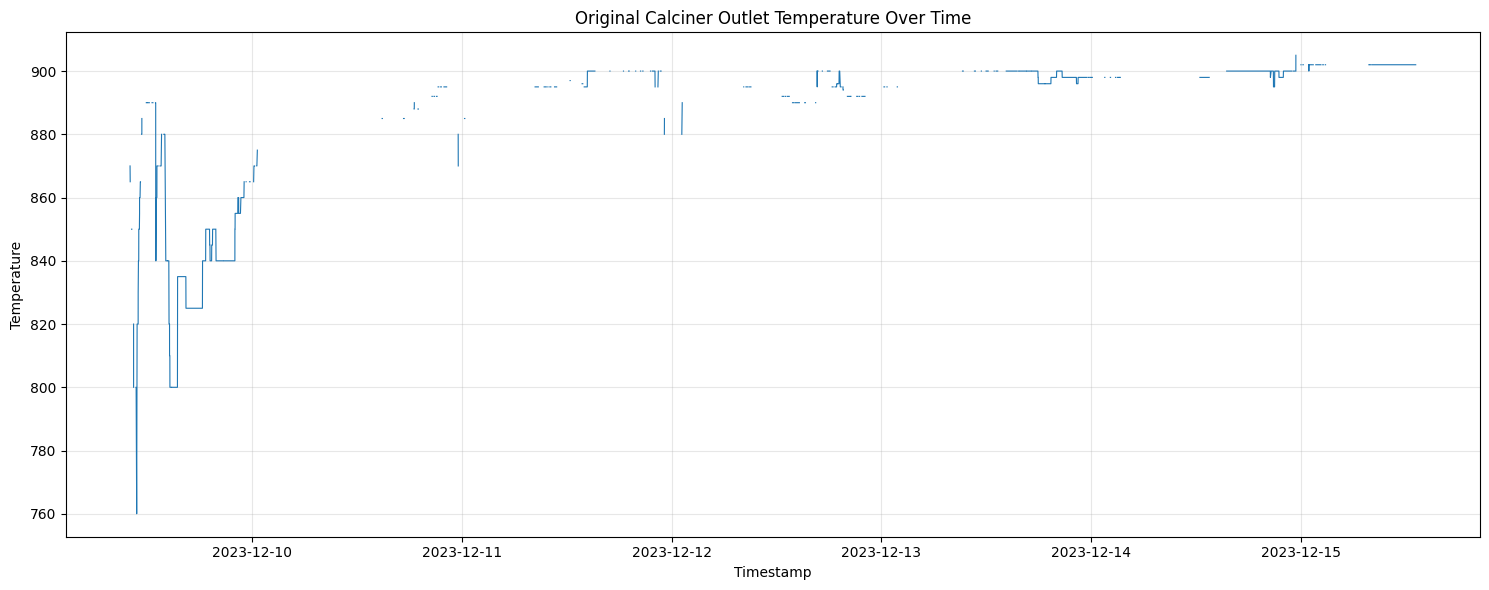

In [ ]:

import matplotlib.pyplot as plt

temp_plot = sensor_data["calciner_outlet_temperature"].copy()
temp_plot["timestamp"] = pd.to_datetime(temp_plot["timestamp"])
temp_plot = temp_plot.sort_values("timestamp").copy()

# Break the line across gaps longer than 5 minutes
temp_plot["gap_minutes"] = (
    temp_plot["timestamp"].diff().dt.total_seconds() / 60
)

temp_plot["plot_value"] = temp_plot["value"].astype(float)
temp_plot.loc[temp_plot["gap_minutes"] > 5, "plot_value"] = float("nan")

plt.figure(figsize=(15, 6))
plt.plot(
    temp_plot["timestamp"],
    temp_plot["plot_value"],
    linewidth=0.8
)

plt.title("Original Calciner Outlet Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

temp_changes = temp_plot.copy()

temp_changes["previous_temperature"] = temp_changes["value"].shift(1)
temp_changes["change"] = (
    temp_changes["value"] - temp_changes["previous_temperature"]
).abs()

# Ignore changes across gaps longer than 5 minutes
temp_changes.loc[temp_changes["gap_minutes"] > 5, "change"] = float("nan")

largest_changes = temp_changes.nlargest(15, "change")[
    ["timestamp", "previous_temperature", "value", "change", "gap_minutes"]
]

print("Largest temperature changes without long data gaps:")
print(largest_changes.to_string(index=False))


Largest temperature changes without long data gaps:
          timestamp  previous_temperature  value  change  gap_minutes
2023-12-09 12:57:53                 890.0  840.0    50.0     0.333333
2023-12-09 10:47:02                 800.0  760.0    40.0     3.850000
2023-12-09 10:49:06                 760.0  800.0    40.0     2.066667
2023-12-09 15:27:56                 800.0  835.0    35.0     1.050000
2023-12-09 10:25:43                 840.0  820.0    20.0     1.083333
2023-12-09 10:25:49                 820.0  800.0    20.0     0.100000
2023-12-09 10:49:54                 800.0  820.0    20.0     0.800000
2023-12-09 13:01:52                 840.0  860.0    20.0     2.100000
2023-12-09 14:03:27                 880.0  860.0    20.0     2.950000
2023-12-09 14:06:53                 860.0  840.0    20.0     3.433333
2023-12-09 14:29:13                 840.0  820.0    20.0     1.583333
2023-12-11 23:10:31                 900.0  880.0    20.0     1.433333
2023-12-10 23:34:43                 89

In [ ]:

event_time = pd.Timestamp("2023-12-09 12:57:53")

sensors_to_compare = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "raw_feed",
    "kiln_oil_flow"
]

for sensor_name in sensors_to_compare:
    df = sensor_data[sensor_name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.sort_values("timestamp")

    # Get the closest reading before and after the event
    before = df[df["timestamp"] <= event_time].tail(1)
    after = df[df["timestamp"] > event_time].head(1)

    print("\n" + "=" * 55)
    print("Sensor:", sensor_name)

    if not before.empty:
        print(
            "Before:",
            before["timestamp"].iloc[0],
            "| Value:",
            before["value"].iloc[0]
        )

    if not after.empty:
        print(
            "After:",
            after["timestamp"].iloc[0],
            "| Value:",
            after["value"].iloc[0]
        )



Sensor: calciner_outlet_temperature
Before: 2023-12-09 12:57:53 | Value: 840.0
After: 2023-12-09 12:59:33 | Value: 840.0

Sensor: kiln_current
Before: 2023-12-09 12:57:53 | Value: 423.74
After: 2023-12-09 12:57:56 | Value: 415.62

Sensor: calciner_outlet_pressure
Before: 2023-12-09 12:57:53 | Value: -522.57
After: 2023-12-09 12:57:56 | Value: -534.72

Sensor: raw_feed
Before: 2023-12-09 12:57:20 | Value: 200.0
After: 2023-12-09 12:59:33 | Value: 200.0

Sensor: kiln_oil_flow
Before: 2023-12-09 12:57:20 | Value: 65.0
After: 2023-12-09 12:59:33 | Value: 65.0


In [ ]:

temp_df = sensor_data["calciner_outlet_temperature"].copy()
temp_df["timestamp"] = pd.to_datetime(temp_df["timestamp"])
temp_df = temp_df.sort_values("timestamp")

event_time = pd.Timestamp("2023-12-09 12:57:53")

window = temp_df[
    (temp_df["timestamp"] >= event_time - pd.Timedelta(minutes=2)) &
    (temp_df["timestamp"] <= event_time + pd.Timedelta(minutes=2))
].copy()

window["previous_value"] = window["value"].shift(1)
window["change"] = window["value"] - window["previous_value"]

print(window[
    ["timestamp", "value", "previous_value", "change"]
].to_string(index=False))


          timestamp  value  previous_value  change
2023-12-09 12:56:07  890.0             NaN     NaN
2023-12-09 12:56:20  890.0           890.0     0.0
2023-12-09 12:57:20  890.0           890.0     0.0
2023-12-09 12:57:33  890.0           890.0     0.0
2023-12-09 12:57:53  840.0           890.0   -50.0
2023-12-09 12:59:33  840.0           840.0     0.0
2023-12-09 12:59:46  840.0           840.0     0.0


In [ ]:

event_time = pd.Timestamp("2023-12-09 12:57:53")

sensor_names = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "raw_feed",
    "kiln_oil_flow"
]

for sensor_name in sensor_names:
    df = sensor_data[sensor_name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.sort_values("timestamp")

    window = df[
        (df["timestamp"] >= event_time - pd.Timedelta(minutes=1)) &
        (df["timestamp"] <= event_time + pd.Timedelta(minutes=1))
    ]

    print("\n" + "=" * 55)
    print(sensor_name)
    print("Number of readings:", len(window))

    print(window[["timestamp", "value"]].to_string(index=False))



calciner_outlet_temperature
Number of readings: 3
          timestamp  value
2023-12-09 12:57:20  890.0
2023-12-09 12:57:33  890.0
2023-12-09 12:57:53  840.0

kiln_current
Number of readings: 27
          timestamp  value
2023-12-09 12:56:55 478.51
2023-12-09 12:56:58 446.02
2023-12-09 12:57:01 417.94
2023-12-09 12:57:04 410.05
2023-12-09 12:57:07 443.23
2023-12-09 12:57:20 462.96
2023-12-09 12:57:33 441.84
2023-12-09 12:57:38 454.14
2023-12-09 12:57:41 486.40
2023-12-09 12:57:44 483.61
2023-12-09 12:57:47 464.35
2023-12-09 12:57:50 453.45
2023-12-09 12:57:53 423.74
2023-12-09 12:57:56 415.62
2023-12-09 12:57:59 418.17
2023-12-09 12:58:02 432.56
2023-12-09 12:58:06 485.47
2023-12-09 12:58:09 494.75
2023-12-09 12:58:14 487.79
2023-12-09 12:58:18 442.31
2023-12-09 12:58:21 414.23
2023-12-09 12:58:34 474.56
2023-12-09 12:58:40 463.19
2023-12-09 12:58:43 451.13
2023-12-09 12:58:46 434.18
2023-12-09 12:58:49 400.30
2023-12-09 12:58:52 400.77

calciner_outlet_pressure
Number of readings: 26

In [ ]:

# Create a review table for large temperature changes

event_threshold = 20  # Temperature units; preliminary review threshold

events = temp_changes[
    temp_changes["change"].abs() >= event_threshold
].copy()

events["review_status"] = "Needs engineering review"
events["event_type"] = "Large temperature change"

events = events.rename(columns={
    "timestamp": "event_time",
    "previous_temperature": "temperature_before",
    "value": "temperature_after",
    "change": "temperature_change"
})

events = events[
    [
        "event_time",
        "temperature_before",
        "temperature_after",
        "temperature_change",
        "gap_minutes",
        "event_type",
        "review_status"
    ]
].sort_values("event_time")

print("Events requiring review:", len(events))
display(events.head(20))

# Save the review table
events.to_csv("temperature_events_for_review.csv", index=False)
print("\nSaved: temperature_events_for_review.csv")


Events requiring review: 12


,event_time,temperature_before,temperature_after,temperature_change,gap_minutes,event_type,review_status
7,2023-12-09 10:25:43,840.0,820.0,20.0,1.083333,Large temperature change,Needs engineering review
8,2023-12-09 10:25:49,820.0,800.0,20.0,0.100000,Large temperature change,Needs engineering review
12,2023-12-09 10:47:02,800.0,760.0,40.0,3.850000,Large temperature change,Needs engineering review
13,2023-12-09 10:49:06,760.0,800.0,40.0,2.066667,Large temperature change,Needs engineering review
14,2023-12-09 10:49:54,800.0,820.0,20.0,0.800000,Large temperature change,Needs engineering review
63,2023-12-09 12:57:53,890.0,840.0,50.0,0.333333,Large temperature change,Needs engineering review
66,2023-12-09 13:01:52,840.0,860.0,20.0,2.100000,Large temperature change,Needs engineering review
95,2023-12-09 14:03:27,880.0,860.0,20.0,2.950000,Large temperature change,Needs engineering review
96,2023-12-09 14:06:53,860.0,840.0,20.0,3.433333,Large temperature change,Needs engineering review
106,2023-12-09 14:29:13,840.0,820.0,20.0,1.583333,Large temperature change,Needs engineering review



Saved: temperature_events_for_review.csv


In [ ]:

# Group nearby temperature events into review episodes

events_sorted = events.sort_values("event_time").copy()

events_sorted["time_since_previous_minutes"] = (
    events_sorted["event_time"].diff().dt.total_seconds() / 60
)

# Start a new episode if events are at least 10 minutes apart
events_sorted["new_episode"] = (
    events_sorted["time_since_previous_minutes"].isna()
    | (events_sorted["time_since_previous_minutes"] >= 10)
)

events_sorted["episode_id"] = events_sorted["new_episode"].cumsum()

episodes = events_sorted.groupby("episode_id").agg(
    episode_start=("event_time", "min"),
    episode_end=("event_time", "max"),
    number_of_events=("event_time", "count"),
    largest_absolute_change=("temperature_change",
                             lambda values: values.abs().max()),
    minimum_temperature=("temperature_after", "min"),
    maximum_temperature=("temperature_after", "max")
).reset_index(drop=True)

print("Number of review episodes:", len(episodes))
display(episodes)


Number of review episodes: 7


,episode_start,episode_end,number_of_events,largest_absolute_change,minimum_temperature,maximum_temperature
0,2023-12-09 10:25:43,2023-12-09 10:25:49,2,20.0,800.0,820.0
1,2023-12-09 10:47:02,2023-12-09 10:49:54,3,40.0,760.0,820.0
2,2023-12-09 12:57:53,2023-12-09 13:01:52,2,50.0,840.0,860.0
3,2023-12-09 14:03:27,2023-12-09 14:06:53,2,20.0,840.0,860.0
4,2023-12-09 14:29:13,2023-12-09 14:29:13,1,20.0,820.0,820.0
5,2023-12-09 15:27:56,2023-12-09 15:27:56,1,35.0,835.0,835.0
6,2023-12-11 23:10:31,2023-12-11 23:10:31,1,20.0,880.0,880.0


In [ ]:

episode_start = pd.Timestamp("2023-12-09 10:47:02")
episode_end = pd.Timestamp("2023-12-09 10:49:54")

sensor_names = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "raw_feed",
    "kiln_oil_flow"
]

results = []

for sensor_name in sensor_names:
    df = sensor_data[sensor_name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])

    window = df[
        (df["timestamp"] >= episode_start - pd.Timedelta(minutes=1)) &
        (df["timestamp"] <= episode_end + pd.Timedelta(minutes=1))
    ]

    results.append({
        "sensor": sensor_name,
        "readings": len(window),
        "minimum": window["value"].min() if len(window) else None,
        "maximum": window["value"].max() if len(window) else None,
        "range": (
            window["value"].max() - window["value"].min()
            if len(window) else None
        )
    })

episode_sensor_summary = pd.DataFrame(results)
display(episode_sensor_summary)


,sensor,readings,minimum,maximum,range
0,calciner_outlet_temperature,3,760.00,820.00,60.00
1,kiln_current,82,362.25,505.20,142.95
2,calciner_outlet_pressure,82,-708.91,-409.14,299.77
3,raw_feed,0,NaN,NaN,NaN
4,kiln_oil_flow,4,48.00,52.00,4.00


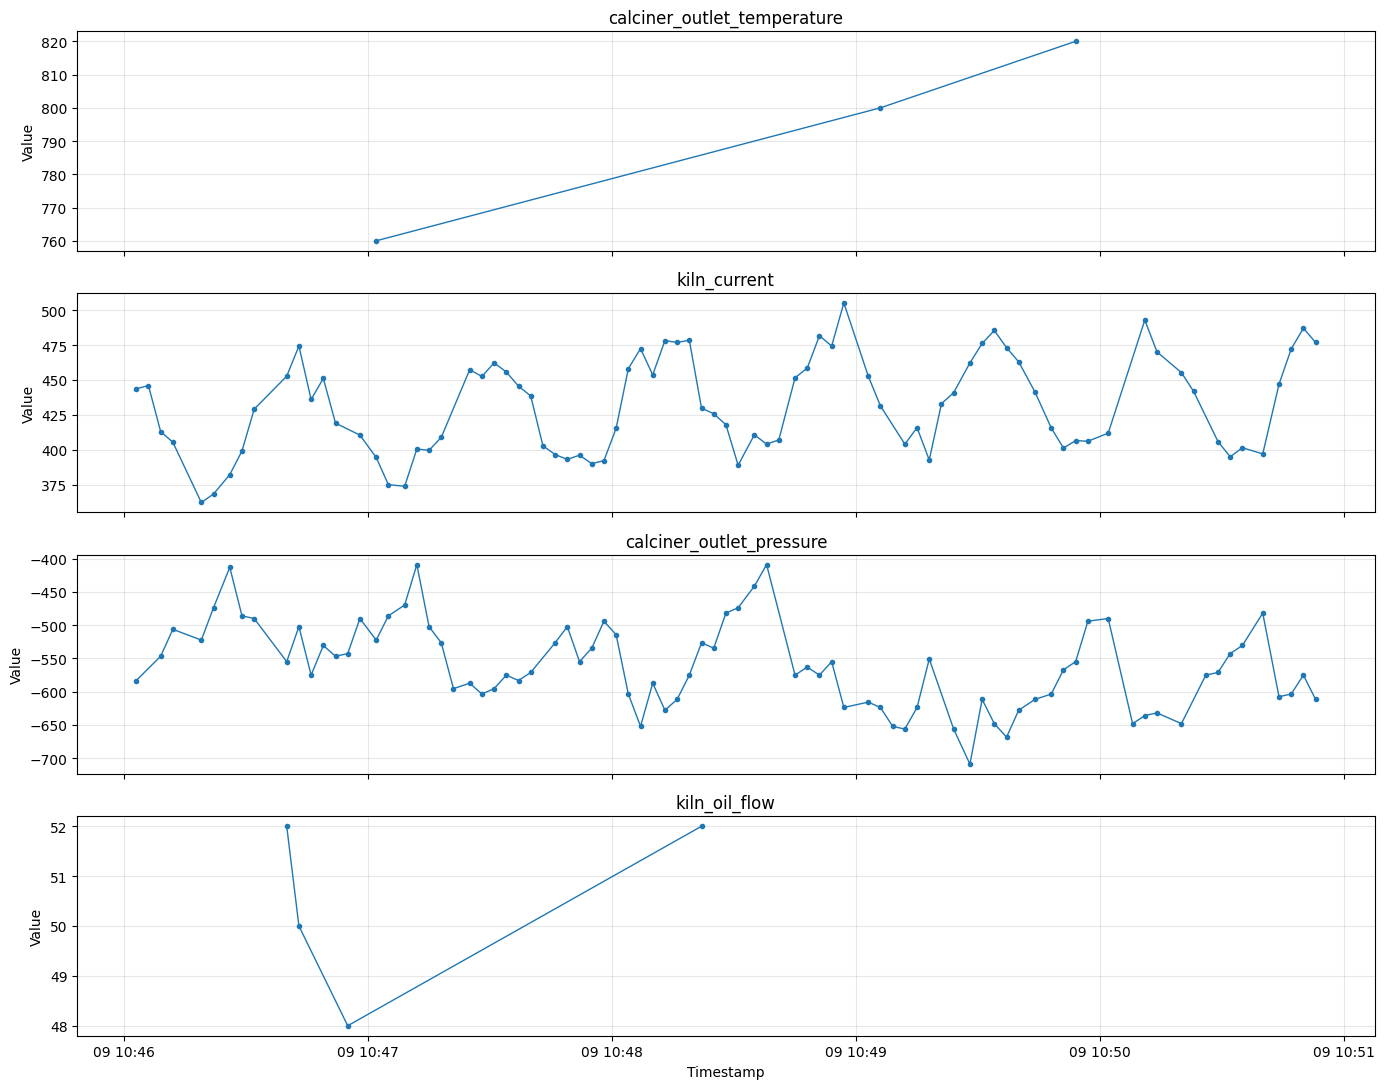

In [ ]:

import matplotlib.pyplot as plt

episode_start = pd.Timestamp("2023-12-09 10:46:02")
episode_end = pd.Timestamp("2023-12-09 10:50:54")

plot_sensors = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "kiln_oil_flow"
]

fig, axes = plt.subplots(
    len(plot_sensors), 1,
    figsize=(14, 11),
    sharex=True
)

for ax, sensor_name in zip(axes, plot_sensors):
    df = sensor_data[sensor_name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])

    window = df[
        (df["timestamp"] >= episode_start) &
        (df["timestamp"] <= episode_end)
    ].sort_values("timestamp")

    ax.plot(window["timestamp"], window["value"], marker=".", linewidth=1)
    ax.set_title(sensor_name)
    ax.set_ylabel("Value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets

from IPython.display import display, clear_output, HTML

# ==========================================
# 1. Prepare sensor and date options
# ==========================================

sensor_names = list(sensor_data.keys())

sensor_options = [
    (name.replace("_", " ").title(), name)
    for name in sensor_names
]

sensor_dropdown = widgets.Dropdown(
    options=sensor_options,
    value="calciner_outlet_temperature",
    description="Sensor:",
    layout=widgets.Layout(width="420px")
)

temperature_df = sensor_data["calciner_outlet_temperature"].copy()
temperature_df["timestamp"] = pd.to_datetime(
    temperature_df["timestamp"]
)

available_dates = sorted(
    temperature_df["timestamp"].dt.strftime("%Y-%m-%d").unique()
)

date_options = [("All available dates", "all")]
date_options += [(day, day) for day in available_dates]

date_dropdown = widgets.Dropdown(
    options=date_options,
    value="all",
    description="Date:",
    layout=widgets.Layout(width="300px")
)

output = widgets.Output()

# ==========================================
# 2. Dashboard update function
# ==========================================

def update_dashboard(change=None):

    with output:
        clear_output(wait=True)

        sensor_name = sensor_dropdown.value
        selected_date = date_dropdown.value

        df = sensor_data[sensor_name].copy()
        df["timestamp"] = pd.to_datetime(df["timestamp"])
        df = df.sort_values("timestamp").copy()

        if selected_date != "all":
            df = df[
                df["timestamp"].dt.strftime("%Y-%m-%d")
                == selected_date
            ].copy()

        if df.empty:
            display(HTML("<h3>No readings available.</h3>"))
            return

        # Calculate data quality indicators
        df["gap_minutes"] = (
            df["timestamp"].diff().dt.total_seconds() / 60
        )

        df["plot_value"] = df["value"].astype(float)

        # Break the line across gaps longer than 5 minutes
        df.loc[
            df["gap_minutes"] > 5,
            "plot_value"
        ] = float("nan")

        reading_count = len(df)
        missing_count = int(df["value"].isna().sum())
        gap_count = int((df["gap_minutes"] > 5).sum())

        display(HTML(
            f"""
            <div style="display:flex;gap:12px;flex-wrap:wrap;">
                <div style="padding:14px;border:1px solid #ccc;
                border-radius:8px;min-width:100px;">
                    <b>Readings</b>
                    <h2>{reading_count:,}</h2>
                </div>
                <div style="padding:14px;border:1px solid #ccc;
                border-radius:8px;min-width:100px;">
                    <b>Missing values</b>
                    <h2>{missing_count:,}</h2>
                </div>
                <div style="padding:14px;border:1px solid #ccc;
                border-radius:8px;min-width:100px;">
                    <b>Gaps over 5 min</b>
                    <h2>{gap_count:,}</h2>
                </div>
            </div>
            """
        ))

        # Interactive sensor chart
        fig = go.Figure()

        fig.add_trace(
            go.Scatter(
                x=df["timestamp"],
                y=df["plot_value"],
                mode="lines",
                name=sensor_name.replace("_", " ").title(),
                connectgaps=False,
                hovertemplate=(
                    "Time: %{x}<br>"
                    "Value: %{y}<extra></extra>"
                )
            )
        )

        fig.update_layout(
            title=sensor_name.replace("_", " ").title(),
            xaxis_title="Timestamp",
            yaxis_title="Sensor value",
            template="plotly_white",
            height=450,
            hovermode="x unified",
            margin=dict(l=50, r=30, t=60, b=50)
        )

        # Explicit renderer for Google Colab
        fig.show(renderer="colab")

        # Temperature event review table
        display(HTML("<h3>Temperature Events for Review</h3>"))

        if "events" in globals() and not events.empty:

            event_table = events.copy()

            if "event_time" in event_table.columns:
                event_table["event_time"] = pd.to_datetime(
                    event_table["event_time"]
                )

                if selected_date != "all":
                    event_table = event_table[
                        event_table["event_time"].dt.strftime(
                            "%Y-%m-%d"
                        ) == selected_date
                    ]

            display(event_table.head(100))

        else:
            display(HTML(
                "<p>Temperature event table is not available yet.</p>"
            ))

# ==========================================
# 3. Connect dropdowns to dashboard
# ==========================================

sensor_dropdown.observe(update_dashboard, names="value")
date_dropdown.observe(update_dashboard, names="value")

# ==========================================
# 4. Display dashboard
# ==========================================

display(HTML(
    """
    <h1>AI Cement Plant Monitoring Dashboard</h1>
    <p>Sensor monitoring and preliminary event review</p>
    """
))

display(widgets.HBox([sensor_dropdown, date_dropdown]))
display(output)

update_dashboard()


Output()

In [ ]:

test_df = sensor_data["calciner_outlet_temperature"].copy()
test_df["timestamp"] = pd.to_datetime(test_df["timestamp"])
test_df = test_df.sort_values("timestamp")

test_fig = go.Figure()

test_fig.add_trace(
    go.Scatter(
        x=test_df["timestamp"],
        y=test_df["value"],
        mode="lines",
        connectgaps=False,
        name="Calciner Temperature"
    )
)

test_fig.update_layout(
    title="Calciner Temperature Test",
    xaxis_title="Timestamp",
    yaxis_title="Temperature",
    template="plotly_white",
    height=400
)

test_fig.show(renderer="colab")


In [ ]:

import pandas as pd
import plotly.graph_objects as go
from IPython.display import display

df = sensor_data["calciner_outlet_temperature"].copy()
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp")

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=df["timestamp"],
        y=df["value"],
        mode="lines",
        name="Temperature",
        connectgaps=False
    )
)

fig.update_layout(
    title="Calciner Temperature - Direct Display Test",
    xaxis_title="Timestamp",
    yaxis_title="Temperature",
    template="plotly_white",
    height=400
)

display(fig)


In [ ]:

from plotly.subplots import make_subplots
import plotly.graph_objects as go
import pandas as pd

selected_sensors = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure"
]

selected_day = "2023-12-09"

fig = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    subplot_titles=[
        "Calciner Outlet Temperature",
        "Kiln Current",
        "Calciner Outlet Pressure"
    ],
    vertical_spacing=0.08
)

for row, sensor_name in enumerate(selected_sensors, start=1):
    df = sensor_data[sensor_name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df[
        df["timestamp"].dt.strftime("%Y-%m-%d") == selected_day
    ].sort_values("timestamp")

    gap_minutes = df["timestamp"].diff().dt.total_seconds() / 60
    values = df["value"].astype(float).copy()
    values.loc[gap_minutes > 5] = float("nan")

    fig.add_trace(
        go.Scatter(
            x=df["timestamp"],
            y=values,
            mode="lines",
            connectgaps=False,
            name=sensor_name
        ),
        row=row,
        col=1
    )

fig.update_layout(
    title="Cement Plant - Sensor Comparison",
    template="plotly_white",
    height=850,
    showlegend=False
)

fig.update_xaxes(title_text="Time")
fig.show(renderer="colab")


In [ ]:

import pandas as pd
import ipywidgets as widgets

from IPython.display import display, clear_output, HTML
from google.colab import files

# ==========================================
# 1. Prepare the Anomaly Review Panel
# ==========================================

if "events" not in globals() or events.empty:
    raise ValueError(
        "The events table is missing. Run the temperature event "
        "detection cell first."
    )

review_data = events.copy()

# Standardize event timestamps
if "event_time" in review_data.columns:
    review_data["event_time"] = pd.to_datetime(
        review_data["event_time"]
    )
elif "timestamp" in review_data.columns:
    review_data = review_data.rename(
        columns={"timestamp": "event_time"}
    )
    review_data["event_time"] = pd.to_datetime(
        review_data["event_time"]
    )
else:
    raise ValueError(
        "No event timestamp column was found in events."
    )

# Add a review status if it does not exist
if "review_status" not in review_data.columns:
    review_data["review_status"] = "Needs engineering review"

# Add a readable event ID
review_data = review_data.sort_values("event_time").reset_index(drop=True)
review_data.insert(0, "event_id", range(1, len(review_data) + 1))

# ==========================================
# 2. Create filters
# ==========================================

review_dates = sorted(
    review_data["event_time"].dt.strftime("%Y-%m-%d").unique()
)

date_filter = widgets.Dropdown(
    options=[("All dates", "all")] +
            [(day, day) for day in review_dates],
    value="all",
    description="Date:",
    layout=widgets.Layout(width="300px")
)

change_filter = widgets.Dropdown(
    options=[
        ("All changes", 0),
        ("20 or more", 20),
        ("30 or more", 30),
        ("40 or more", 40),
        ("50 or more", 50)
    ],
    value=0,
    description="Min change:",
    layout=widgets.Layout(width="300px")
)

# ==========================================
# 3. Create panel buttons and output
# ==========================================

refresh_button = widgets.Button(
    description="Refresh Review",
    button_style="primary",
    icon="refresh"
)

export_button = widgets.Button(
    description="Export CSV",
    button_style="success",
    icon="download"
)

review_output = widgets.Output()

# Store the currently filtered rows
filtered_review = review_data.copy()

# ==========================================
# 4. Update the review table
# ==========================================

def refresh_review(change=None):

    global filtered_review

    df = review_data.copy()

    selected_date = date_filter.value
    minimum_change = change_filter.value

    if selected_date != "all":
        df = df[
            df["event_time"].dt.strftime("%Y-%m-%d")
            == selected_date
        ]

    if "temperature_change" in df.columns:
        df = df[
            df["temperature_change"].abs() >= minimum_change
        ]
    elif "change" in df.columns:
        df = df[df["change"].abs() >= minimum_change]

    filtered_review = df.copy()

    with review_output:
        clear_output(wait=True)

        display(HTML(
            f"""
            <div style="display:flex;gap:12px;flex-wrap:wrap;">
                <div style="border:1px solid #ccc;padding:12px;
                border-radius:8px;">
                    <b>Events shown</b>
                    <h2>{len(df)}</h2>
                </div>
                <div style="border:1px solid #ccc;padding:12px;
                border-radius:8px;">
                    <b>Dates covered</b>
                    <h2>{df["event_time"].dt.strftime("%Y-%m-%d").nunique()
                    if not df.empty else 0}</h2>
                </div>
            </div>
            """
        ))

        if df.empty:
            print("No events match these filters.")
            return

        preferred_columns = [
            "event_id",
            "event_time",
            "temperature_before",
            "temperature_after",
            "temperature_change",
            "gap_minutes",
            "event_type",
            "review_status"
        ]

        visible_columns = [
            col for col in preferred_columns if col in df.columns
        ]

        display(
            df[visible_columns].reset_index(drop=True)
        )

# ==========================================
# 5. Export filtered events to CSV
# ==========================================

def export_review(button=None):

    if filtered_review.empty:
        print("No events to export. Change the filters first.")
        return

    export_df = filtered_review.copy()

    filename = "cement_plant_anomaly_review.csv"

    export_df.to_csv(
        filename,
        index=False,
        encoding="utf-8-sig"
    )

    files.download(filename)

# ==========================================
# 6. Connect buttons and display dashboard
# ==========================================

refresh_button.on_click(refresh_review)
export_button.on_click(export_review)

display(HTML(
    """
    <h1>AI Cement Plant Monitoring</h1>
    <h2>Anomaly Review Panel</h2>
    <p>
        Review unusual temperature changes.
        Events require engineering verification and are not confirmed faults.
    </p>
    """
))

display(widgets.HBox([date_filter, change_filter]))
display(widgets.HBox([refresh_button, export_button]))
display(review_output)

refresh_review()


Output()

In [ ]:

import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets

from plotly.subplots import make_subplots
from IPython.display import display, HTML

# ==========================================
# 1. Prepare event selection
# ==========================================

investigation_events = events.copy()

if "event_time" not in investigation_events.columns:
    investigation_events = investigation_events.rename(
        columns={"timestamp": "event_time"}
    )

investigation_events["event_time"] = pd.to_datetime(
    investigation_events["event_time"]
)

investigation_events = (
    investigation_events.sort_values("event_time").reset_index(drop=True)
)

event_options = []

for i, row in investigation_events.iterrows():
    event_time = row["event_time"]
    change = row.get(
        "temperature_change",
        row.get("change", float("nan"))
    )

    label = f"{event_time} | Change: {change:+.1f}"
    event_options.append((label, i))

event_picker = widgets.Dropdown(
    options=event_options,
    description="Select event:",
    layout=widgets.Layout(width="650px")
)

window_minutes = widgets.Dropdown(
    options=[
        ("2 minutes before/after", 2),
        ("5 minutes before/after", 5),
        ("10 minutes before/after", 10),
    ],
    value=2,
    description="Window:",
    layout=widgets.Layout(width="350px")
)

investigation_button = widgets.Button(
    description="Investigate Event",
    button_style="primary",
    icon="search"
)

# ==========================================
# 2. Investigate selected event
# ==========================================

def investigate_event(button=None):

    event_row = investigation_events.loc[event_picker.value]
    event_time = event_row["event_time"]
    minutes = window_minutes.value

    start_time = event_time - pd.Timedelta(minutes=minutes)
    end_time = event_time + pd.Timedelta(minutes=minutes)

    print("\nEvent Investigation")
    print("=" * 55)
    print("Event time:", event_time)
    print("Review window:", start_time, "to", end_time)

    if "temperature_before" in event_row.index:
        print("Temperature before:", event_row["temperature_before"])

    if "temperature_after" in event_row.index:
        print("Temperature after:", event_row["temperature_after"])

    if "temperature_change" in event_row.index:
        print("Temperature change:", event_row["temperature_change"])

    sensor_names = [
        "calciner_outlet_temperature",
        "kiln_current",
        "calciner_outlet_pressure",
        "raw_feed",
        "kiln_oil_flow"
    ]

    fig = make_subplots(
        rows=len(sensor_names),
        cols=1,
        shared_xaxes=True,
        subplot_titles=[
            name.replace("_", " ").title()
            for name in sensor_names
        ],
        vertical_spacing=0.04
    )

    summary = []

    for row_number, sensor_name in enumerate(sensor_names, start=1):

        df = sensor_data[sensor_name].copy()
        df["timestamp"] = pd.to_datetime(df["timestamp"])
        df = df.sort_values("timestamp")

        window = df[
            (df["timestamp"] >= start_time) &
            (df["timestamp"] <= end_time)
        ].copy()

        summary.append({
            "sensor": sensor_name,
            "readings_in_window": len(window),
            "minimum": window["value"].min() if not window.empty else None,
            "maximum": window["value"].max() if not window.empty else None,
            "range": (
                window["value"].max() - window["value"].min()
                if not window.empty else None
            )
        })

        if window.empty:
            continue

        gaps = window["timestamp"].diff().dt.total_seconds() / 60
        values = window["value"].astype(float).copy()

        # Do not connect readings across long gaps
        values.loc[gaps > 5] = float("nan")

        fig.add_trace(
            go.Scatter(
                x=window["timestamp"],
                y=values,
                mode="lines+markers",
                name=sensor_name,
                connectgaps=False,
                showlegend=False
            ),
            row=row_number,
            col=1
        )

        fig.add_vline(
            x=event_time,
            line_dash="dash",
            line_color="red",
            row=row_number,
            col=1
        )

        fig.update_yaxes(
            title_text="Value",
            row=row_number,
            col=1
        )

    fig.update_layout(
        title="Sensor Readings Around Selected Event",
        template="plotly_white",
        height=1100,
        hovermode="x unified"
    )

    fig.update_xaxes(title_text="Timestamp")

    display(fig)

    print("\nSensor Summary")
    display(pd.DataFrame(summary))

    print(
        "\nImportant: This analysis shows nearby readings only. "
        "It does not confirm a plant fault or its cause."
    )

# ==========================================
# 3. Display controls
# ==========================================

investigation_button.on_click(investigate_event)

display(HTML(
    "<h2>Event Investigation</h2>"
    "<p>Select a temperature event and the time window to inspect.</p>"
))

display(event_picker)
display(window_minutes)
display(investigation_button)


Dropdown(description='Select event:', layout=Layout(width='650px'), options=(('2023-12-09 10:25:43 | Change: +…

Dropdown(description='Window:', layout=Layout(width='350px'), options=(('2 minutes before/after', 2), ('5 minu…

Button(button_style='primary', description='Investigate Event', icon='search', style=ButtonStyle())

In [ ]:

import pandas as pd
from IPython.display import display, HTML

# ==========================================
# Automatic Event Summary
# ==========================================

event_summary_rows = []

sensor_names = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "raw_feed",
    "kiln_oil_flow"
]

for _, event in events.iterrows():

    event_time = pd.to_datetime(
        event.get("event_time", event.get("timestamp"))
    )

    temperature_before = event.get("temperature_before", None)
    temperature_after = event.get("temperature_after", None)
    temperature_change = event.get(
        "temperature_change",
        event.get("change", None)
    )

    window_start = event_time - pd.Timedelta(minutes=2)
    window_end = event_time + pd.Timedelta(minutes=2)

    row = {
        "event_time": event_time,
        "temperature_before": temperature_before,
        "temperature_after": temperature_after,
        "temperature_change": temperature_change
    }

    available_sensors = 0
    changed_sensors = []
    missing_sensors = []

    for sensor_name in sensor_names:

        df = sensor_data[sensor_name].copy()
        df["timestamp"] = pd.to_datetime(df["timestamp"])

        window = df[
            (df["timestamp"] >= window_start) &
            (df["timestamp"] <= window_end)
        ].copy()

        count = len(window)
        row[sensor_name + "_readings"] = count

        if count == 0:
            row[sensor_name + "_range"] = None
            missing_sensors.append(sensor_name)
            continue

        available_sensors += 1

        values = pd.to_numeric(window["value"], errors="coerce").dropna()

        if values.empty:
            row[sensor_name + "_range"] = None
            missing_sensors.append(sensor_name)
            continue

        value_range = values.max() - values.min()
        row[sensor_name + "_range"] = round(value_range, 2)

        # Flag variation for engineering review, not fault diagnosis
        if count >= 2 and value_range > 0:
            changed_sensors.append(sensor_name)

    row["sensors_with_readings"] = available_sensors
    row["sensors_with_variation"] = ", ".join(changed_sensors)
    row["sensors_without_data"] = ", ".join(missing_sensors)

    if available_sensors >= 4:
        row["data_coverage"] = "Reasonable coverage"
    else:
        row["data_coverage"] = "Limited data - review carefully"

    row["review_recommendation"] = (
        "Engineering review required; cause not confirmed"
    )

    event_summary_rows.append(row)

event_summary = pd.DataFrame(event_summary_rows)

# Display a concise summary
summary_columns = [
    "event_time",
    "temperature_before",
    "temperature_after",
    "temperature_change",
    "sensors_with_readings",
    "data_coverage",
    "sensors_with_variation",
    "sensors_without_data",
    "review_recommendation"
]

display(HTML("<h2>Automatic Event Summary</h2>"))
display(event_summary[summary_columns])

# Export complete summary
output_file = "automatic_event_summary.csv"
event_summary.to_csv(output_file, index=False)

print("\nSaved report:", output_file)

try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("Download the CSV from the notebook file browser.")


,event_time,temperature_before,temperature_after,temperature_change,sensors_with_readings,data_coverage,sensors_with_variation,sensors_without_data,review_recommendation
0,2023-12-09 10:25:43,840.0,820.0,20.0,5,Reasonable coverage,"calciner_outlet_temperature, kiln_current, cal...",,Engineering review required; cause not confirmed
1,2023-12-09 10:25:49,820.0,800.0,20.0,4,Reasonable coverage,"calciner_outlet_temperature, kiln_current, cal...",raw_feed,Engineering review required; cause not confirmed
2,2023-12-09 10:47:02,800.0,760.0,40.0,4,Reasonable coverage,"kiln_current, calciner_outlet_pressure, kiln_o...",raw_feed,Engineering review required; cause not confirmed
3,2023-12-09 10:49:06,760.0,800.0,40.0,4,Reasonable coverage,"calciner_outlet_temperature, kiln_current, cal...",raw_feed,Engineering review required; cause not confirmed
4,2023-12-09 10:49:54,800.0,820.0,20.0,4,Reasonable coverage,"calciner_outlet_temperature, kiln_current, cal...",raw_feed,Engineering review required; cause not confirmed
5,2023-12-09 12:57:53,890.0,840.0,50.0,5,Reasonable coverage,"calciner_outlet_temperature, kiln_current, cal...",,Engineering review required; cause not confirmed
6,2023-12-09 13:01:52,840.0,860.0,20.0,4,Reasonable coverage,"kiln_current, calciner_outlet_pressure",raw_feed,Engineering review required; cause not confirmed
7,2023-12-09 14:03:27,880.0,860.0,20.0,5,Reasonable coverage,"kiln_current, calciner_outlet_pressure, kiln_o...",,Engineering review required; cause not confirmed
8,2023-12-09 14:06:53,860.0,840.0,20.0,4,Reasonable coverage,"kiln_current, calciner_outlet_pressure, kiln_o...",raw_feed,Engineering review required; cause not confirmed
9,2023-12-09 14:29:13,840.0,820.0,20.0,5,Reasonable coverage,"calciner_outlet_temperature, kiln_current, cal...",,Engineering review required; cause not confirmed



Saved report: automatic_event_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ==========================================
# Improved Event Review Priorities
# ==========================================

improved_summary = event_summary.copy()

# Calculate absolute temperature change
improved_summary["absolute_temperature_change"] = (
    pd.to_numeric(
        improved_summary["temperature_change"],
        errors="coerce"
    ).abs()
)

# Initial review priority based on change magnitude only
def assign_review_priority(change):
    if pd.isna(change):
        return "Insufficient information"
    elif change >= 40:
        return "High review priority"
    elif change >= 20:
        return "Review required"
    else:
        return "Routine review"

improved_summary["review_priority"] = (
    improved_summary["absolute_temperature_change"]
    .apply(assign_review_priority)
)

# Make the limitations explicit
improved_summary["priority_basis"] = (
    "Temperature change magnitude only; "
    "not a confirmed fault severity"
)

improved_summary = improved_summary.sort_values(
    "absolute_temperature_change",
    ascending=False
).reset_index(drop=True)

display(
    improved_summary[
        [
            "event_time",
            "temperature_before",
            "temperature_after",
            "temperature_change",
            "absolute_temperature_change",
            "data_coverage",
            "review_priority",
            "priority_basis"
        ]
    ]
)

improved_summary.to_csv(
    "improved_cement_event_review.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved: improved_cement_event_review.csv")


,event_time,temperature_before,temperature_after,temperature_change,absolute_temperature_change,data_coverage,review_priority,priority_basis
0,2023-12-09 12:57:53,890.0,840.0,50.0,50.0,Reasonable coverage,High review priority,Temperature change magnitude only; not a confi...
1,2023-12-09 10:49:06,760.0,800.0,40.0,40.0,Reasonable coverage,High review priority,Temperature change magnitude only; not a confi...
2,2023-12-09 10:47:02,800.0,760.0,40.0,40.0,Reasonable coverage,High review priority,Temperature change magnitude only; not a confi...
3,2023-12-09 15:27:56,800.0,835.0,35.0,35.0,Reasonable coverage,Review required,Temperature change magnitude only; not a confi...
4,2023-12-09 10:25:43,840.0,820.0,20.0,20.0,Reasonable coverage,Review required,Temperature change magnitude only; not a confi...
5,2023-12-09 10:25:49,820.0,800.0,20.0,20.0,Reasonable coverage,Review required,Temperature change magnitude only; not a confi...
6,2023-12-09 13:01:52,840.0,860.0,20.0,20.0,Reasonable coverage,Review required,Temperature change magnitude only; not a confi...
7,2023-12-09 10:49:54,800.0,820.0,20.0,20.0,Reasonable coverage,Review required,Temperature change magnitude only; not a confi...
8,2023-12-09 14:03:27,880.0,860.0,20.0,20.0,Reasonable coverage,Review required,Temperature change magnitude only; not a confi...
9,2023-12-09 14:06:53,860.0,840.0,20.0,20.0,Reasonable coverage,Review required,Temperature change magnitude only; not a confi...


Saved: improved_cement_event_review.csv


In [ ]:

import pandas as pd
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from google.colab import files

# Use the improved summary created in the previous cell
if "improved_summary" not in globals():
    raise NameError(
        "improved_summary not found. Run the cell that creates "
        "improved_summary first."
    )

dashboard_summary = improved_summary.copy()

# Ensure review priority exists
if "review_priority" not in dashboard_summary.columns:
    raise ValueError(
        "The review_priority column is missing. "
        "Run the improved summary cell first."
    )

priority_order = [
    "High review priority",
    "Review required",
    "Routine review",
    "Insufficient information"
]

# Sort rows by review priority, then by temperature change
dashboard_summary["priority_rank"] = (
    dashboard_summary["review_priority"]
    .map({p: i for i, p in enumerate(priority_order)})
    .fillna(len(priority_order))
)

dashboard_summary["absolute_temperature_change"] = pd.to_numeric(
    dashboard_summary["absolute_temperature_change"],
    errors="coerce"
)

dashboard_summary = dashboard_summary.sort_values(
    ["priority_rank", "absolute_temperature_change"],
    ascending=[True, False]
).reset_index(drop=True)

# KPI cards
total_events = len(dashboard_summary)
high_priority = (
    dashboard_summary["review_priority"] == "High review priority"
).sum()
review_required = (
    dashboard_summary["review_priority"] == "Review required"
).sum()

display(HTML("""
<div style="font-family:Arial; margin:10px 0 18px 0;">
    <h2 style="margin-bottom:4px;">Cement Plant — Event Review Dashboard</h2>
    <p style="color:#666; margin-top:0;">
        Temperature-change events requiring engineering review
    </p>
</div>
"""))

cards_html = f"""
<div style="display:flex; flex-wrap:wrap; gap:12px; font-family:Arial;">
  <div style="flex:1; min-width:150px; padding:18px; border:1px solid #ddd; border-radius:10px;">
    <div style="color:#666;">Total Events</div>
    <div style="font-size:30px; font-weight:bold;">{total_events}</div>
  </div>
  <div style="flex:1; min-width:150px; padding:18px; border:1px solid #ddd; border-radius:10px;">
    <div style="color:#666;">High Review Priority</div>
    <div style="font-size:30px; font-weight:bold;">{high_priority}</div>
  </div>
  <div style="flex:1; min-width:150px; padding:18px; border:1px solid #ddd; border-radius:10px;">
    <div style="color:#666;">Review Required</div>
    <div style="font-size:30px; font-weight:bold;">{review_required}</div>
  </div>
</div>
"""
display(HTML(cards_html))

display(HTML("""
<p style="font-size:12px; color:#777; margin-top:10px;">
Priority is based on temperature-change magnitude only. It does not confirm
equipment failure or indicate verified fault severity.
</p>
"""))

# Filter controls
priority_filter = widgets.Dropdown(
    options=["All priorities"] + priority_order,
    value="All priorities",
    description="Priority:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="350px")
)

refresh_button = widgets.Button(
    description="Apply Filter",
    button_style="primary",
    icon="filter"
)

download_button = widgets.Button(
    description="Download Filtered CSV",
    button_style="success",
    icon="download"
)

table_output = widgets.Output()
filtered_data = {"df": dashboard_summary.copy()}

def show_dashboard_table(_=None):
    selected_priority = priority_filter.value

    if selected_priority == "All priorities":
        filtered = dashboard_summary.copy()
    else:
        filtered = dashboard_summary[
            dashboard_summary["review_priority"] == selected_priority
        ].copy()

    filtered_data["df"] = filtered

    # Hide the internal sorting column
    visible_columns = [
        col for col in filtered.columns if col != "priority_rank"
    ]

    with table_output:
        clear_output(wait=True)
        display(HTML(
            f"<h4>Events shown: {len(filtered)}</h4>"
        ))
        if filtered.empty:
            print("No events match this filter.")
        else:
            display(
                filtered[visible_columns]
                .style
                .format(precision=2)
                .hide(axis="index")
            )

def download_filtered_csv(_):
    df_to_download = filtered_data["df"].drop(
        columns=["priority_rank"], errors="ignore"
    )
    filename = "cement_dashboard_event_review.csv"
    df_to_download.to_csv(
        filename, index=False, encoding="utf-8-sig"
    )
    files.download(filename)

refresh_button.on_click(show_dashboard_table)
download_button.on_click(download_filtered_csv)

display(widgets.HBox([priority_filter, refresh_button]))
display(download_button)
display(table_output)

# Show all events on first run
show_dashboard_table()


Button(button_style='success', description='Download Filtered CSV', icon='download', style=ButtonStyle())

Output()

In [ ]:

# Fix: sort before selecting the display columns

quality_summary = improved_summary.copy()

# Create the absolute change column
quality_summary["absolute_temperature_change"] = pd.to_numeric(
    quality_summary["temperature_change"],
    errors="coerce"
).abs()

# Count sensors with readings
sensor_reading_columns = [
    "calciner_outlet_temperature_readings",
    "kiln_current_readings",
    "calciner_outlet_pressure_readings",
    "raw_feed_readings",
    "kiln_oil_flow_readings"
]

for col in sensor_reading_columns:
    quality_summary[col] = pd.to_numeric(
        quality_summary[col], errors="coerce"
    ).fillna(0)

quality_summary["sensors_with_readings_count"] = (
    quality_summary[sensor_reading_columns].gt(0).sum(axis=1)
)

def assess_data_quality(row):
    count = row["sensors_with_readings_count"]
    if count <= 2:
        return "Insufficient data - investigate"
    elif count <= 3:
        return "Partial data - review carefully"
    return "More sensor data available"

quality_summary["data_quality_flag"] = quality_summary.apply(
    assess_data_quality, axis=1
)

# IMPORTANT: Sort the full DataFrame first
quality_summary = quality_summary.sort_values(
    by="absolute_temperature_change",
    ascending=False
).reset_index(drop=True)

# Then select columns for display
display_columns = [
    "event_time",
    "temperature_change",
    "review_priority",
    "sensors_with_readings_count",
    "data_quality_flag"
]

display(quality_summary[display_columns])


,event_time,temperature_change,review_priority,sensors_with_readings_count,data_quality_flag
0,2023-12-09 12:57:53,50.0,High review priority,5,More sensor data available
1,2023-12-09 10:49:06,40.0,High review priority,4,More sensor data available
2,2023-12-09 10:47:02,40.0,High review priority,4,More sensor data available
3,2023-12-09 15:27:56,35.0,Review required,5,More sensor data available
4,2023-12-09 10:25:43,20.0,Review required,5,More sensor data available
5,2023-12-09 10:25:49,20.0,Review required,4,More sensor data available
6,2023-12-09 13:01:52,20.0,Review required,4,More sensor data available
7,2023-12-09 10:49:54,20.0,Review required,4,More sensor data available
8,2023-12-09 14:03:27,20.0,Review required,5,More sensor data available
9,2023-12-09 14:06:53,20.0,Review required,4,More sensor data available


Minutes with readings from all five sensors: 2205


,calciner_outlet_temperature,kiln_current,calciner_outlet_pressure,raw_feed,kiln_oil_flow
calciner_outlet_temperature,1.00,0.59,-0.82,0.87,0.68
kiln_current,0.59,1.00,-0.48,0.48,0.49
calciner_outlet_pressure,-0.82,-0.48,1.00,-0.92,-0.57
raw_feed,0.87,0.48,-0.92,1.00,0.61
kiln_oil_flow,0.68,0.49,-0.57,0.61,1.00


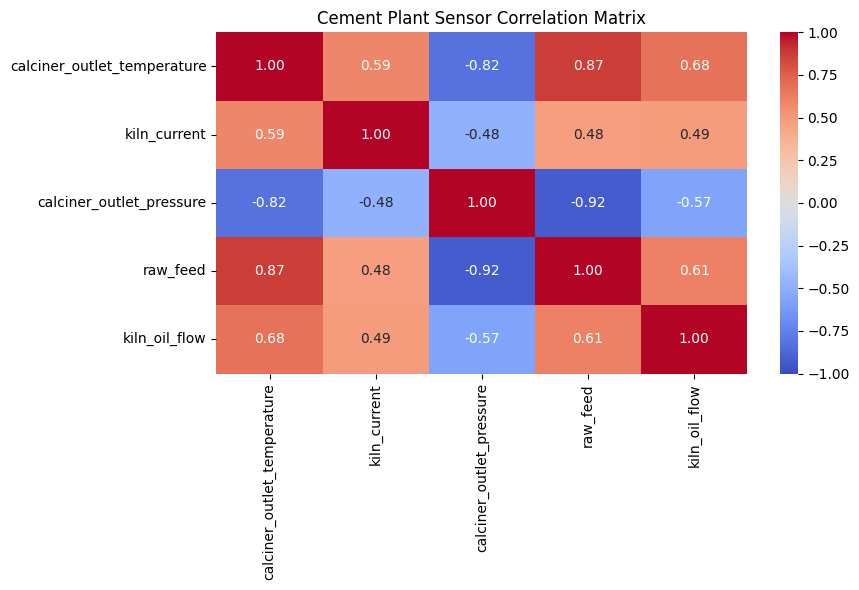

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sensor_names = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "raw_feed",
    "kiln_oil_flow"
]

# Prepare one-minute sensor readings
minute_data = {}

for name in sensor_names:
    df = sensor_data[name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")

    df = df.dropna(subset=["timestamp", "value"])
    df = df.set_index("timestamp").sort_index()

    minute_data[name] = df["value"].resample("1min").median()

aligned_data = pd.DataFrame(minute_data)

# Correlation requires overlapping, available readings
correlation_data = aligned_data.dropna()

print("Minutes with readings from all five sensors:", len(correlation_data))

if len(correlation_data) < 3:
    print("Not enough overlapping data for a reliable correlation analysis.")
else:
    correlation_matrix = correlation_data.corr()

    display(correlation_matrix.round(2))

    plt.figure(figsize=(9, 6))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        fmt=".2f"
    )
    plt.title("Cement Plant Sensor Correlation Matrix")
    plt.tight_layout()
    plt.show()


In [ ]:

import pandas as pd
from IPython.display import display

sensor_names = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "raw_feed",
    "kiln_oil_flow"
]

# Prepare sensor data
prepared = {}

for name in sensor_names:
    df = sensor_data[name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    prepared[name] = df.dropna(
        subset=["timestamp", "value"]
    ).sort_values("timestamp")

event_rows = []

for _, event in events.iterrows():
    event_time = pd.to_datetime(event["event_time"])
    row = {
        "event_time": event_time,
        "temperature_change": event["temperature_change"]
    }

    for name in sensor_names:
        df = prepared[name]

        before = df[
            (df["timestamp"] >= event_time - pd.Timedelta(minutes=5)) &
            (df["timestamp"] < event_time)
        ]["value"]

        after = df[
            (df["timestamp"] > event_time) &
            (df["timestamp"] <= event_time + pd.Timedelta(minutes=5))
        ]["value"]

        row[f"{name}_before_median"] = (
            before.median() if not before.empty else None
        )
        row[f"{name}_after_median"] = (
            after.median() if not after.empty else None
        )
        row[f"{name}_before_count"] = len(before)
        row[f"{name}_after_count"] = len(after)

        if not before.empty and not after.empty:
            row[f"{name}_median_difference"] = (
                after.median() - before.median()
            )
        else:
            row[f"{name}_median_difference"] = None

    event_rows.append(row)

event_window_analysis = pd.DataFrame(event_rows)

display(
    event_window_analysis[
        [
            "event_time",
            "temperature_change",
            "kiln_current_median_difference",
            "calciner_outlet_pressure_median_difference",
            "raw_feed_median_difference",
            "kiln_oil_flow_median_difference"
        ]
    ].round(2)
)


,event_time,temperature_change,kiln_current_median_difference,calciner_outlet_pressure_median_difference,raw_feed_median_difference,kiln_oil_flow_median_difference
0,2023-12-09 10:25:43,20.0,2.78,-76.97,7.5,-10.0
1,2023-12-09 10:25:49,20.0,14.16,-76.97,7.5,-10.0
2,2023-12-09 10:47:02,40.0,22.39,0.00,NaN,0.5
3,2023-12-09 10:49:06,40.0,21.59,-40.51,NaN,-10.0
4,2023-12-09 10:49:54,20.0,13.00,-34.44,NaN,-11.0
5,2023-12-09 12:57:53,50.0,-38.99,34.42,0.0,0.0
6,2023-12-09 13:01:52,20.0,-67.18,-42.53,NaN,5.0
7,2023-12-09 14:03:27,20.0,41.31,0.00,10.0,-32.5
8,2023-12-09 14:06:53,20.0,30.17,-28.36,0.0,-7.5
9,2023-12-09 14:29:13,20.0,-7.89,-12.15,0.0,0.0


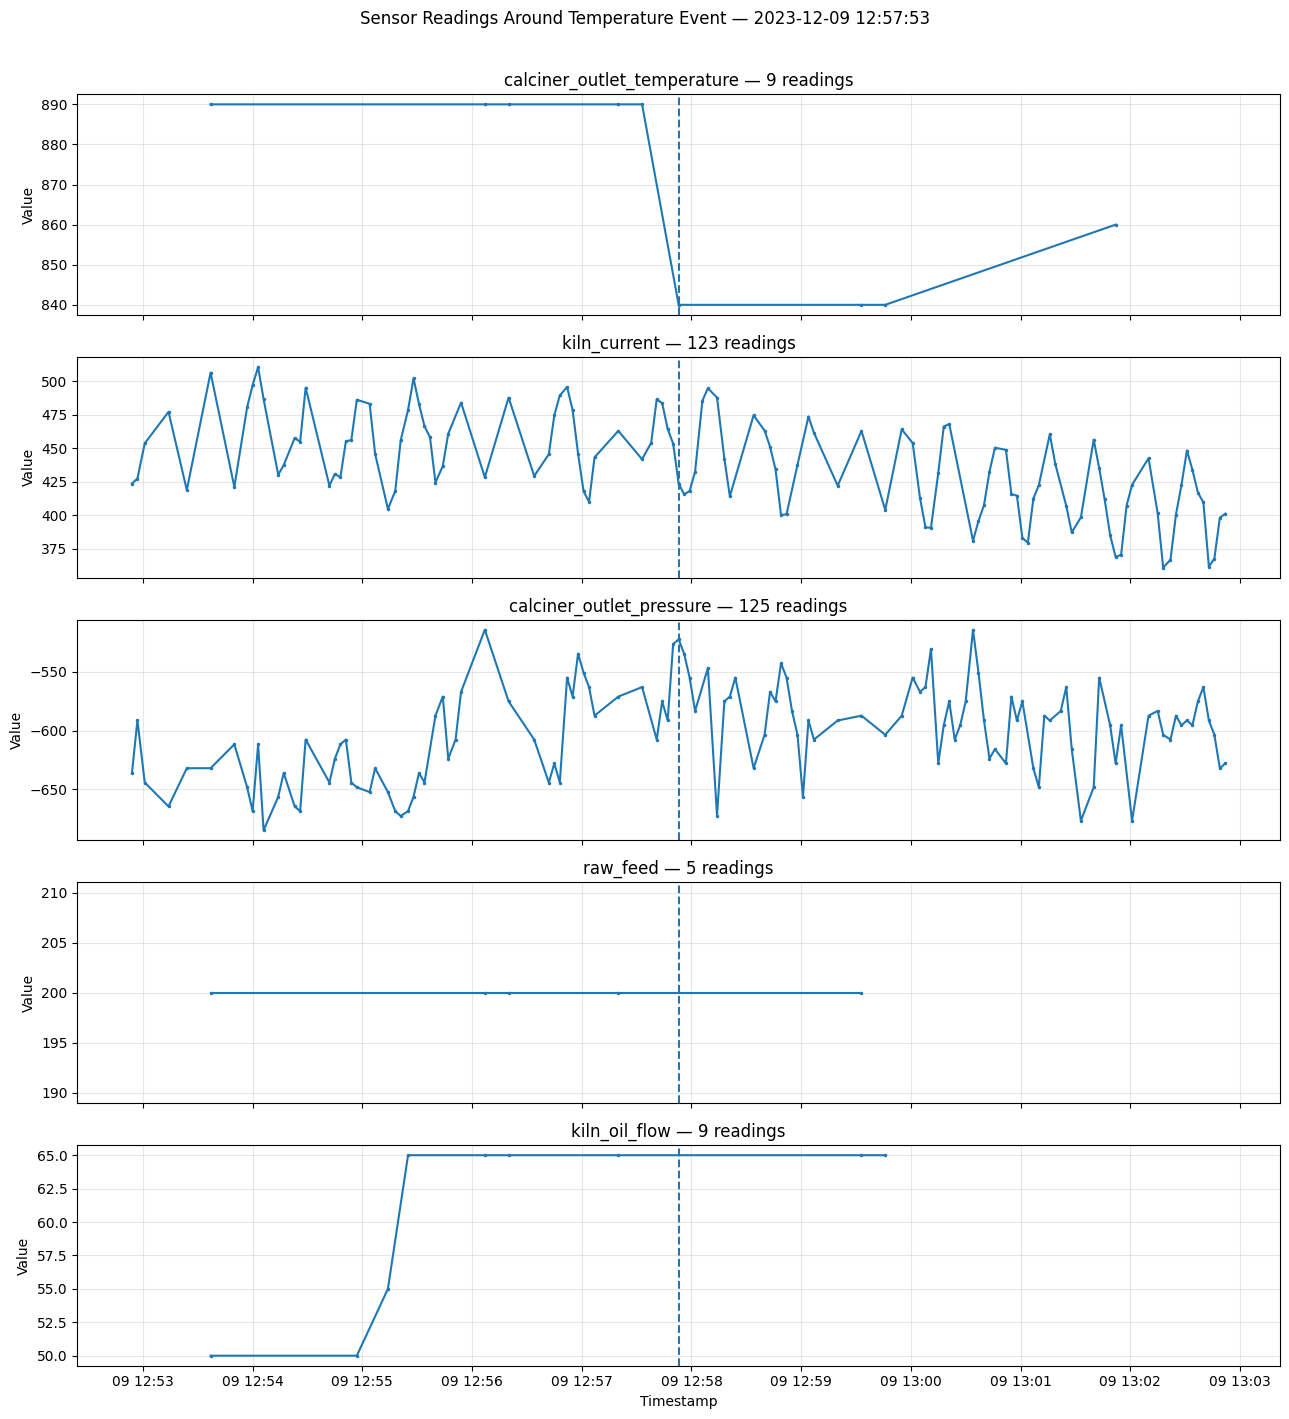

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

event_time = pd.Timestamp("2023-12-09 12:57:53")

sensors_to_plot = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "raw_feed",
    "kiln_oil_flow"
]

fig, axes = plt.subplots(
    len(sensors_to_plot), 1,
    figsize=(13, 14),
    sharex=True
)

for ax, name in zip(axes, sensors_to_plot):
    df = sensor_data[name].copy()
    df["timestamp"] = pd.to_datetime(
        df["timestamp"], errors="coerce"
    )
    df["value"] = pd.to_numeric(
        df["value"], errors="coerce"
    )

    start = event_time - pd.Timedelta(minutes=5)
    end = event_time + pd.Timedelta(minutes=5)

    window = df[
        df["timestamp"].between(start, end)
    ].dropna(subset=["timestamp", "value"])

    ax.plot(window["timestamp"], window["value"], marker=".", markersize=3)
    ax.axvline(event_time, linestyle="--")
    ax.set_title(f"{name} — {len(window)} readings")
    ax.set_ylabel("Value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Timestamp")
fig.suptitle(
    "Sensor Readings Around Temperature Event — 2023-12-09 12:57:53",
    y=1.01
)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
from IPython.display import display

event_time = pd.Timestamp("2023-12-09 12:57:53")

temp = sensor_data["calciner_outlet_temperature"].copy()
temp["timestamp"] = pd.to_datetime(temp["timestamp"], errors="coerce")
temp["value"] = pd.to_numeric(temp["value"], errors="coerce")

temp = temp.dropna(subset=["timestamp", "value"]).sort_values("timestamp")

start = event_time - pd.Timedelta(minutes=5)
end = event_time + pd.Timedelta(minutes=5)

window = temp[temp["timestamp"].between(start, end)].copy()

window["minutes_from_event"] = (
    (window["timestamp"] - event_time).dt.total_seconds() / 60
)

window["temperature_change_from_previous"] = window["value"].diff()

window["gap_seconds"] = (
    window["timestamp"].diff().dt.total_seconds()
)

display(
    window[
        [
            "timestamp",
            "minutes_from_event",
            "value",
            "temperature_change_from_previous",
            "gap_seconds"
        ]
    ].round(2).reset_index(drop=True)
)


,timestamp,minutes_from_event,value,temperature_change_from_previous,gap_seconds
0,2023-12-09 12:53:37,-4.27,890.0,NaN,NaN
1,2023-12-09 12:56:07,-1.77,890.0,0.0,150.0
2,2023-12-09 12:56:20,-1.55,890.0,0.0,13.0
3,2023-12-09 12:57:20,-0.55,890.0,0.0,60.0
4,2023-12-09 12:57:33,-0.33,890.0,0.0,13.0
5,2023-12-09 12:57:53,0.00,840.0,-50.0,20.0
6,2023-12-09 12:59:33,1.67,840.0,0.0,100.0
7,2023-12-09 12:59:46,1.88,840.0,0.0,13.0
8,2023-12-09 13:01:52,3.98,860.0,20.0,126.0


In [ ]:

import pandas as pd
from IPython.display import display

event_time = pd.Timestamp("2023-12-09 12:57:53")

temp = sensor_data["calciner_outlet_temperature"].copy()
temp["timestamp"] = pd.to_datetime(temp["timestamp"], errors="coerce")

start = event_time - pd.Timedelta(minutes=5)
end = event_time + pd.Timedelta(minutes=5)

window = temp[
    temp["timestamp"].between(start, end)
].sort_values("timestamp").copy()

window["gap_seconds"] = (
    window["timestamp"].diff().dt.total_seconds()
)

columns = [
    col for col in [
        "timestamp",
        "source_index",
        "record_number",
        "value",
        "quality",
        "gap_seconds"
    ]
    if col in window.columns
]

display(window[columns].reset_index(drop=True))

print("\nQuality values in this window:")
if "quality" in window.columns:
    display(window["quality"].value_counts(dropna=False).to_frame("count"))


,timestamp,source_index,record_number,value,quality,gap_seconds
0,2023-12-09 12:53:37,58,59,890.0,GOOD,NaN
1,2023-12-09 12:56:07,59,60,890.0,GOOD,150.0
2,2023-12-09 12:56:20,60,61,890.0,GOOD,13.0
3,2023-12-09 12:57:20,61,62,890.0,GOOD,60.0
4,2023-12-09 12:57:33,62,63,890.0,GOOD,13.0
5,2023-12-09 12:57:53,63,64,840.0,GOOD,20.0
6,2023-12-09 12:59:33,64,65,840.0,GOOD,100.0
7,2023-12-09 12:59:46,65,66,840.0,GOOD,13.0
8,2023-12-09 13:01:52,66,67,860.0,GOOD,126.0



Quality values in this window:


,count
quality,
GOOD,9


In [ ]:

import pandas as pd
from IPython.display import display

event_time = pd.Timestamp("2023-12-09 12:57:53")
start = event_time - pd.Timedelta(seconds=60)
end = event_time + pd.Timedelta(seconds=60)

sensor_names = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure",
    "raw_feed",
    "kiln_oil_flow"
]

rows = []

for name in sensor_names:
    df = sensor_data[name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")

    window = df[
        df["timestamp"].between(start, end)
    ].dropna(subset=["timestamp", "value"]).sort_values("timestamp")

    before = window[window["timestamp"] < event_time]
    after = window[window["timestamp"] >= event_time]

    before_value = (
        before.iloc[-1]["value"] if not before.empty else None
    )
    after_value = (
        after.iloc[0]["value"] if not after.empty else None
    )

    before_time = (
        before.iloc[-1]["timestamp"] if not before.empty else None
    )
    after_time = (
        after.iloc[0]["timestamp"] if not after.empty else None
    )

    rows.append({
        "sensor": name,
        "last_reading_before": before_value,
        "time_before": before_time,
        "first_reading_at_or_after": after_value,
        "time_after": after_time,
        "change_between_readings": (
            after_value - before_value
            if before_value is not None and after_value is not None
            else None
        ),
        "readings_in_window": len(window)
    })

display(pd.DataFrame(rows).round(2))


,sensor,last_reading_before,time_before,first_reading_at_or_after,time_after,change_between_readings,readings_in_window
0,calciner_outlet_temperature,890.00,2023-12-09 12:57:33,840.00,2023-12-09 12:57:53,-50.00,3
1,kiln_current,453.45,2023-12-09 12:57:50,423.74,2023-12-09 12:57:53,-29.71,27
2,calciner_outlet_pressure,-526.62,2023-12-09 12:57:50,-522.57,2023-12-09 12:57:53,4.05,26
3,raw_feed,200.00,2023-12-09 12:57:20,NaN,NaT,NaN,1
4,kiln_oil_flow,65.00,2023-12-09 12:57:20,NaN,NaT,NaN,1


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

event_time = pd.Timestamp("2023-12-09 12:57:53")

sensors_to_check = [
    "calciner_outlet_temperature",
    "kiln_current",
    "calciner_outlet_pressure"
]

results = []

for name in sensors_to_check:
    df = sensor_data[name].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df.dropna(subset=["timestamp", "value"]).sort_values("timestamp")

    # Compare consecutive readings only when the gap is no more than 60 seconds
    df["gap_seconds"] = df["timestamp"].diff().dt.total_seconds()
    df["change"] = df["value"].diff()

    normal_changes = df.loc[
        (df["gap_seconds"] > 0) & (df["gap_seconds"] <= 60),
        "change"
    ].dropna()

    # Find the readings closest to the event
    before = df[df["timestamp"] < event_time].tail(1)
    after = df[df["timestamp"] >= event_time].head(1)

    if before.empty or after.empty:
        continue

    before_time = before.iloc[0]["timestamp"]
    after_time = after.iloc[0]["timestamp"]
    before_value = before.iloc[0]["value"]
    after_value = after.iloc[0]["value"]
    gap = (after_time - before_time).total_seconds()
    observed_change = after_value - before_value

    if gap <= 60 and len(normal_changes) > 0:
        percentile = (
            normal_changes.abs() <= abs(observed_change)
        ).mean() * 100
    else:
        percentile = np.nan

    results.append({
        "sensor": name,
        "seconds_between_readings": gap,
        "observed_change": observed_change,
        "absolute_change_percentile": percentile,
        "comparison_count": len(normal_changes)
    })

display(pd.DataFrame(results).round(2))


,sensor,seconds_between_readings,observed_change,absolute_change_percentile,comparison_count
0,calciner_outlet_temperature,20.0,-50.00,100.00,5755
1,kiln_current,3.0,-29.71,56.75,114749
2,calciner_outlet_pressure,3.0,4.05,3.71,112113


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

temp = sensor_data["calciner_outlet_temperature"].copy()

temp["timestamp"] = pd.to_datetime(temp["timestamp"], errors="coerce")
temp["value"] = pd.to_numeric(temp["value"], errors="coerce")

temp = temp.dropna(subset=["timestamp", "value"]).sort_values("timestamp")

temp["gap_seconds"] = temp["timestamp"].diff().dt.total_seconds()
temp["temperature_change"] = temp["value"].diff()

# Use only consecutive readings separated by at most 60 seconds
valid_changes = temp.loc[
    (temp["gap_seconds"] > 0) &
    (temp["gap_seconds"] <= 60),
    "temperature_change"
].dropna()

# Data-derived threshold: 99th percentile of absolute changes
threshold = valid_changes.abs().quantile(0.99)

temp["absolute_change"] = temp["temperature_change"].abs()

temp["review_flag"] = (
    (temp["gap_seconds"] > 0) &
    (temp["gap_seconds"] <= 60) &
    (temp["absolute_change"] >= threshold)
)

review_events = temp[temp["review_flag"]].copy()

print(f"99th percentile threshold: {threshold:.2f}")
print(f"Readings flagged for review: {len(review_events)}")

display(
    review_events[
        [
            "timestamp",
            "value",
            "temperature_change",
            "gap_seconds",
            "absolute_change"
        ]
    ].sort_values(
        "absolute_change", ascending=False
    ).reset_index(drop=True)
)


99th percentile threshold: 0.00
Readings flagged for review: 5755


,timestamp,value,temperature_change,gap_seconds,absolute_change
0,2023-12-09 12:57:53,840.0,-50.0,20.0,50.0
1,2023-12-09 10:49:54,820.0,20.0,48.0,20.0
2,2023-12-09 10:25:49,800.0,-20.0,6.0,20.0
3,2023-12-10 23:34:43,880.0,-18.0,44.0,18.0
4,2023-12-09 18:18:36,840.0,15.0,13.0,15.0
...,...,...,...,...,...
5750,2023-12-12 20:12:14,892.0,0.0,13.0,0.0
5751,2023-12-12 20:12:01,892.0,0.0,13.0,0.0
5752,2023-12-12 20:11:48,892.0,0.0,13.0,0.0
5753,2023-12-12 20:11:35,892.0,0.0,13.0,0.0


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

temp = sensor_data["calciner_outlet_temperature"].copy()

temp["timestamp"] = pd.to_datetime(temp["timestamp"], errors="coerce")
temp["value"] = pd.to_numeric(temp["value"], errors="coerce")
temp = temp.dropna(subset=["timestamp", "value"]).sort_values("timestamp")

temp["gap_seconds"] = temp["timestamp"].diff().dt.total_seconds()
temp["temperature_change"] = temp["value"].diff()
temp["absolute_change"] = temp["temperature_change"].abs()

# Keep only valid consecutive readings, no more than 60 seconds apart
valid_mask = (
    (temp["gap_seconds"] > 0) &
    (temp["gap_seconds"] <= 60)
)

# Exclude zero changes when calculating the threshold
nonzero_changes = temp.loc[
    valid_mask & (temp["absolute_change"] > 0),
    "absolute_change"
]

if nonzero_changes.empty:
    print("No non-zero temperature changes found.")
else:
    threshold = nonzero_changes.quantile(0.99)

    # Use strict greater-than to avoid flagging zero changes
    review_events = temp[
        valid_mask &
        (temp["absolute_change"] > 0) &
        (temp["absolute_change"] >= threshold)
    ].copy()

    print(f"99th percentile of non-zero changes: {threshold:.2f}")
    print(f"Non-zero changes used: {len(nonzero_changes)}")
    print(f"Events flagged for review: {len(review_events)}")

    display(
        review_events[
            [
                "timestamp",
                "value",
                "temperature_change",
                "gap_seconds",
                "absolute_change"
            ]
        ].sort_values(
            "absolute_change", ascending=False
        ).reset_index(drop=True)
    )


99th percentile of non-zero changes: 34.40
Non-zero changes used: 53
Events flagged for review: 1


,timestamp,value,temperature_change,gap_seconds,absolute_change
0,2023-12-09 12:57:53,840.0,-50.0,20.0,50.0


In [ ]:

import pandas as pd
from IPython.display import display, HTML
from google.colab import files

# Start with the existing event summary
report = improved_summary.copy()

# Add event review priority if missing
if "absolute_temperature_change" not in report.columns:
    report["absolute_temperature_change"] = pd.to_numeric(
        report["temperature_change"], errors="coerce"
    ).abs()

if "review_priority" not in report.columns:
    def assign_priority(change):
        if pd.isna(change):
            return "Insufficient information"
        if change >= 40:
            return "High review priority"
        if change >= 20:
            return "Review required"
        return "Routine review"

    report["review_priority"] = report[
        "absolute_temperature_change"
    ].apply(assign_priority)

# Add event-specific findings from the close-window comparison
event_findings = {
    "2023-12-09 12:57:53": (
        "Temperature fell by 50; kiln current fell by 29.71 "
        "over closely timed readings. Pressure changed by +4.05. "
        "Raw feed and oil flow had no later reading in the short window."
    )
}

report["engineering_observation"] = report["event_time"].astype(str).map(
    event_findings
).fillna(
    "Review sensor trends and data availability before determining cause."
)

report["interpretation_limit"] = (
    "Review priority is based on temperature-change magnitude; "
    "fault cause and severity are not confirmed."
)

report = report.sort_values(
    "absolute_temperature_change", ascending=False
).reset_index(drop=True)

# Display a concise report
display(HTML("""
<h2>Cement Plant — Temperature Event Review Report</h2>
<p><b>Purpose:</b> Support engineering review of unusual temperature changes.</p>
<p><b>Dataset period:</b> December 2023, based on available records.</p>
"""))

display(
    report[
        [
            "event_time",
            "temperature_before",
            "temperature_after",
            "temperature_change",
            "review_priority",
            "engineering_observation",
            "interpretation_limit"
        ]
    ]
)

# Export the full report
filename = "ASEC_cement_temperature_event_review.csv"
report.to_csv(filename, index=False, encoding="utf-8-sig")

print(f"\nReport prepared: {filename}")
files.download(filename)


,event_time,temperature_before,temperature_after,temperature_change,review_priority,engineering_observation,interpretation_limit
0,2023-12-09 12:57:53,890.0,840.0,50.0,High review priority,Temperature fell by 50; kiln current fell by 2...,Review priority is based on temperature-change...
1,2023-12-09 10:49:06,760.0,800.0,40.0,High review priority,Review sensor trends and data availability bef...,Review priority is based on temperature-change...
2,2023-12-09 10:47:02,800.0,760.0,40.0,High review priority,Review sensor trends and data availability bef...,Review priority is based on temperature-change...
3,2023-12-09 15:27:56,800.0,835.0,35.0,Review required,Review sensor trends and data availability bef...,Review priority is based on temperature-change...
4,2023-12-09 10:25:43,840.0,820.0,20.0,Review required,Review sensor trends and data availability bef...,Review priority is based on temperature-change...
5,2023-12-09 10:25:49,820.0,800.0,20.0,Review required,Review sensor trends and data availability bef...,Review priority is based on temperature-change...
6,2023-12-09 13:01:52,840.0,860.0,20.0,Review required,Review sensor trends and data availability bef...,Review priority is based on temperature-change...
7,2023-12-09 10:49:54,800.0,820.0,20.0,Review required,Review sensor trends and data availability bef...,Review priority is based on temperature-change...
8,2023-12-09 14:03:27,880.0,860.0,20.0,Review required,Review sensor trends and data availability bef...,Review priority is based on temperature-change...
9,2023-12-09 14:06:53,860.0,840.0,20.0,Review required,Review sensor trends and data availability bef...,Review priority is based on temperature-change...



Report prepared: ASEC_cement_temperature_event_review.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Total recorded events: 12
High review priority: 3
Review required: 9
Largest recorded temperature change: 50.0
Largest event time: 2023-12-09 12:57:53


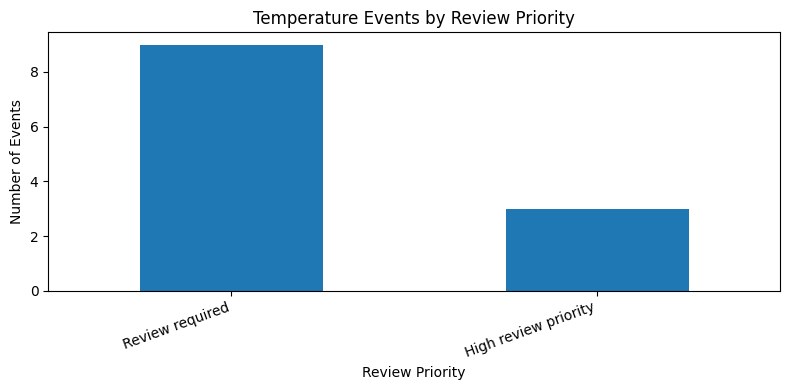

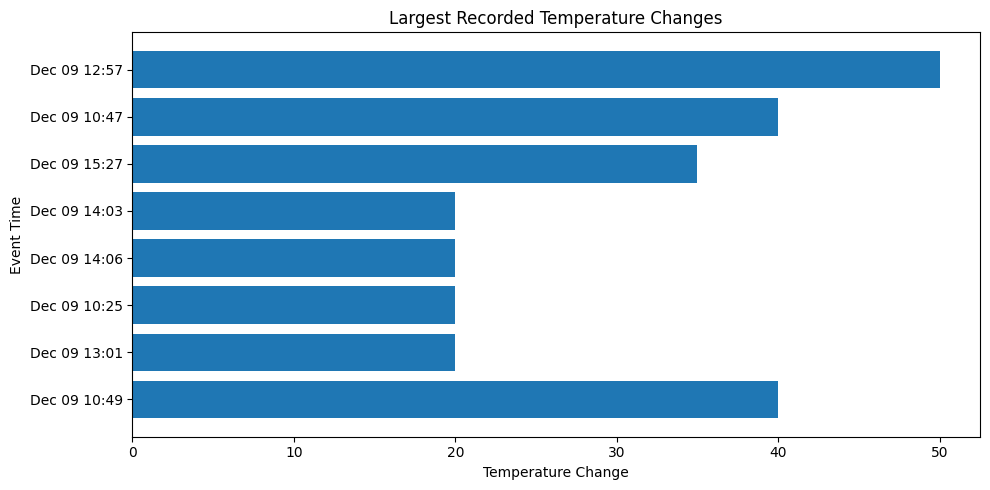

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

report = improved_summary.copy()

report["absolute_temperature_change"] = pd.to_numeric(
    report["temperature_change"], errors="coerce"
).abs()

report["event_time"] = pd.to_datetime(
    report["event_time"], errors="coerce"
)

# Summary metrics
total_events = len(report)
high_priority = (report["review_priority"] == "High review priority").sum()
review_required = (report["review_priority"] == "Review required").sum()

largest_event = report.loc[
    report["absolute_temperature_change"].idxmax()
]

display(HTML("""
<h2>ASEC Automation — Cement Plant Executive Summary</h2>
<p>Exploratory analysis of recorded calciner outlet temperature events.</p>
"""))

print(f"Total recorded events: {total_events}")
print(f"High review priority: {high_priority}")
print(f"Review required: {review_required}")
print(f"Largest recorded temperature change: {largest_event['temperature_change']:.1f}")
print(f"Largest event time: {largest_event['event_time']}")

# Chart 1: Event priority distribution
priority_counts = report["review_priority"].value_counts()

plt.figure(figsize=(8, 4))
priority_counts.plot(kind="bar")
plt.title("Temperature Events by Review Priority")
plt.xlabel("Review Priority")
plt.ylabel("Number of Events")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Chart 2: Largest temperature changes
top_events = report.nlargest(
    10, "absolute_temperature_change"
).sort_values("absolute_temperature_change")

plt.figure(figsize=(10, 5))
plt.barh(
    top_events["event_time"].dt.strftime("%b %d %H:%M"),
    top_events["temperature_change"]
)
plt.title("Largest Recorded Temperature Changes")
plt.xlabel("Temperature Change")
plt.ylabel("Event Time")
plt.tight_layout()
plt.show()

# Important limitations
display(HTML("""
<h3>Interpretation and Limitations</h3>
<ul>
<li>Review priority is based on temperature-change magnitude.</li>
<li>Recorded events are not confirmed equipment faults.</li>
<li>Sensor timing, data gaps, operating conditions, and engineering limits
must be reviewed before operational decisions.</li>
<li>The available dataset covers a limited period in December 2023.</li>
</ul>
"""))


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, HTML, clear_output
from google.colab import files

# =========================================================
# 1. PREPARE SENSOR DATA
# =========================================================

sensor_names = [
    "calciner_outlet_temperature",
    "kiln_head_pressure",
    "raw_feed",
    "kiln_oil_flow",
    "kiln_motor_speed",
    "cooler_speed",
    "id_fan_1_speed",
    "id_fan_2_speed",
    "kiln_current",
    "calciner_outlet_pressure",
    "cyclone_1_outlet_temperature"
]

available_sensors = [
    name for name in sensor_names
    if "sensor_data" in globals() and name in sensor_data
]

if not available_sensors:
    raise ValueError(
        "Sensor data not found. Run the cells that load sensor_data first."
    )

prepared_sensors = {}

for name in available_sensors:
    df = sensor_data[name].copy()
    df["timestamp"] = pd.to_datetime(
        df["timestamp"], errors="coerce"
    )
    df["value"] = pd.to_numeric(
        df["value"], errors="coerce"
    )
    df = df.dropna(subset=["timestamp", "value"])
    df = df.sort_values("timestamp")
    prepared_sensors[name] = df

all_timestamps = pd.concat(
    [df["timestamp"] for df in prepared_sensors.values()],
    ignore_index=True
)

available_days = sorted(
    all_timestamps.dt.strftime("%Y-%m-%d").dropna().unique().tolist()
)

if not available_days:
    raise ValueError("No valid timestamps were found.")

# =========================================================
# 2. PREPARE EVENT TABLE
# =========================================================

if "improved_summary" in globals():
    dashboard_events = improved_summary.copy()
elif "events" in globals():
    dashboard_events = events.copy()
else:
    dashboard_events = pd.DataFrame()

if not dashboard_events.empty:
    dashboard_events["event_time"] = pd.to_datetime(
        dashboard_events["event_time"], errors="coerce"
    )

    if "temperature_change" not in dashboard_events.columns:
        dashboard_events["temperature_change"] = np.nan

    dashboard_events["temperature_change"] = pd.to_numeric(
        dashboard_events["temperature_change"], errors="coerce"
    )

    dashboard_events["absolute_temperature_change"] = (
        dashboard_events["temperature_change"].abs()
    )

    if "review_priority" not in dashboard_events.columns:
        def assign_priority(change):
            if pd.isna(change):
                return "Insufficient information"
            if abs(change) >= 40:
                return "High review priority"
            if abs(change) >= 20:
                return "Review required"
            return "Routine review"

        dashboard_events["review_priority"] = (
            dashboard_events["temperature_change"].apply(assign_priority)
        )

    dashboard_events = dashboard_events.dropna(
        subset=["event_time"]
    ).sort_values("event_time")

# =========================================================
# 3. BUILD DASHBOARD HEADER AND KPI CARDS
# =========================================================

total_events = len(dashboard_events)

if total_events:
    high_count = (
        dashboard_events["review_priority"] == "High review priority"
    ).sum()

    review_count = (
        dashboard_events["review_priority"] == "Review required"
    ).sum()
else:
    high_count = 0
    review_count = 0

display(HTML("""
<div style="padding:20px;border-radius:12px;background:#102A43;color:white;">
  <h1 style="margin:0;">ASEC Automation</h1>
  <h3 style="margin:6px 0;">Cement Plant Monitoring Dashboard</h3>
  <p style="margin:0;">Historical sensor analytics | Event investigation</p>
</div>
"""))

display(HTML(f"""
<div style="display:flex;flex-wrap:wrap;gap:12px;margin:16px 0;">
  <div style="flex:1;min-width:145px;padding:16px;border:1px solid #ddd;border-radius:10px;">
    <div>Total Recorded Events</div>
    <div style="font-size:30px;font-weight:bold;">{total_events}</div>
  </div>
  <div style="flex:1;min-width:145px;padding:16px;border:1px solid #ddd;border-radius:10px;">
    <div>High Review Priority</div>
    <div style="font-size:30px;font-weight:bold;">{high_count}</div>
  </div>
  <div style="flex:1;min-width:145px;padding:16px;border:1px solid #ddd;border-radius:10px;">
    <div>Review Required</div>
    <div style="font-size:30px;font-weight:bold;">{review_count}</div>
  </div>
  <div style="flex:1;min-width:145px;padding:16px;border:1px solid #ddd;border-radius:10px;">
    <div>Available Sensors</div>
    <div style="font-size:30px;font-weight:bold;">{len(available_sensors)}</div>
  </div>
</div>
"""))

display(HTML("""
<p style="color:#777;font-size:12px;">
Data source: historical records. Priority is for review only; it does not
confirm equipment faults. This dashboard is not connected to live plant systems.
</p>
"""))

# =========================================================
# 4. FILTER CONTROLS
# =========================================================

day_filter = widgets.Dropdown(
    options=available_days,
    value=available_days[0],
    description="Date:",
    layout=widgets.Layout(width="260px")
)

sensor_filter = widgets.Dropdown(
    options=available_sensors,
    value=(
        "calciner_outlet_temperature"
        if "calciner_outlet_temperature" in available_sensors
        else available_sensors[0]
    ),
    description="Sensor:",
    layout=widgets.Layout(width="390px")
)

priority_options = [
    "All priorities",
    "High review priority",
    "Review required",
    "Routine review",
    "Insufficient information"
]

priority_filter = widgets.Dropdown(
    options=priority_options,
    value="All priorities",
    description="Priority:",
    layout=widgets.Layout(width="300px")
)

refresh_button = widgets.Button(
    description="Update Dashboard",
    button_style="primary",
    icon="refresh"
)

download_button = widgets.Button(
    description="Download Filtered Events",
    button_style="success",
    icon="download"
)

dashboard_output = widgets.Output()
download_status = widgets.Output()
filtered_events_store = {"df": dashboard_events.copy()}

display(HTML("<h3>Dashboard Filters</h3>"))
display(widgets.VBox([
    widgets.HBox([day_filter, sensor_filter]),
    widgets.HBox([priority_filter, refresh_button, download_button])
]))
display(download_status)
display(dashboard_output)

# =========================================================
# 5. DASHBOARD UPDATE FUNCTION
# =========================================================

def update_dashboard(_=None):
    selected_day = day_filter.value
    selected_sensor = sensor_filter.value
    selected_priority = priority_filter.value

    with dashboard_output:
        clear_output(wait=True)

        # Historical trend
        sensor_df = prepared_sensors[selected_sensor].copy()

        daily_df = sensor_df[
            sensor_df["timestamp"].dt.strftime("%Y-%m-%d")
            == selected_day
        ]

        display(HTML(
            f"<h3>Sensor Trend — {selected_sensor}</h3>"
            f"<p>Date: {selected_day}</p>"
        ))

        if daily_df.empty:
            print("No readings available for this sensor on the selected date.")
        else:
            fig, ax = plt.subplots(figsize=(12, 4))
            ax.plot(
                daily_df["timestamp"],
                daily_df["value"],
                linewidth=1
            )
            ax.set_title(selected_sensor.replace("_", " ").title())
            ax.set_xlabel("Time")
            ax.set_ylabel("Recorded value")
            ax.grid(True, alpha=0.3)
            fig.autofmt_xdate()
            plt.tight_layout()
            plt.show()
            plt.close(fig)

            print(f"Readings on selected date: {len(daily_df):,}")
            print(f"Minimum: {daily_df['value'].min():.2f}")
            print(f"Maximum: {daily_df['value'].max():.2f}")
            print(f"Median: {daily_df['value'].median():.2f}")

        # Event review table
        display(HTML("<h3>Event Review</h3>"))

        if dashboard_events.empty:
            print("No event table is available. Run the event analysis cells first.")
            filtered_events_store["df"] = dashboard_events.copy()
        else:
            filtered = dashboard_events[
                dashboard_events["event_time"].dt.strftime("%Y-%m-%d")
                == selected_day
            ].copy()

            if selected_priority != "All priorities":
                filtered = filtered[
                    filtered["review_priority"] == selected_priority
                ]

            filtered = filtered.sort_values(
                "absolute_temperature_change",
                ascending=False
            )

            filtered_events_store["df"] = filtered.copy()

            print(f"Events matching filters: {len(filtered)}")

            display_columns = [
                col for col in [
                    "event_time",
                    "temperature_before",
                    "temperature_after",
                    "temperature_change",
                    "review_priority",
                    "data_quality_flag"
                ]
                if col in filtered.columns
            ]

            if filtered.empty:
                print("No events match the selected date and priority.")
            else:
                display(
                    filtered[display_columns]
                    .reset_index(drop=True)
                    .round(2)
                )

            # Daily temperature events chart
            if not filtered.empty and "temperature_change" in filtered:
                fig, ax = plt.subplots(figsize=(12, 4))
                labels = filtered["event_time"].dt.strftime("%H:%M:%S")
                ax.bar(labels, filtered["temperature_change"])
                ax.axhline(0, linewidth=1)
                ax.set_title("Temperature Changes for Selected Events")
                ax.set_xlabel("Event time")
                ax.set_ylabel("Temperature change")
                ax.tick_params(axis="x", rotation=45)
                ax.grid(axis="y", alpha=0.3)
                plt.tight_layout()
                plt.show()
                plt.close(fig)

refresh_button.on_click(update_dashboard)

def download_filtered_events(_):
    with download_status:
        clear_output(wait=True)

        df = filtered_events_store["df"].copy()

        if df.empty:
            print("No filtered events to download. Update the dashboard first.")
            return

        filename = "ASEC_filtered_event_review.csv"
        df.to_csv(filename, index=False, encoding="utf-8-sig")
        print(f"Preparing download: {filename}")
        files.download(filename)

download_button.on_click(download_filtered_events)

# First dashboard render
update_dashboard()


Output()

Output()

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Build event options from the existing event table
if dashboard_events.empty:
    raise ValueError("No events found. Run the event analysis cells first.")

event_options = []
for idx, row in dashboard_events.reset_index(drop=True).iterrows():
    ts = row["event_time"]
    change = row["temperature_change"]
    label = f"{ts} | Temperature change: {change:+.1f}"
    event_options.append((label, idx))

event_picker = widgets.Dropdown(
    options=event_options,
    description="Event:",
    layout=widgets.Layout(width="600px")
)

window_picker = widgets.Dropdown(
    options=[
        ("2 minutes before/after", 2),
        ("5 minutes before/after", 5),
        ("10 minutes before/after", 10)
    ],
    value=5,
    description="Window:"
)

investigate_button = widgets.Button(
    description="Investigate Event",
    button_style="primary",
    icon="search"
)

investigation_output = widgets.Output()

display(HTML("""
<div style="padding:16px;border-radius:10px;background:#102A43;color:white;">
  <h2 style="margin:0;color:white;">Event Investigation</h2>
  <p style="margin:6px 0 0 0;color:white;">
    Compare available sensor readings around a recorded temperature event.
  </p>
</div>
"""))

display(widgets.VBox([
    event_picker,
    widgets.HBox([window_picker, investigate_button]),
    investigation_output
]))

def investigate_selected_event(_=None):
    selected_row = dashboard_events.reset_index(drop=True).iloc[
        event_picker.value
    ]
    event_time = pd.Timestamp(selected_row["event_time"])
    minutes = window_picker.value

    start = event_time - pd.Timedelta(minutes=minutes)
    end = event_time + pd.Timedelta(minutes=minutes)

    sensors_to_plot = [
        "calciner_outlet_temperature",
        "kiln_current",
        "calciner_outlet_pressure",
        "raw_feed",
        "kiln_oil_flow"
    ]

    with investigation_output:
        clear_output(wait=True)

        display(HTML(
            f"<h3>Event time: {event_time}</h3>"
            f"<p>Temperature change: "
            f"{selected_row['temperature_change']:+.1f}</p>"
        ))

        available_for_plot = [
            name for name in sensors_to_plot
            if name in prepared_sensors
        ]

        fig, axes = plt.subplots(
            len(available_for_plot), 1,
            figsize=(12, 2.6 * len(available_for_plot)),
            sharex=True
        )

        if len(available_for_plot) == 1:
            axes = [axes]

        summary_rows = []

        for ax, name in zip(axes, available_for_plot):
            df = prepared_sensors[name]
            window = df[
                df["timestamp"].between(start, end)
            ].copy()

            ax.plot(
                window["timestamp"],
                window["value"],
                marker=".",
                markersize=3
            )
            ax.axvline(event_time, linestyle="--")
            ax.set_title(f"{name} — {len(window)} readings")
            ax.set_ylabel("Value")
            ax.grid(True, alpha=0.3)

            summary_rows.append({
                "sensor": name,
                "readings": len(window),
                "minimum": window["value"].min() if len(window) else None,
                "maximum": window["value"].max() if len(window) else None
            })

        axes[-1].set_xlabel("Timestamp")
        fig.tight_layout()
        plt.show()
        plt.close(fig)

        display(pd.DataFrame(summary_rows).round(2))

        print(
            "Interpretation note: these plots support investigation; "
            "they do not establish the cause of an event."
        )

investigate_button.on_click(investigate_selected_event)

# Display the first event when the cell runs
investigate_selected_event()


In [ ]:

from IPython.display import display, HTML, clear_output
import pandas as pd
import ipywidgets as widgets

summary_button = widgets.Button(
    description="Generate Event Summary",
    button_style="primary",
    icon="file-text"
)

summary_output = widgets.Output()

def generate_english_summary(_=None):
    event_idx = event_picker.value
    event = dashboard_events.reset_index(drop=True).iloc[event_idx]

    event_time = pd.Timestamp(event["event_time"])
    window_minutes = window_picker.value

    start_time = event_time - pd.Timedelta(minutes=window_minutes)
    end_time = event_time + pd.Timedelta(minutes=window_minutes)

    sensor_list = [
        "calciner_outlet_temperature",
        "kiln_current",
        "calciner_outlet_pressure",
        "raw_feed",
        "kiln_oil_flow"
    ]

    summary_rows = []

    for name in sensor_list:
        if name not in prepared_sensors:
            continue

        df = prepared_sensors[name]
        window = df[df["timestamp"].between(start_time, end_time)]

        summary_rows.append({
            "Sensor": name.replace("_", " ").title(),
            "Readings Available": len(window),
            "Minimum": window["value"].min() if not window.empty else None,
            "Maximum": window["value"].max() if not window.empty else None,
            "Median": window["value"].median() if not window.empty else None,
            "Data Status": (
                "Readings available" if not window.empty
                else "No readings in selected window"
            )
        })

    summary_table = pd.DataFrame(summary_rows)

    temp_before = event.get("temperature_before", None)
    temp_after = event.get("temperature_after", None)
    temp_change = event.get("temperature_change", None)
    priority = event.get("review_priority", "Not assigned")

    with summary_output:
        clear_output(wait=True)

        display(HTML(f"""
        <div style="font-family:Arial;border:1px solid #ddd;
                    border-radius:12px;padding:20px;">
          <h2 style="margin-top:0;color:#17324D;">
            Engineering Event Review Summary
          </h2>
          <p><b>Event timestamp:</b> {event_time}</p>
          <p><b>Review priority:</b> {priority}</p>
          <p><b>Analysis window:</b> {window_minutes} minutes before and after the event</p>
          <hr>
          <h3>Recorded Temperature Event</h3>
          <p><b>Temperature before:</b> {temp_before if pd.notna(temp_before) else "Not available"}</p>
          <p><b>Temperature after:</b> {temp_after if pd.notna(temp_after) else "Not available"}</p>
          <p><b>Recorded temperature change:</b> {temp_change if pd.notna(temp_change) else "Not available"}</p>
          <h3>Sensor Data Availability</h3>
        </div>
        """))

        display(summary_table.round(2))

        available_count = (
            summary_table["Readings Available"].gt(0).sum()
        )
        total_count = len(summary_table)
        missing_sensors = summary_table.loc[
            summary_table["Readings Available"].eq(0), "Sensor"
        ].tolist()

        print("ENGINEERING OBSERVATIONS")
        print(
            f"{available_count} of {total_count} reviewed sensors "
            "have readings in the selected time window."
        )

        if missing_sensors:
            print(
                "Sensors without readings in this window: "
                + ", ".join(missing_sensors)
                + "."
            )
        else:
            print("All reviewed sensors have at least one reading in this window.")

        print("\nINTERPRETATION LIMITATIONS")
        print(
            "This summary describes recorded values and data availability. "
            "It does not establish the cause of the temperature change or "
            "confirm an equipment fault."
        )
        print(
            "Sensor readings may have different sampling intervals. "
            "Readings available in the window may not be exactly synchronized."
        )

summary_button.on_click(generate_english_summary)

display(summary_button)
display(summary_output)


Button(button_style='primary', description='Generate Event Summary', icon='file-text', style=ButtonStyle())

Output()

In [ ]:

import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import files

download_event_report_button = widgets.Button(
    description="Download Event Report",
    button_style="success",
    icon="download"
)

event_report_status = widgets.Output()

def download_selected_event_report(_):
    event_idx = event_picker.value
    event = dashboard_events.reset_index(drop=True).iloc[event_idx]

    event_time = pd.Timestamp(event["event_time"])
    window_minutes = window_picker.value

    start_time = event_time - pd.Timedelta(minutes=window_minutes)
    end_time = event_time + pd.Timedelta(minutes=window_minutes)

    sensor_list = [
        "calciner_outlet_temperature",
        "kiln_current",
        "calciner_outlet_pressure",
        "raw_feed",
        "kiln_oil_flow"
    ]

    sensor_rows = []

    for name in sensor_list:
        if name not in prepared_sensors:
            continue

        df = prepared_sensors[name]
        window = df[df["timestamp"].between(start_time, end_time)]

        sensor_rows.append({
            "event_time": event_time,
            "review_priority": event.get(
                "review_priority", "Not assigned"
            ),
            "temperature_change": event.get(
                "temperature_change", None
            ),
            "sensor": name,
            "analysis_window_minutes_each_side": window_minutes,
            "readings_available": len(window),
            "minimum": window["value"].min() if not window.empty else None,
            "maximum": window["value"].max() if not window.empty else None,
            "median": window["value"].median() if not window.empty else None,
            "data_status": (
                "Readings available"
                if not window.empty
                else "No readings in selected window"
            ),
            "engineering_note": (
                "Recorded data only; event cause and fault status "
                "have not been confirmed."
            )
        })

    report_df = pd.DataFrame(sensor_rows)

    safe_time = event_time.strftime("%Y%m%d_%H%M%S")
    filename = f"ASEC_Event_Report_{safe_time}.csv"

    report_df.to_csv(
        filename,
        index=False,
        encoding="utf-8-sig"
    )

    with event_report_status:
        clear_output(wait=True)
        print(f"Preparing report: {filename}")
        print(f"Event: {event_time}")
        print(f"Sensors included: {len(report_df)}")
        files.download(filename)

download_event_report_button.on_click(
    download_selected_event_report
)

display(download_event_report_button)
display(event_report_status)


Button(button_style='success', description='Download Event Report', icon='download', style=ButtonStyle())

Output()

In [ ]:
# ============================================================
# ASEC AUTOMATION | UNIFIED CEMENT PLANT DASHBOARD
# Historical data prototype for Google Colab
# Requires: sensor_data; optionally events or improved_summary
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from google.colab import files

# ---------- Validate inputs ----------
if "sensor_data" not in globals():
    raise ValueError("sensor_data is missing. Run your data-loading cells first.")

SENSOR_LABELS = {
    "calciner_outlet_temperature": "Calciner Outlet Temperature",
    "kiln_head_pressure": "Kiln Head Pressure",
    "raw_feed": "Raw Feed",
    "kiln_oil_flow": "Kiln Oil Flow",
    "kiln_motor_speed": "Kiln Motor Speed",
    "cooler_speed": "Cooler Speed",
    "id_fan_1_speed": "ID Fan 1 Speed",
    "id_fan_2_speed": "ID Fan 2 Speed",
    "kiln_current": "Kiln Current",
    "calciner_outlet_pressure": "Calciner Outlet Pressure",
    "cyclone_1_outlet_temperature": "Cyclone 1 Outlet Temperature",
}

NAVY = "#102A43"
TEAL = "#0F766E"
BLUE = "#2563EB"
AMBER = "#B45309"
RED = "#B91C1C"
LIGHT = "#F3F6FA"

# ---------- Prepare sensor data ----------
prepared = {}
for name, source in sensor_data.items():
    df = source.copy()
    if not {"timestamp", "value"}.issubset(df.columns):
        continue
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df.dropna(subset=["timestamp", "value"]).sort_values("timestamp").reset_index(drop=True)
    if not df.empty:
        prepared[name] = df

if not prepared:
    raise ValueError("No usable sensor data was found in sensor_data.")

sensor_options = [
    (SENSOR_LABELS.get(name, name.replace("_", " ").title()), name)
    for name in SENSOR_LABELS if name in prepared
]
if not sensor_options:
    sensor_options = [(name.replace("_", " ").title(), name) for name in prepared]

all_times = pd.concat([df["timestamp"] for df in prepared.values()], ignore_index=True)
available_dates = sorted(all_times.dt.strftime("%Y-%m-%d").dropna().unique().tolist())

# ---------- Prepare event table ----------
if "improved_summary" in globals() and isinstance(improved_summary, pd.DataFrame) and not improved_summary.empty:
    event_source = improved_summary.copy()
elif "events" in globals() and isinstance(events, pd.DataFrame) and not events.empty:
    event_source = events.copy()
else:
    event_source = pd.DataFrame()

if not event_source.empty:
    if "event_time" not in event_source.columns:
        for candidate in ["timestamp", "time", "datetime"]:
            if candidate in event_source.columns:
                event_source = event_source.rename(columns={candidate: "event_time"})
                break
    if "temperature_change" not in event_source.columns:
        for candidate in ["change", "temp_change", "delta"]:
            if candidate in event_source.columns:
                event_source = event_source.rename(columns={candidate: "temperature_change"})
                break
    if "event_time" not in event_source.columns:
        event_source = pd.DataFrame()
    else:
        event_source["event_time"] = pd.to_datetime(event_source["event_time"], errors="coerce")
        if "temperature_change" not in event_source.columns:
            event_source["temperature_change"] = np.nan
        event_source["temperature_change"] = pd.to_numeric(event_source["temperature_change"], errors="coerce")
        event_source = event_source.dropna(subset=["event_time"]).copy()
        event_source["absolute_temperature_change"] = event_source["temperature_change"].abs()
        if "review_priority" not in event_source.columns:
            def get_priority(change):
                if pd.isna(change):
                    return "Insufficient information"
                if abs(change) >= 40:
                    return "High review priority"
                if abs(change) >= 20:
                    return "Review required"
                return "Routine review"
            event_source["review_priority"] = event_source["temperature_change"].apply(get_priority)
        for col in ["temperature_before", "temperature_after"]:
            if col not in event_source.columns:
                event_source[col] = np.nan
        event_source = event_source.sort_values("event_time").reset_index(drop=True)

if event_source.empty:
    event_source = pd.DataFrame(columns=[
        "event_time", "temperature_change", "absolute_temperature_change",
        "review_priority", "temperature_before", "temperature_after"
    ])

total_events = len(event_source)
high_events = int((event_source["review_priority"] == "High review priority").sum()) if total_events else 0
review_events_count = int((event_source["review_priority"] == "Review required").sum()) if total_events else 0

# ---------- Header and KPI cards ----------
display(HTML(f"""
<style>
.asec-header {{background:{NAVY};color:white;padding:24px;border-radius:14px;margin-bottom:14px;font-family:Arial,sans-serif}}
.asec-header h1 {{color:white;margin:0;font-size:27px}}
.asec-header p {{color:#DCE7F2;margin:7px 0 0}}
.asec-note {{background:{LIGHT};border-left:4px solid {TEAL};padding:12px 16px;border-radius:7px;color:#334155;margin:10px 0 16px}}
</style>
<div class="asec-header">
<h1>ASEC AUTOMATION</h1>
<h3 style="color:#DCE7F2;margin:7px 0">Cement Plant Monitoring &amp; Event Analytics</h3>
<p>Historical sensor monitoring · Event investigation · Data quality · Reports</p>
</div>
<div class="asec-note"><b>Historical prototype:</b> This dashboard uses recorded data only. It is not connected to live plant systems. Review priorities are exploratory and do not confirm equipment faults.</div>
<div style="display:flex;flex-wrap:wrap;gap:12px;margin:12px 0 20px">
<div style="flex:1;min-width:145px;background:{LIGHT};padding:17px;border-radius:11px;border:1px solid #E2E8F0"><div>Recorded Events</div><div style="font-size:29px;font-weight:700;color:{NAVY}">{total_events}</div></div>
<div style="flex:1;min-width:145px;background:{LIGHT};padding:17px;border-radius:11px;border:1px solid #E2E8F0"><div>High Review Priority</div><div style="font-size:29px;font-weight:700;color:{RED}">{high_events}</div></div>
<div style="flex:1;min-width:145px;background:{LIGHT};padding:17px;border-radius:11px;border:1px solid #E2E8F0"><div>Review Required</div><div style="font-size:29px;font-weight:700;color:{AMBER}">{review_events_count}</div></div>
<div style="flex:1;min-width:145px;background:{LIGHT};padding:17px;border-radius:11px;border:1px solid #E2E8F0"><div>Available Sensors</div><div style="font-size:29px;font-weight:700;color:{TEAL}">{len(prepared)}</div></div>
</div>
"""))

# ---------- Controls ----------
date_filter = widgets.Dropdown(
    options=available_dates, value=available_dates[-1],
    description="Date:", style={"description_width": "initial"},
    layout=widgets.Layout(width="270px")
)
default_sensor = "calciner_outlet_temperature" if "calciner_outlet_temperature" in prepared else sensor_options[0][1]
sensor_filter = widgets.Dropdown(
    options=sensor_options, value=default_sensor,
    description="Sensor:", style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)
trend_button = widgets.Button(description="Update Trend", button_style="primary", icon="refresh")
trend_output = widgets.Output()

event_options = [
    (f"{row['event_time']} | Change: {row['temperature_change']:+.1f}", idx)
    for idx, row in event_source.iterrows()
] if total_events else [("No events available", -1)]
event_filter = widgets.Dropdown(
    options=event_options, value=event_options[0][1],
    description="Event:", style={"description_width": "initial"},
    layout=widgets.Layout(width="650px")
)
window_filter = widgets.Dropdown(
    options=[("2 minutes each side", 2), ("5 minutes each side", 5), ("10 minutes each side", 10)],
    value=5, description="Window:", style={"description_width": "initial"},
    layout=widgets.Layout(width="300px")
)
investigate_button = widgets.Button(description="Investigate Event", button_style="primary", icon="search")
investigation_output = widgets.Output()

priority_filter = widgets.Dropdown(
    options=["All priorities", "High review priority", "Review required", "Routine review", "Insufficient information"],
    value="All priorities", description="Priority:", style={"description_width": "initial"},
    layout=widgets.Layout(width="310px")
)
event_date_filter = widgets.Dropdown(
    options=["All dates"] + available_dates, value="All dates",
    description="Event date:", style={"description_width": "initial"},
    layout=widgets.Layout(width="300px")
)
table_button = widgets.Button(description="Apply Filters", button_style="primary", icon="filter")
event_table_output = widgets.Output()
filtered_events = {"df": event_source.copy()}

correlation_output = widgets.Output()
report_button = widgets.Button(description="Generate Selected Event Report", button_style="primary", icon="file-text")
report_download_button = widgets.Button(description="Download Selected Report", button_style="success", icon="download")
report_output = widgets.Output()
report_store = {"df": pd.DataFrame()}
export_events_button = widgets.Button(description="Download All Events", button_style="success", icon="download")
export_sensor_button = widgets.Button(description="Download Sensor Data", button_style="success", icon="download")
sensor_export_filter = widgets.Dropdown(
    options=sensor_options, value=sensor_options[0][1],
    description="Sensor:", style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)
export_output = widgets.Output()

# ---------- Sensor Monitoring: improved plot + statistics + distribution ----------
def update_trend(_=None):
    with trend_output:
        clear_output(wait=True)
        name = sensor_filter.value
        selected_date = date_filter.value
        df = prepared[name]
        daily = df[df["timestamp"].dt.strftime("%Y-%m-%d") == selected_date].copy()

        display(HTML(f"<h3 style='color:{NAVY};'>{SENSOR_LABELS.get(name, name)}</h3><p><b>Date:</b> {selected_date}</p>"))
        if daily.empty:
            print("No readings available for this sensor on this date.")
            return

        daily = daily.sort_values("timestamp")
        daily["gap_minutes"] = daily["timestamp"].diff().dt.total_seconds() / 60

        # Smooth the series for easier visual inspection; raw data remains visible.
        # Rolling window is 15 readings, not a fixed number of minutes.
        daily["smoothed_value"] = daily["value"].rolling(
            window=15, min_periods=1, center=True
        ).mean()

        # Exploratory change markers: unusually large single-step changes based
        # on this selected day's own distribution. These are not plant alarms.
        daily["absolute_step_change"] = daily["value"].diff().abs()
        nonzero_changes = daily.loc[
            daily["absolute_step_change"] > 0, "absolute_step_change"
        ]
        change_threshold = (
            nonzero_changes.quantile(0.99) if len(nonzero_changes) >= 10 else np.nan
        )
        if pd.notna(change_threshold):
            daily["review_change"] = daily["absolute_step_change"] >= change_threshold
        else:
            daily["review_change"] = False

        fig, ax = plt.subplots(figsize=(13, 4.8))
        ax.plot(
            daily["timestamp"], daily["value"], color="#94A3B8",
            linewidth=0.8, marker=".", markersize=2, alpha=0.65,
            label="Raw readings"
        )
        ax.plot(
            daily["timestamp"], daily["smoothed_value"], color=TEAL,
            linewidth=2, label="15-reading moving average"
        )
        flagged = daily[daily["review_change"]]
        if not flagged.empty:
            ax.scatter(
                flagged["timestamp"], flagged["value"], color=RED,
                s=45, zorder=5, label="Large step change (review)"
            )
        ax.set_title(
            f"{SENSOR_LABELS.get(name, name)} — {selected_date}",
            fontsize=13, fontweight="bold"
        )
        ax.set_xlabel("Time")
        ax.set_ylabel("Recorded value")
        ax.grid(True, alpha=0.25)
        ax.legend(loc="best")
        ax.margins(x=0.01)
        fig.autofmt_xdate()
        plt.tight_layout()
        plt.show()
        plt.close(fig)

        stats = pd.DataFrame([{
            "Sensor": SENSOR_LABELS.get(name, name),
            "Date": selected_date,
            "Readings": len(daily),
            "Minimum": daily["value"].min(),
            "Maximum": daily["value"].max(),
            "Median": daily["value"].median(),
            "Mean": daily["value"].mean(),
            "Standard Deviation": daily["value"].std(),
            "Gaps > 5 min": int((daily["gap_minutes"] > 5).sum()),
            "Longest Gap (min)": daily["gap_minutes"].max(),
            "Large step changes flagged": int(daily["review_change"].sum()),
            "Exploratory change threshold": change_threshold
        }]).round(2)
        display(HTML("<h4>Daily Sensor Statistics</h4>"))
        display(stats.T.rename(columns={0: "Value"}))

        # Detailed event table for the flagged changes in this selected sensor/day.
        change_rows = daily.index[daily["review_change"]].tolist()
        event_records = []
        context_sensors = [
            "calciner_outlet_temperature",
            "kiln_current",
            "calciner_outlet_pressure",
            "raw_feed",
            "kiln_oil_flow"
        ]
        for row_idx in change_rows:
            pos = daily.index.get_loc(row_idx)
            if pos == 0:
                continue
            current_row = daily.iloc[pos]
            previous_row = daily.iloc[pos - 1]
            event_time = current_row["timestamp"]
            record = {
                "Event time": event_time,
                "Value before": previous_row["value"],
                "Value after": current_row["value"],
                "Change": current_row["value"] - previous_row["value"],
                "Absolute change": abs(current_row["value"] - previous_row["value"]),
                "Review note": "Exploratory flag only"
            }

            # Find the nearest reading from other selected process sensors
            # within +/- 60 seconds. This is context, not proof of causality.
            for context_name in context_sensors:
                if context_name == name or context_name not in prepared:
                    continue
                other = prepared[context_name]
                time_delta = (other["timestamp"] - event_time).abs()
                if len(time_delta):
                    nearest_idx = time_delta.idxmin()
                    nearest_delta = time_delta.loc[nearest_idx]
                    if nearest_delta <= pd.Timedelta(seconds=60):
                        record[SENSOR_LABELS.get(context_name, context_name)] = other.loc[nearest_idx, "value"]
                    else:
                        record[SENSOR_LABELS.get(context_name, context_name)] = np.nan
                else:
                    record[SENSOR_LABELS.get(context_name, context_name)] = np.nan
            event_records.append(record)

        display(HTML("<h4>Change Events — Review Table</h4>"))
        if event_records:
            change_table = pd.DataFrame(event_records).sort_values("Event time", ascending=False)
            display(change_table.round(2))
            print(
                "Context values are the nearest recorded readings within ±60 seconds where available. "
                "They help with review but do not establish cause. Flags are based on this day's data, "
                "not validated plant alarm limits."
            )
        else:
            print(
                "No large step changes were flagged for this sensor and date, "
                "or there were not enough nonzero changes to calculate a threshold."
            )

        fig, ax = plt.subplots(figsize=(10, 3))
        ax.hist(daily["value"], bins=min(25, max(5, daily["value"].nunique())), edgecolor="black", alpha=0.8)
        ax.set_title("Distribution of Recorded Values")
        ax.set_xlabel("Recorded value")
        ax.set_ylabel("Number of readings")
        ax.grid(axis="y", alpha=0.2)
        plt.tight_layout()
        plt.show()
        plt.close(fig)
        print(
            "Change markers are exploratory: the threshold is based on the selected day's "
            "own nonzero step changes (99th percentile when enough changes exist). "
            "They are not validated plant alarms. Data gaps do not necessarily mean sensor failure."
        )

trend_button.on_click(update_trend)

# ---------- Event Investigation ----------
def investigate_event(_=None):
    with investigation_output:
        clear_output(wait=True)
        idx = event_filter.value
        if idx < 0 or idx >= len(event_source):
            print("No event is available for investigation.")
            return
        event = event_source.iloc[idx]
        event_time = pd.Timestamp(event["event_time"])
        mins = window_filter.value
        start, end = event_time - pd.Timedelta(minutes=mins), event_time + pd.Timedelta(minutes=mins)
        display(HTML(f"""<div style="padding:15px;background:{LIGHT};border-radius:10px">
        <h3 style="color:{NAVY};margin-top:0">Selected Event</h3>
        <b>Timestamp:</b> {event_time}<br><b>Temperature change:</b> {event['temperature_change']:+.1f}<br>
        <b>Review priority:</b> {event['review_priority']}<br><b>Window:</b> {mins} minutes before and after</div>"""))
        plot_names = [n for n in ["calciner_outlet_temperature", "kiln_current", "calciner_outlet_pressure", "raw_feed", "kiln_oil_flow"] if n in prepared]
        fig, axes = plt.subplots(len(plot_names), 1, figsize=(12, 2.5 * len(plot_names)), sharex=True)
        if len(plot_names) == 1:
            axes = [axes]
        summary_rows = []
        for ax, name in zip(axes, plot_names):
            window = prepared[name][prepared[name]["timestamp"].between(start, end)]
            ax.plot(window["timestamp"], window["value"], marker=".", markersize=3, linewidth=1.1)
            ax.axvline(event_time, color=RED, linestyle="--", linewidth=1.5)
            ax.set_title(f"{SENSOR_LABELS.get(name, name)} | {len(window)} readings")
            ax.set_ylabel("Value")
            ax.grid(True, alpha=0.25)
            summary_rows.append({
                "Sensor": SENSOR_LABELS.get(name, name), "Readings": len(window),
                "Minimum": window["value"].min() if len(window) else np.nan,
                "Maximum": window["value"].max() if len(window) else np.nan,
                "Median": window["value"].median() if len(window) else np.nan,
                "Data status": "Readings available" if len(window) else "No readings in window"
            })
        axes[-1].set_xlabel("Timestamp")
        fig.tight_layout()
        plt.show()
        plt.close(fig)
        display(pd.DataFrame(summary_rows).round(2))
        print("Interpretation: plots show recorded behavior around the event; they do not establish fault causality.")

investigate_button.on_click(investigate_event)

# ---------- Event Review table ----------
def update_event_table(_=None):
    with event_table_output:
        clear_output(wait=True)
        df = event_source.copy()
        if event_date_filter.value != "All dates":
            df = df[df["event_time"].dt.strftime("%Y-%m-%d") == event_date_filter.value]
        if priority_filter.value != "All priorities":
            df = df[df["review_priority"] == priority_filter.value]
        df = df.sort_values("absolute_temperature_change", ascending=False).reset_index(drop=True)
        filtered_events["df"] = df
        print(f"Events matching filters: {len(df)}")
        cols = [c for c in ["event_time", "temperature_before", "temperature_after", "temperature_change", "review_priority"] if c in df.columns]
        if df.empty:
            print("No events match the selected filters.")
        else:
            display(df[cols].round(2))

table_button.on_click(update_event_table)

# ---------- Correlation and data quality ----------
def render_correlation():
    with correlation_output:
        clear_output(wait=True)
        corr_names = [n for n in ["calciner_outlet_temperature", "kiln_current", "calciner_outlet_pressure", "raw_feed", "kiln_oil_flow"] if n in prepared]
        minute_series = {}
        for name in corr_names:
            df = prepared[name].set_index("timestamp")
            minute_series[SENSOR_LABELS.get(name, name)] = df["value"].resample("1min").median()
        aligned = pd.DataFrame(minute_series)
        corr = aligned.corr()
        display(HTML(f"<h3 style='color:{NAVY}'>Sensor Correlation Matrix</h3><p>Correlation describes association, not causation.</p>"))
        display(corr.round(2))
        if not corr.empty:
            fig, ax = plt.subplots(figsize=(max(7, len(corr.columns) * 1.4), 6))
            image = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
            ax.set_xticks(range(len(corr.columns)))
            ax.set_xticklabels(corr.columns, rotation=45, ha="right")
            ax.set_yticks(range(len(corr.index)))
            ax.set_yticklabels(corr.index)
            for i in range(len(corr.index)):
                for j in range(len(corr.columns)):
                    val = corr.iloc[i, j]
                    if pd.notna(val):
                        ax.text(j, i, f"{val:.2f}", ha="center", va="center")
            fig.colorbar(image, ax=ax, label="Correlation")
            ax.set_title("Historical Sensor Correlations")
            plt.tight_layout()
            plt.show()
            plt.close(fig)
        coverage_rows = []
        for name, df in prepared.items():
            coverage_rows.append({
                "Sensor": SENSOR_LABELS.get(name, name), "Readings": len(df),
                "First timestamp": df["timestamp"].min(), "Last timestamp": df["timestamp"].max(),
                "Missing values after cleaning": int(df["value"].isna().sum())
            })
        display(HTML(f"<h3 style='color:{NAVY}'>Sensor Data Coverage</h3>"))
        display(pd.DataFrame(coverage_rows))

# ---------- Automatic event report ----------
def generate_report(_=None):
    with report_output:
        clear_output(wait=True)
        idx = event_filter.value
        if idx < 0 or idx >= len(event_source):
            print("Select an event first.")
            return
        event = event_source.iloc[idx]
        event_time = pd.Timestamp(event["event_time"])
        mins = window_filter.value
        start, end = event_time - pd.Timedelta(minutes=mins), event_time + pd.Timedelta(minutes=mins)
        rows = []
        for name in ["calciner_outlet_temperature", "kiln_current", "calciner_outlet_pressure", "raw_feed", "kiln_oil_flow"]:
            if name not in prepared:
                continue
            window = prepared[name][prepared[name]["timestamp"].between(start, end)]
            rows.append({
                "event_time": event_time, "review_priority": event["review_priority"],
                "temperature_change": event["temperature_change"],
                "analysis_window_minutes_each_side": mins, "sensor": name,
                "readings_available": len(window),
                "minimum": window["value"].min() if len(window) else np.nan,
                "maximum": window["value"].max() if len(window) else np.nan,
                "median": window["value"].median() if len(window) else np.nan,
                "data_status": "Readings available" if len(window) else "No readings in selected window",
                "interpretation_limit": "Recorded values only; cause and fault status are not confirmed."
            })
        report_store["df"] = pd.DataFrame(rows)
        display(HTML(f"""<div style="padding:16px;background:{LIGHT};border-radius:10px">
        <h3 style="color:{NAVY};margin-top:0">Engineering Event Review Report</h3>
        <b>Event timestamp:</b> {event_time}<br><b>Temperature change:</b> {event['temperature_change']:+.1f}<br>
        <b>Review priority:</b> {event['review_priority']}<br><b>Analysis window:</b> {mins} minutes before and after</div>"""))
        display(report_store["df"].round(2))
        print("This report supports engineering review. It does not diagnose faults or prove the cause of a temperature change.")

report_button.on_click(generate_report)

def download_report(_=None):
    df = report_store["df"]
    if df.empty:
        with report_output:
            print("Generate a report before downloading.")
        return
    filename = "ASEC_Event_Review_Report.csv"
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    files.download(filename)

report_download_button.on_click(download_report)

# ---------- Export center ----------
def download_all_events(_=None):
    if event_source.empty:
        with export_output:
            print("No event data available to export.")
        return
    filename = "ASEC_All_Event_Review.csv"
    event_source.to_csv(filename, index=False, encoding="utf-8-sig")
    files.download(filename)

export_events_button.on_click(download_all_events)

def download_sensor_data(_=None):
    name = sensor_export_filter.value
    filename = f"ASEC_{name}_historical_data.csv"
    prepared[name].to_csv(filename, index=False, encoding="utf-8-sig")
    files.download(filename)

export_sensor_button.on_click(download_sensor_data)

# ---------- Unified 7-tab interface ----------
overview_output = widgets.Output()
with overview_output:
    display(HTML(f"""<div style="padding:16px;background:{LIGHT};border-radius:10px">
    <h3 style="color:{NAVY};margin-top:0">Plant Overview</h3>
    <p>This prototype summarizes historical sensor records and identified temperature events. Use the tabs to inspect trends, investigate events, review correlations, and export reports.</p>
    <ul><li>Available sensor streams: {len(prepared)}</li><li>Recorded temperature events: {total_events}</li>
    <li>Historical coverage: {all_times.min()} to {all_times.max()}</li></ul></div>"""))

trend_panel = widgets.VBox([
    widgets.HTML("<h3>Sensor Monitoring</h3>"),
    widgets.HBox([date_filter, sensor_filter]), trend_button, trend_output
])
investigation_panel = widgets.VBox([
    widgets.HTML("<h3>Event Investigation</h3>"), event_filter,
    widgets.HBox([window_filter, investigate_button]), investigation_output
])
events_panel = widgets.VBox([
    widgets.HTML("<h3>Event Review Table</h3>"),
    widgets.HBox([event_date_filter, priority_filter, table_button]), event_table_output
])
correlation_panel = widgets.VBox([widgets.HTML("<h3>Correlation &amp; Data Quality</h3>"), correlation_output])
reports_panel = widgets.VBox([
    widgets.HTML("<h3>Automatic Engineering Report</h3>"),
    widgets.HBox([report_button, report_download_button]), report_output
])
export_panel = widgets.VBox([
    widgets.HTML("<h3>Export Center</h3>"), export_events_button,
    widgets.HBox([sensor_export_filter, export_sensor_button]),
    widgets.HTML("<p>Exports use historical records. Event reports are generated for the currently selected event and time window.</p>"),
    export_output
])

tabs = widgets.Tab(children=[
    overview_output, trend_panel, investigation_panel, events_panel,
    correlation_panel, reports_panel, export_panel
])
for i, title in enumerate([
    "Overview", "Sensor Monitoring", "Event Investigation", "Event Review",
    "Correlation & Quality", "Automatic Reports", "Export Center"
]):
    tabs.set_title(i, title)

display(tabs)
update_event_table()
update_trend()
render_correlation()
print("ASEC Unified Dashboard initialized.")


ASEC Unified Dashboard initialized.
